# Part 2 — Advanced Retrieval & Agentic RAG (Folders 06 to 10)

This notebook merges every notebook from the folders below, in sequence. Every cell (code, markdown and saved outputs) is kept exactly as in the original notebooks.

## Contents

1. **06_advanced_retrievers** — Advanced Retrievers
    - 1.1 multi_query.ipynb
    - 1.2 custom_multi_query.ipynb
    - 1.3 contextual_compression.ipynb
    - 1.4 custom_contextual_compression.ipynb
    - 1.5 parent_document_retriever.ipynb
    - 1.6 custom_parent_document_retriever.ipynb
    - 1.7 self_query.ipynb
    - 1.8 custom_self_query.ipynb
2. **07_rerankers** — Rerankers
    - 2.1 cohere_reranker.ipynb
    - 2.2 flashrank_reranker.ipynb
3. **08_rag_fusion** — RAG Fusion
    - 3.1 rag_pipeline.ipynb
    - 3.2 rag_pipeline_ensemble.ipynb
4. **09_rag_hyde** — RAG HyDE
    - 4.1 hyde_implementation.ipynb
5. **10_agentic_rag** — Agentic RAG
    - 5.1 00_base_rag.ipynb
    - 5.2 01_conditional_retrieval.ipynb
    - 5.3 02_tool_use_retrieval_1.ipynb
    - 5.4 03_tool_use_retrieval_2.ipynb
    - 5.5 04_retrieval_evaluation_and_rewriting.ipynb
    - 5.6 05_query_decomposition.ipynb
    - 5.7 agentic_rag.ipynb

---
# 1. Advanced Retrievers  (`06_advanced_retrievers`)

## 1.1 Multi Query

*Source: `06_advanced_retrievers/notebooks/multi_query.ipynb`*

In [23]:
from dotenv import load_dotenv
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_classic.retrievers import MultiQueryRetriever
from langchain_text_splitters import RecursiveCharacterTextSplitter

In [24]:
load_dotenv()

True

In [25]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

llm = ChatOpenAI(model="gpt-5-mini", temperature=0.3)

In [26]:
docs = [
    Document(
        page_content=(
            "Biotechnology companies are developing novel protein-based therapies that target specific "
            "disease pathways with unprecedented precision. Synthetic biology techniques allow scientists "
            "to engineer microorganisms that produce pharmaceutical compounds at industrial scale. "
            "Bioreactor technologies have dramatically reduced the cost of producing monoclonal antibodies, "
            "making treatments for autoimmune diseases and cancers more accessible. Microbiome research is "
            "revealing how manipulating gut bacteria can influence everything from mental health to "
            "metabolic disorders."
        ),
        metadata={"topic": "biotechnology"},
    ),
    Document(
        page_content=(
            "Zero-trust architecture has become the gold standard for enterprise network security, "
            "requiring continuous verification rather than relying on perimeter defenses. Machine learning "
            "models now detect anomalous network behavior in real time, reducing the window between "
            "intrusion and detection from months to minutes. Ransomware attacks on critical infrastructure "
            "have forced governments to establish mandatory incident reporting requirements for healthcare "
            "and energy sectors. Post-quantum cryptography standards are being finalized to protect "
            "sensitive data against future quantum computing threats."
        ),
        metadata={"topic": "cybersecurity"},
    ),
    Document(
        page_content=(
            "Brain-computer interfaces are enabling paralyzed patients to control prosthetic limbs and "
            "communicate using only their neural signals. Optogenetics allows researchers to activate or "
            "silence specific neuron populations with light, accelerating the understanding of neural "
            "circuit function and disease. Advanced neuroimaging techniques using fMRI and "
            "magnetoencephalography are mapping brain connectivity with millimeter precision, unlocking "
            "new treatments for depression and PTSD. Neurofeedback therapies are showing promise for "
            "cognitive rehabilitation following traumatic brain injuries."
        ),
        metadata={"topic": "neuroscience"},
    ),
    Document(
        page_content=(
            "Perovskite solar cells have achieved efficiency ratings exceeding 33%, surpassing traditional "
            "silicon panels and promising dramatically lower manufacturing costs. Grid-scale battery "
            "storage using iron-air and sodium-ion technologies is making renewable energy dispatchable "
            "around the clock without relying on rare earth metals. Offshore floating wind farms are "
            "expanding into deep-water regions previously inaccessible to fixed-foundation turbines, "
            "multiplying available wind energy capacity. Green hydrogen produced via electrolysis is "
            "emerging as a critical energy carrier for decarbonizing heavy industry and long-haul "
            "transport."
        ),
        metadata={"topic": "renewable_energy"},
    ),
    Document(
        page_content=(
            "Surgical robots equipped with haptic feedback allow surgeons to perform minimally invasive "
            "procedures with sub-millimeter precision, reducing patient recovery times significantly. "
            "Collaborative robots in manufacturing now work safely alongside humans using advanced "
            "computer vision and force sensing, without the need for physical barriers. Autonomous mobile "
            "robots are transforming warehouse logistics, optimizing pick-and-place operations and "
            "reducing fulfillment errors. Soft robots inspired by biological organisms are being developed "
            "for delicate tasks in agriculture, search-and-rescue, and medical drug delivery."
        ),
        metadata={"topic": "robotics"},
    ),
    Document(
        page_content=(
            "Base editing and prime editing technologies offer more precise alternatives to CRISPR-Cas9, "
            "enabling single-letter corrections to the genome without creating double-strand breaks. "
            "Gene therapy trials using adeno-associated virus vectors have achieved functional cures for "
            "hemophilia B and spinal muscular atrophy. Epigenome editing tools allow researchers to "
            "switch genes on or off without altering the underlying DNA sequence, opening new avenues "
            "for treating complex diseases. Polygenic risk scoring combined with germline analysis is "
            "enabling predictive medicine that identifies disease susceptibility decades before symptoms "
            "appear."
        ),
        metadata={"topic": "genetic_engineering"},
    ),
]

print(f"Created {len(docs)} documents")

Created 6 documents


In [27]:
splitter = RecursiveCharacterTextSplitter(chunk_size=300, chunk_overlap=50)

docs = splitter.split_documents(docs)

print(f"Chunks: {len(docs)}")

Chunks: 18


input_query --> llm --> 3 queries (variants) --> retrieval --> 9 docs --> deduplication

In [28]:
vectorstore = InMemoryVectorStore.from_documents(docs, embedding=embeddings)

base_retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

In [31]:
results_with_sim_search = base_retriever.invoke("How are modern technologies improving human health?")

print(f"Retrieved {len(results_with_sim_search)} unique documents:\n")
for i, doc in enumerate(results_with_sim_search):
    print(f"--- Result {i+1} [{doc.metadata.get('topic')}] ---")
    print(doc.page_content)
    print()

Retrieved 3 unique documents:

--- Result 1 [biotechnology] ---
Biotechnology companies are developing novel protein-based therapies that target specific disease pathways with unprecedented precision. Synthetic biology techniques allow scientists to engineer microorganisms that produce pharmaceutical compounds at industrial scale. Bioreactor technologies have

--- Result 2 [robotics] ---
Surgical robots equipped with haptic feedback allow surgeons to perform minimally invasive procedures with sub-millimeter precision, reducing patient recovery times significantly. Collaborative robots in manufacturing now work safely alongside humans using advanced computer vision and force sensing,

--- Result 3 [biotechnology] ---
at industrial scale. Bioreactor technologies have dramatically reduced the cost of producing monoclonal antibodies, making treatments for autoimmune diseases and cancers more accessible. Microbiome research is revealing how manipulating gut bacteria can influence everything

In [29]:
# MultiQueryRetriever generates multiple alternative phrasings of the user question,
# retrieves docs for each, and returns the deduplicated union — expanding recall
# without requiring the user to manually craft multiple queries

retriever = MultiQueryRetriever.from_llm(retriever=base_retriever, llm=llm)

In [30]:
query = "How are modern technologies improving human health?"

results = retriever.invoke(query)

print(f"Retrieved {len(results)} unique documents:\n")
for i, doc in enumerate(results):
    print(f"--- Result {i+1} [{doc.metadata.get('topic')}] ---")
    print(doc.page_content)
    print()

Retrieved 6 unique documents:

--- Result 1 [robotics] ---
Surgical robots equipped with haptic feedback allow surgeons to perform minimally invasive procedures with sub-millimeter precision, reducing patient recovery times significantly. Collaborative robots in manufacturing now work safely alongside humans using advanced computer vision and force sensing,

--- Result 2 [genetic_engineering] ---
combined with germline analysis is enabling predictive medicine that identifies disease susceptibility decades before symptoms appear.

--- Result 3 [biotechnology] ---
Biotechnology companies are developing novel protein-based therapies that target specific disease pathways with unprecedented precision. Synthetic biology techniques allow scientists to engineer microorganisms that produce pharmaceutical compounds at industrial scale. Bioreactor technologies have

--- Result 4 [genetic_engineering] ---
Base editing and prime editing technologies offer more precise alternatives to CRISPR-Cas9, e

In [32]:
# include_original=True adds the original user query to the set of queries,
# ensuring docs that match the original phrasing are never missed

retriever_with_original = MultiQueryRetriever.from_llm(
    retriever=base_retriever, 
    llm=llm, 
    include_original=True
)

results_with_original = retriever_with_original.invoke(query)

print(f"Retrieved {len(results_with_original)} unique documents (include_original=True):\n")
for i, doc in enumerate(results_with_original):
    print(f"--- Result {i+1} [{doc.metadata.get('topic')}] ---")
    print(doc.page_content)
    print()

Retrieved 6 unique documents (include_original=True):

--- Result 1 [genetic_engineering] ---
combined with germline analysis is enabling predictive medicine that identifies disease susceptibility decades before symptoms appear.

--- Result 2 [biotechnology] ---
Biotechnology companies are developing novel protein-based therapies that target specific disease pathways with unprecedented precision. Synthetic biology techniques allow scientists to engineer microorganisms that produce pharmaceutical compounds at industrial scale. Bioreactor technologies have

--- Result 3 [neuroscience] ---
Brain-computer interfaces are enabling paralyzed patients to control prosthetic limbs and communicate using only their neural signals. Optogenetics allows researchers to activate or silence specific neuron populations with light, accelerating the understanding of neural circuit function and disease.

--- Result 4 [biotechnology] ---
at industrial scale. Bioreactor technologies have dramatically reduced 

## 1.2 Custom Multi Query

*Source: `06_advanced_retrievers/notebooks/custom_multi_query.ipynb`*

In [ ]:
from dotenv import load_dotenv
from typing import Any
from langchain_core.documents import Document
from langchain_core.retrievers import BaseRetriever
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_text_splitters import RecursiveCharacterTextSplitter
from pydantic import BaseModel, Field

In [ ]:
load_dotenv()

True

In [ ]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")
llm = ChatOpenAI(model="gpt-5-mini", temperature=0.3)

In [4]:
docs = [
    Document(
        page_content=(
            "Biotechnology companies are developing novel protein-based therapies that target specific "
            "disease pathways with unprecedented precision. Synthetic biology techniques allow scientists "
            "to engineer microorganisms that produce pharmaceutical compounds at industrial scale. "
            "Bioreactor technologies have dramatically reduced the cost of producing monoclonal antibodies, "
            "making treatments for autoimmune diseases and cancers more accessible. Microbiome research is "
            "revealing how manipulating gut bacteria can influence everything from mental health to "
            "metabolic disorders."
        ),
        metadata={"topic": "biotechnology"},
    ),
    Document(
        page_content=(
            "Zero-trust architecture has become the gold standard for enterprise network security, "
            "requiring continuous verification rather than relying on perimeter defenses. Machine learning "
            "models now detect anomalous network behavior in real time, reducing the window between "
            "intrusion and detection from months to minutes. Ransomware attacks on critical infrastructure "
            "have forced governments to establish mandatory incident reporting requirements for healthcare "
            "and energy sectors. Post-quantum cryptography standards are being finalized to protect "
            "sensitive data against future quantum computing threats."
        ),
        metadata={"topic": "cybersecurity"},
    ),
    Document(
        page_content=(
            "Brain-computer interfaces are enabling paralyzed patients to control prosthetic limbs and "
            "communicate using only their neural signals. Optogenetics allows researchers to activate or "
            "silence specific neuron populations with light, accelerating the understanding of neural "
            "circuit function and disease. Advanced neuroimaging techniques using fMRI and "
            "magnetoencephalography are mapping brain connectivity with millimeter precision, unlocking "
            "new treatments for depression and PTSD. Neurofeedback therapies are showing promise for "
            "cognitive rehabilitation following traumatic brain injuries."
        ),
        metadata={"topic": "neuroscience"},
    ),
    Document(
        page_content=(
            "Perovskite solar cells have achieved efficiency ratings exceeding 33%, surpassing traditional "
            "silicon panels and promising dramatically lower manufacturing costs. Grid-scale battery "
            "storage using iron-air and sodium-ion technologies is making renewable energy dispatchable "
            "around the clock without relying on rare earth metals. Offshore floating wind farms are "
            "expanding into deep-water regions previously inaccessible to fixed-foundation turbines, "
            "multiplying available wind energy capacity. Green hydrogen produced via electrolysis is "
            "emerging as a critical energy carrier for decarbonizing heavy industry and long-haul "
            "transport."
        ),
        metadata={"topic": "renewable_energy"},
    ),
    Document(
        page_content=(
            "Surgical robots equipped with haptic feedback allow surgeons to perform minimally invasive "
            "procedures with sub-millimeter precision, reducing patient recovery times significantly. "
            "Collaborative robots in manufacturing now work safely alongside humans using advanced "
            "computer vision and force sensing, without the need for physical barriers. Autonomous mobile "
            "robots are transforming warehouse logistics, optimizing pick-and-place operations and "
            "reducing fulfillment errors. Soft robots inspired by biological organisms are being developed "
            "for delicate tasks in agriculture, search-and-rescue, and medical drug delivery."
        ),
        metadata={"topic": "robotics"},
    ),
    Document(
        page_content=(
            "Base editing and prime editing technologies offer more precise alternatives to CRISPR-Cas9, "
            "enabling single-letter corrections to the genome without creating double-strand breaks. "
            "Gene therapy trials using adeno-associated virus vectors have achieved functional cures for "
            "hemophilia B and spinal muscular atrophy. Epigenome editing tools allow researchers to "
            "switch genes on or off without altering the underlying DNA sequence, opening new avenues "
            "for treating complex diseases. Polygenic risk scoring combined with germline analysis is "
            "enabling predictive medicine that identifies disease susceptibility decades before symptoms "
            "appear."
        ),
        metadata={"topic": "genetic_engineering"},
    ),
]

print(f"Created {len(docs)} documents")

Created 6 documents


In [ ]:
splitter = RecursiveCharacterTextSplitter(chunk_size=300, chunk_overlap=50)

docs = splitter.split_documents(docs)

In [ ]:
vectorstore = InMemoryVectorStore.from_documents(docs, embedding=embeddings)

base_retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

In [ ]:
# QueriesSchema is the structured output the LLM produces — a list of alternative questions
class QueriesSchema(BaseModel):
    queries: list[str] = Field(description="List of 3 alternative versions of the question")


prompt = ChatPromptTemplate.from_template(
    "You are an AI language model assistant. Your task is to generate 3 different versions of "
    "the given user question to retrieve relevant documents from a vector database. "
    "By generating multiple perspectives on the user question, your goal is to help the user "
    "overcome some of the limitations of distance-based similarity search. "
    "Provide these alternative questions separated by newlines.\n\n"
    "Original question: {question}"
)

llm_structured_output = llm.with_structured_output(QueriesSchema)

# with_structured_output binds QueriesSchema so the chain always returns a QueriesSchema instance
query_chain = prompt | llm_structured_output


class CustomMultiQueryRetriever(BaseRetriever):
    """Retriever that generates multiple query perspectives via an LLM and deduplicates results."""

    base_retriever: BaseRetriever
    query_chain: Any  # prompt | llm.with_structured_output(QueriesSchema)

    def _generate_queries(self, query: str) -> list[str]:
        result: QueriesSchema = self.query_chain.invoke({"question": query})
        return result.queries

    def _unique_documents(self, documents: list[Document]) -> list[Document]:
        # Deduplicate by page_content, preserving first-occurrence order
        seen: set[str] = set()
        unique: list[Document] = []
        for doc in documents:
            if doc.page_content not in seen:
                seen.add(doc.page_content)
                unique.append(doc)
        return unique

    def _get_relevant_documents(self, query: str) -> list[Document]:
        # Step 1: generate alternative query phrasings
        queries = self._generate_queries(query)
        # Step 2: retrieve docs for each alternative query
        all_docs: list[Document] = []
        for q in queries:
            all_docs.extend(self.base_retriever.invoke(q))
        # Step 3: deduplicate and return
        return self._unique_documents(all_docs)

In [ ]:
retriever = CustomMultiQueryRetriever(base_retriever=base_retriever, query_chain=query_chain)

query = "How are modern technologies improving human health?"

# Peek at the alternative queries before seeing results
parsed = query_chain.invoke({"question": query})

print("Generated alternative queries:")
for q in parsed.queries:
    print(f"  - {q}")
print()

results = retriever.invoke(query)
print(f"Retrieved {len(results)} unique documents:\n")
for i, doc in enumerate(results):
    print(f"--- Result {i+1} [{doc.metadata.get('topic')}] ---")
    print(doc.page_content)
    print()

Generated alternative queries:
  - How are recent technologies—such as AI, genomics, telemedicine, wearables, and robotics—improving diagnosis, treatment, prevention, and patient outcomes?
  - What empirical evidence shows that digital health tools (machine learning, remote monitoring, mobile health apps) and precision medicine improve population health and healthcare system efficiency?
  - Which modern medical technologies (gene editing, personalized therapies, advanced diagnostics, remote monitoring) have demonstrated measurable benefits in clinical outcomes, access to care, or cost reduction?

Retrieved 4 unique documents:

--- Result 1 [biotechnology] ---
Biotechnology companies are developing novel protein-based therapies that target specific disease pathways with unprecedented precision. Synthetic biology techniques allow scientists to engineer microorganisms that produce pharmaceutical compounds at industrial scale. Bioreactor technologies have dramatically reduced the cost of p

## 1.3 Contextual Compression

*Source: `06_advanced_retrievers/notebooks/contextual_compression.ipynb`*

In [ ]:
from dotenv import load_dotenv
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_classic.retrievers import ContextualCompressionRetriever
from langchain_classic.retrievers.document_compressors import (
    LLMChainExtractor,
    EmbeddingsFilter,
    DocumentCompressorPipeline,
)

In [5]:
load_dotenv()

True

In [ ]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")
llm = ChatOpenAI(model="gpt-5-mini", temperature=0)

In [6]:
# Dummy documents covering different topics, each with a mix of relevant and tangential info
docs = [
    Document(
        page_content=(
            "Artificial intelligence has made remarkable strides in natural language processing, "
            "with large language models now capable of generating human-quality text and code. "
            "Computer vision systems can identify objects in images with superhuman accuracy, "
            "powering applications from autonomous vehicles to medical imaging diagnostics. "
            "However, the rapid advancement of AI has raised significant ethical concerns about "
            "job displacement, algorithmic bias, and the concentration of power among a few tech companies."
        ),
        metadata={"topic": "artificial_intelligence"},
    ),
    Document(
        page_content=(
            "Global temperatures have risen by approximately 1.1 degrees Celsius since pre-industrial "
            "times, driven primarily by the burning of fossil fuels. The melting of polar ice caps has "
            "accelerated, contributing to rising sea levels that threaten coastal communities worldwide. "
            "Renewable energy adoption is growing rapidly, with solar and wind power becoming cheaper "
            "than coal in many regions. Governments are implementing carbon pricing mechanisms and "
            "investing in green infrastructure to meet Paris Agreement targets."
        ),
        metadata={"topic": "climate_change"},
    ),
    Document(
        page_content=(
            "NASA's Artemis program aims to return humans to the Moon by the mid-2020s, establishing "
            "a sustainable presence as a stepping stone to Mars. Private companies like SpaceX are "
            "developing reusable rocket technology that has dramatically reduced launch costs. "
            "The James Webb Space Telescope has captured unprecedented images of distant galaxies, "
            "revealing new insights about the early universe. Asteroid mining is being explored as a "
            "potential source of rare minerals needed for electronics manufacturing."
        ),
        metadata={"topic": "space_exploration"},
    ),
    Document(
        page_content=(
            "CRISPR gene editing technology has revolutionized medical genomics, enabling precise "
            "modifications to DNA sequences that were previously impossible. Researchers are using "
            "genomic data to develop personalized medicine approaches, tailoring treatments based on "
            "an individual's genetic profile. Recent breakthroughs in mRNA technology, accelerated by "
            "COVID-19 vaccine development, are now being applied to cancer immunotherapy and rare "
            "genetic disorders. Hospital information systems are increasingly integrating genomic data "
            "to support clinical decision-making at the point of care."
        ),
        metadata={"topic": "medicine"},
    ),
    Document(
        page_content=(
            "The global economy is navigating a period of high inflation driven by supply chain "
            "disruptions, energy price volatility, and post-pandemic demand surges. Central banks "
            "worldwide have raised interest rates aggressively to combat inflation, impacting housing "
            "markets and consumer spending. Cryptocurrency regulation is becoming a priority for "
            "financial authorities, with the EU's MiCA framework setting a global precedent. "
            "Trade tensions between major economies continue to reshape global supply chains, "
            "pushing companies toward nearshoring and diversification strategies."
        ),
        metadata={"topic": "economics"},
    ),
    Document(
        page_content=(
            "Quantum computing has reached a critical milestone with several companies demonstrating "
            "quantum advantage on specific computational tasks. Error correction remains the biggest "
            "challenge, as current quantum processors are highly susceptible to noise and decoherence. "
            "Quantum simulation of molecular structures could transform drug discovery by accurately "
            "modeling protein folding and chemical interactions. Major tech companies and governments "
            "are investing billions in quantum research, viewing it as essential for national security "
            "and economic competitiveness."
        ),
        metadata={"topic": "quantum_computing"},
    ),
]

print(f"Created {len(docs)} documents")

Created 6 documents


In [8]:
print(docs[0].page_content)

Artificial intelligence has made remarkable strides in natural language processing, with large language models now capable of generating human-quality text and code. Computer vision systems can identify objects in images with superhuman accuracy, powering applications from autonomous vehicles to medical imaging diagnostics. However, the rapid advancement of AI has raised significant ethical concerns about job displacement, algorithmic bias, and the concentration of power among a few tech companies.


In [9]:
# Build a vector store and base retriever that returns top 3 docs

vectorstore = InMemoryVectorStore.from_documents(docs, embedding=embeddings)
base_retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

In [14]:
# Baseline: retrieve without any compression to see full document content
query = "How is CRISPR acting as a big enabler in creating personalized medicine?"

base_results = base_retriever.invoke(query)
for i, doc in enumerate(base_results):
    print(f"--- Result {i+1} [{doc.metadata.get('topic')}] ---")
    print(doc.page_content)
    print()

--- Result 1 [medicine] ---
CRISPR gene editing technology has revolutionized medical genomics, enabling precise modifications to DNA sequences that were previously impossible. Researchers are using genomic data to develop personalized medicine approaches, tailoring treatments based on an individual's genetic profile. Recent breakthroughs in mRNA technology, accelerated by COVID-19 vaccine development, are now being applied to cancer immunotherapy and rare genetic disorders. Hospital information systems are increasingly integrating genomic data to support clinical decision-making at the point of care.

--- Result 2 [quantum_computing] ---
Quantum computing has reached a critical milestone with several companies demonstrating quantum advantage on specific computational tasks. Error correction remains the biggest challenge, as current quantum processors are highly susceptible to noise and decoherence. Quantum simulation of molecular structures could transform drug discovery by accurately

In [28]:
# LLMChainExtractor: uses an LLM to extract only the relevant portions from each document
compressor = LLMChainExtractor.from_llm(llm)

compression_retriever = ContextualCompressionRetriever(
    base_compressor=compressor,
    base_retriever=base_retriever,
)

compressed_results = compression_retriever.invoke(query)
for i, doc in enumerate(compressed_results):
    print(f"--- Compressed Result {i+1} [{doc.metadata.get('topic')}] ---")
    print(doc.page_content)
    print()

--- Compressed Result 1 [medicine] ---
CRISPR gene editing technology has revolutionized medical genomics, enabling precise modifications to DNA sequences that were previously impossible. Researchers are using genomic data to develop personalized medicine approaches, tailoring treatments based on an individual's genetic profile.



In [26]:
# EmbeddingsFilter: drops entire documents whose embedding similarity to the query is below the threshold
embeddings_filter = EmbeddingsFilter(
    embeddings=embeddings,
    similarity_threshold=0.732,
)

compression_retriever_emb = ContextualCompressionRetriever(
    base_compressor=embeddings_filter,
    base_retriever=base_retriever,
)

emb_results = compression_retriever_emb.invoke(query)
for i, doc in enumerate(emb_results):
    score = doc.metadata.get("relevance_score", "N/A")
    print(f"--- Filtered Result {i+1} [{doc.metadata.get('topic')}] (score: {score}) ---")
    print(doc.page_content)
    print()

--- Filtered Result 1 [medicine] (score: N/A) ---
CRISPR gene editing technology has revolutionized medical genomics, enabling precise modifications to DNA sequences that were previously impossible. Researchers are using genomic data to develop personalized medicine approaches, tailoring treatments based on an individual's genetic profile. Recent breakthroughs in mRNA technology, accelerated by COVID-19 vaccine development, are now being applied to cancer immunotherapy and rare genetic disorders. Hospital information systems are increasingly integrating genomic data to support clinical decision-making at the point of care.



In [27]:
# DocumentCompressorPipeline: chain multiple compressors together
# First filter by embeddings (cheap), then extract with LLM (expensive) — minimizes LLM calls
pipeline_compressor = DocumentCompressorPipeline(
    transformers=[embeddings_filter, compressor]
)

compression_retriever_pipeline = ContextualCompressionRetriever(
    base_compressor=pipeline_compressor,
    base_retriever=base_retriever,
)

pipeline_results = compression_retriever_pipeline.invoke(query)
for i, doc in enumerate(pipeline_results):
    print(f"--- Pipeline Result {i+1} [{doc.metadata.get('topic')}] ---")
    print(doc.page_content)
    print()

--- Pipeline Result 1 [medicine] ---
CRISPR gene editing technology has revolutionized medical genomics, enabling precise modifications to DNA sequences that were previously impossible. Researchers are using genomic data to develop personalized medicine approaches, tailoring treatments based on an individual's genetic profile.



## 1.4 Custom Contextual Compression

*Source: `06_advanced_retrievers/notebooks/custom_contextual_compression.ipynb`*

In [1]:
from dotenv import load_dotenv
from typing import Any
from langchain_core.documents import Document
from langchain_core.retrievers import BaseRetriever
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_openai import OpenAIEmbeddings, ChatOpenAI

In [2]:
load_dotenv()

True

In [ ]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")
llm = ChatOpenAI(model="gpt-5-mini", temperature=0)

In [5]:
docs = [
    Document(
        page_content=(
            "Artificial intelligence has made remarkable strides in natural language processing, "
            "with large language models now capable of generating human-quality text and code. "
            "Computer vision systems can identify objects in images with superhuman accuracy, "
            "powering applications from autonomous vehicles to medical imaging diagnostics. "
            "However, the rapid advancement of AI has raised significant ethical concerns about "
            "job displacement, algorithmic bias, and the concentration of power among a few tech companies."
        ),
        metadata={"topic": "artificial_intelligence"},
    ),
    Document(
        page_content=(
            "Global temperatures have risen by approximately 1.1 degrees Celsius since pre-industrial "
            "times, driven primarily by the burning of fossil fuels. The melting of polar ice caps has "
            "accelerated, contributing to rising sea levels that threaten coastal communities worldwide. "
            "Renewable energy adoption is growing rapidly, with solar and wind power becoming cheaper "
            "than coal in many regions. Governments are implementing carbon pricing mechanisms and "
            "investing in green infrastructure to meet Paris Agreement targets."
        ),
        metadata={"topic": "climate_change"},
    ),
    Document(
        page_content=(
            "NASA's Artemis program aims to return humans to the Moon by the mid-2020s, establishing "
            "a sustainable presence as a stepping stone to Mars. Private companies like SpaceX are "
            "developing reusable rocket technology that has dramatically reduced launch costs. "
            "The James Webb Space Telescope has captured unprecedented images of distant galaxies, "
            "revealing new insights about the early universe. Asteroid mining is being explored as a "
            "potential source of rare minerals needed for electronics manufacturing."
        ),
        metadata={"topic": "space_exploration"},
    ),
    Document(
        page_content=(
            "CRISPR gene editing technology has revolutionized medical genomics, enabling precise "
            "modifications to DNA sequences that were previously impossible. Researchers are using "
            "genomic data to develop personalized medicine approaches, tailoring treatments based on "
            "an individual's genetic profile. Recent breakthroughs in mRNA technology, accelerated by "
            "COVID-19 vaccine development, are now being applied to cancer immunotherapy and rare "
            "genetic disorders. Hospital information systems are increasingly integrating genomic data "
            "to support clinical decision-making at the point of care."
        ),
        metadata={"topic": "medicine"},
    ),
    Document(
        page_content=(
            "The global economy is navigating a period of high inflation driven by supply chain "
            "disruptions, energy price volatility, and post-pandemic demand surges. Central banks "
            "worldwide have raised interest rates aggressively to combat inflation, impacting housing "
            "markets and consumer spending. Cryptocurrency regulation is becoming a priority for "
            "financial authorities, with the EU's MiCA framework setting a global precedent. "
            "Trade tensions between major economies continue to reshape global supply chains, "
            "pushing companies toward nearshoring and diversification strategies."
        ),
        metadata={"topic": "economics"},
    ),
    Document(
        page_content=(
            "Quantum computing has reached a critical milestone with several companies demonstrating "
            "quantum advantage on specific computational tasks. Error correction remains the biggest "
            "challenge, as current quantum processors are highly susceptible to noise and decoherence. "
            "Quantum simulation of molecular structures could transform drug discovery by accurately "
            "modeling protein folding and chemical interactions. Major tech companies and governments "
            "are investing billions in quantum research, viewing it as essential for national security "
            "and economic competitiveness."
        ),
        metadata={"topic": "quantum_computing"},
    ),
]

print(f"Created {len(docs)} documents")

Created 6 documents


In [6]:
vectorstore = InMemoryVectorStore.from_documents(docs, embedding=embeddings)
base_retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

In [7]:
# Custom LLM extractor that mirrors LLMChainExtractor using a Runnable chain internally
class CustomLLMExtractorChain:
    """Extracts relevant portions from documents using an LLM chain."""

    def __init__(self, llm_chain):
        self.llm_chain = llm_chain

    @classmethod
    def from_llm(cls, llm):
        # Same prompt pattern used by LangChain's LLMChainExtractor
        prompt = ChatPromptTemplate.from_template(
            "Given the following question and context, extract any part of the context "
            "*AS IS* that is relevant to answer the question. If none of the context is "
            "relevant return NO_OUTPUT.\n\n"
            "Remember, *DO NOT* edit the extracted parts of the context.\n\n"
            "> Question: {question}\n"
            "> Context:\n>>>\n{context}\n>>>\n"
            "Extracted relevant parts:"
        )
        # create the chain
        llm_chain = prompt | llm | StrOutputParser()
        return cls(llm_chain=llm_chain)

    def compress_documents(self, documents: list[Document], query: str) -> list[Document]:
        compressed = []
        for doc in documents:
            result = self.llm_chain.invoke({"question": query, "context": doc.page_content})
            result = result.strip()
            if result and result != "NO_OUTPUT":
                compressed.append(Document(page_content=result, metadata=doc.metadata))
        return compressed

In [8]:
# Custom retriever that composes base retrieval with LLM compression
class CustomContextualCompressionRetriever(BaseRetriever):
    """Retriever that compresses documents using a custom LLM extractor chain."""

    base_retriever: BaseRetriever
    base_compressor: Any  # CustomLLMExtractorChain instance

    def _get_relevant_documents(self, query: str) -> list[Document]:
        # Step 1: retrieve documents from the base retriever
        docs = self.base_retriever.invoke(query)
        # Step 2: compress using the LLM extractor
        compressed_docs = self.base_compressor.compress_documents(docs, query)
        return compressed_docs

In [9]:
# Wire up the custom classes and run the same query as notebook 1
compressor = CustomLLMExtractorChain.from_llm(llm)

custom_retriever = CustomContextualCompressionRetriever(
    base_retriever=base_retriever,
    base_compressor=compressor,
)

query = "How is CRISPR acting as a big enabler in creating personalized medicine?"

results = custom_retriever.invoke(query)
for i, doc in enumerate(results):
    print(f"--- Result {i+1} [{doc.metadata.get('topic')}] ---")
    print(doc.page_content)
    print()

--- Result 1 [medicine] ---
CRISPR gene editing technology has revolutionized medical genomics, enabling precise modifications to DNA sequences that were previously impossible. Researchers are using genomic data to develop personalized medicine approaches, tailoring treatments based on an individual's genetic profile.



## 1.5 Parent Document Retriever

*Source: `06_advanced_retrievers/notebooks/parent_document_retriever.ipynb`*

In [1]:
from dotenv import load_dotenv
load_dotenv()

from langchain_core.documents import Document
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_classic.retrievers import ParentDocumentRetriever
from langchain_classic.storage import InMemoryStore, LocalFileStore, create_kv_docstore

In [8]:
# No LLM needed — retrieval is purely embedding-based
embeddings = OpenAIEmbeddings(model='text-embedding-3-small')

In [9]:
docs = [
    Document(
        page_content=(
            'Deep learning is a subfield of machine learning that uses neural networks with many layers '
            'to learn representations of data with multiple levels of abstraction. The field was '
            'revolutionized in 2012 when AlexNet won the ImageNet competition by a wide margin, '
            'demonstrating the power of convolutional neural networks trained on GPUs. Deep learning '
            'models learn hierarchical representations: lower layers capture simple features like edges '
            'and colors, while deeper layers capture complex abstractions like faces or objects.\n\n'
            'The fundamental building block is the artificial neuron, which computes a weighted sum of '
            'its inputs, adds a bias term, and applies a non-linear activation function such as ReLU, '
            'sigmoid, or tanh. Layers of neurons are stacked to form deep networks capable of '
            'approximating any continuous function, as guaranteed by the universal approximation theorem.\n\n'
            'Convolutional Neural Networks (CNNs) are specialized architectures for grid-like data such '
            'as images. They use convolutional filters that slide across the input, sharing parameters '
            'across spatial locations to efficiently learn spatial hierarchies of features. Pooling '
            'layers reduce spatial dimensions while preserving important features. Modern CNN '
            'architectures like ResNet, VGG, and EfficientNet have achieved human-level performance on '
            'image classification tasks.\n\n'
            'Recurrent Neural Networks (RNNs) are designed for sequential data. They maintain a hidden '
            'state that captures information from previous time steps, enabling them to model temporal '
            'dependencies. Vanilla RNNs suffer from vanishing gradients over long sequences. Long '
            'Short-Term Memory (LSTM) networks and Gated Recurrent Units (GRUs) address this by using '
            'gating mechanisms that selectively remember and forget information across many time steps.\n\n'
            'The Transformer architecture, introduced in Attention Is All You Need (2017), revolutionized '
            'deep learning by replacing recurrence with self-attention mechanisms. Self-attention computes '
            'relationships between all pairs of positions in a sequence in parallel, capturing long-range '
            'dependencies more effectively than RNNs. Transformers form the backbone of large language '
            'models. The architecture consists of encoder and decoder stacks with multi-head attention, '
            'feed-forward networks, residual connections, and layer normalization.\n\n'
            'Training deep networks requires careful optimization. Backpropagation computes gradients '
            'through the network using the chain rule. Optimizers like Adam and SGD with momentum adapt '
            'learning rates to speed convergence. Regularization techniques such as dropout, batch '
            'normalization, weight decay, and early stopping prevent overfitting. Transfer learning '
            'allows pre-trained models to be fine-tuned on downstream tasks with limited data, '
            'dramatically reducing training time and data requirements across domains.'
        ),
        metadata={'topic': 'deep_learning'},
    ),
    Document(
        page_content=(
            'Machine learning is the science of getting computers to learn from data without being '
            'explicitly programmed. The field spans supervised learning, unsupervised learning, '
            'semi-supervised learning, and self-supervised learning, each addressing different problem '
            'settings and data availability constraints.\n\n'
            'Supervised learning trains models on labeled input-output pairs to learn a mapping function. '
            'Classification predicts discrete labels while regression predicts continuous values. Key '
            'algorithms include linear and logistic regression, which model linear relationships and are '
            'highly interpretable. Support Vector Machines find the maximum-margin hyperplane separating '
            'classes and use the kernel trick to handle non-linear boundaries by implicitly mapping data '
            'into high-dimensional feature spaces.\n\n'
            'Decision trees recursively partition the feature space using binary splits that maximize '
            'information gain or minimize Gini impurity. While interpretable, individual trees overfit '
            'easily. Ensemble methods combat this: Bagging trains multiple trees on random data subsets '
            'and averages predictions, as in Random Forest. Boosting trains models sequentially, with '
            'each model correcting predecessors — Gradient Boosting and XGBoost are among the most '
            'powerful algorithms for structured tabular data competitions.\n\n'
            'The bias-variance tradeoff is central to machine learning. Bias refers to error from '
            'incorrect assumptions in the model, leading to underfitting. Variance refers to sensitivity '
            'to fluctuations in training data, leading to overfitting. Regularization techniques such '
            'as L1 (Lasso), L2 (Ridge), and Elastic Net add penalty terms to the loss function to '
            'control model complexity. Cross-validation estimates generalization performance by rotating '
            'the held-out validation set across multiple folds.\n\n'
            'Unsupervised learning discovers hidden structure in unlabeled data. Clustering algorithms '
            'like K-Means, DBSCAN, and hierarchical clustering group similar data points. Dimensionality '
            'reduction methods like PCA and t-SNE transform high-dimensional data into lower-dimensional '
            'representations while preserving important structure. Generative models like Variational '
            'Autoencoders (VAEs) and Generative Adversarial Networks (GANs) learn to generate new data '
            'samples that resemble the training distribution.\n\n'
            'Feature engineering is often the most impactful step in building machine learning systems. '
            'It involves transforming raw data into representations that algorithms can exploit. '
            'Techniques include normalization, one-hot encoding, polynomial features, and domain-specific '
            'feature creation. Modern deep learning reduces the need for manual feature engineering by '
            'automatically learning features from raw inputs, but structured tabular data still benefits '
            'greatly from expert-driven feature construction and selection strategies.'
        ),
        metadata={'topic': 'machine_learning'},
    ),
    Document(
        page_content=(
            'Natural Language Processing (NLP) is the branch of artificial intelligence concerned with '
            'enabling computers to understand, interpret, and generate human language. Language presents '
            'unique challenges: it is ambiguous, context-dependent, hierarchically structured, and '
            'governed by implicit social conventions. Early NLP relied on hand-crafted rules and '
            'grammars, but modern NLP is dominated by statistical and neural approaches trained on '
            'large text corpora.\n\n'
            'Tokenization is the fundamental preprocessing step that breaks text into tokens: words, '
            'subwords, or characters. Modern subword tokenization schemes like Byte-Pair Encoding (BPE), '
            'WordPiece, and SentencePiece balance vocabulary size with coverage of rare words. Word '
            'embeddings like Word2Vec and GloVe represent words as dense vectors where semantically '
            'similar words are geometrically close. Word2Vec captures analogical relationships '
            'like king minus man plus woman equals queen from geometric structure alone.\n\n'
            'The attention mechanism was a pivotal innovation allowing models to focus on relevant parts '
            'of the input when producing each output token. The self-attention mechanism in Transformers '
            'computes query, key, and value projections from the same sequence, enabling each token to '
            'attend to every other token in parallel. Multi-head attention runs several attention '
            'operations in parallel, capturing different types of syntactic and semantic relationships '
            'simultaneously.\n\n'
            'BERT (Bidirectional Encoder Representations from Transformers) pre-trains a Transformer '
            'encoder on masked language modeling and next sentence prediction, learning deep bidirectional '
            'representations. Fine-tuning BERT on downstream tasks like question answering, sentiment '
            'analysis, and named entity recognition achieved state-of-the-art results across many '
            'NLP benchmarks. GPT-style models use causal self-attention and are pre-trained on '
            'next-token prediction, then prompted in zero-shot and few-shot settings.\n\n'
            'Modern large language models such as GPT-4, LLaMA, and Gemini are scaled-up Transformer '
            'decoders trained on trillions of tokens from diverse internet sources. Reinforcement '
            'Learning from Human Feedback (RLHF) aligns these models to follow instructions and avoid '
            'harmful outputs. Retrieval-Augmented Generation (RAG) combines LLMs with external '
            'knowledge retrieval to reduce hallucination and enable knowledge updates without '
            'retraining the base model parameters.'
        ),
        metadata={'topic': 'natural_language_processing'},
    ),
    Document(
        page_content=(
            'Computer vision is the field of artificial intelligence that enables machines to interpret '
            'and understand visual information from the world. Early approaches used hand-crafted feature '
            'descriptors like SIFT, HOG, and SURF, feeding them into classical classifiers such as SVMs. '
            'The deep learning revolution, particularly CNNs, transformed computer vision into one of '
            "AI's greatest success stories.\n\n"
            'Image classification assigns a label to an entire image. The ImageNet challenge benchmarked '
            'progress on classifying images into 1000 categories. AlexNet (2012), VGGNet (2014), '
            'GoogLeNet (2014), ResNet (2015), and EfficientNet (2019) represent successive generations '
            'achieving progressively better accuracy. ResNet introduced residual (skip) connections, '
            'allowing gradients to flow through very deep networks of over 100 layers without vanishing '
            'during backpropagation.\n\n'
            'Object detection localizes and classifies multiple objects within an image. Two-stage '
            'detectors like Faster R-CNN first propose candidate regions, then classify them. '
            'Single-stage detectors like YOLO predict bounding boxes and classes in one forward pass, '
            'enabling real-time detection. Modern architectures like DETR use Transformers for end-to-end '
            'object detection without hand-designed anchor boxes, simplifying the detection pipeline '
            'considerably.\n\n'
            'Semantic segmentation classifies every pixel into a category. Fully Convolutional Networks '
            'replaced dense layers with convolutional layers to produce dense pixel-wise predictions. '
            'The U-Net architecture uses an encoder-decoder structure with skip connections to preserve '
            'fine-grained spatial details. Instance segmentation additionally distinguishes between '
            'individual objects of the same class, which Mask R-CNN addresses by adding a mask '
            'prediction branch to the Faster R-CNN framework.\n\n'
            'Vision Transformers (ViTs) apply the Transformer architecture to images by splitting them '
            'into fixed-size patches and treating each patch as a token. ViTs match CNN performance '
            'when trained on large datasets. Self-supervised pre-training methods like SimCLR, MoCo, '
            'and DINO learn visual representations from unlabeled images by maximizing agreement between '
            'different augmented views of the same image through contrastive learning. Data augmentation '
            'strategies — random cropping, flipping, color jitter, Mixup, CutMix — are critical for '
            'training robust vision models with limited labeled data.'
        ),
        metadata={'topic': 'computer_vision'},
    ),
    Document(
        page_content=(
            'Reinforcement learning (RL) is the computational framework for learning through interaction '
            'with an environment. An agent takes actions, receives scalar reward signals, and learns a '
            'policy that maximizes cumulative long-term reward. Unlike supervised learning, the agent '
            'receives no ground-truth labels — only reward signals that may be delayed, sparse, and '
            'noisy. This makes RL well-suited for sequential decision-making problems.\n\n'
            'The mathematical foundation of RL is the Markov Decision Process (MDP), defined by states, '
            'actions, a transition function, a reward function, and a discount factor. The discount '
            'factor balances immediate and future rewards. The goal is to find a policy — a mapping '
            'from states to actions — that maximizes expected discounted cumulative reward. The '
            'value function V(s) represents the expected return from state s; the action-value '
            'function Q(s,a) represents the expected return after taking action a in state s.\n\n'
            'Q-learning is an off-policy temporal difference method that learns Q-values by bootstrapping '
            'from estimates of future returns. Deep Q-Networks (DQN) combined Q-learning with deep '
            'neural networks and experience replay to achieve superhuman performance on Atari games. '
            'Double DQN, Dueling DQN, and Prioritized Experience Replay addressed known instabilities '
            'and improved sample efficiency across many game environments.\n\n'
            'Policy gradient methods directly optimize the policy by computing gradients of the expected '
            'return with respect to policy parameters. Actor-Critic methods combine value function '
            'estimation (the critic) with direct policy optimization (the actor), reducing variance '
            'while maintaining unbiasedness. Proximal Policy Optimization (PPO) and Trust Region Policy '
            'Optimization (TRPO) constrain policy updates to prevent catastrophically large steps, '
            'stabilizing training on complex continuous control tasks.\n\n'
            'AlphaGo and AlphaZero demonstrated superhuman game-playing through self-play and Monte Carlo '
            'Tree Search, discovering strategies that astonished professional players. Offline RL learns '
            'from fixed datasets without further environment interaction, enabling applications where '
            'online data collection is dangerous. Model-based RL accelerates learning by using a learned '
            'world model for planning. Real-world RL applications span robot manipulation, autonomous '
            'driving, drug discovery, chip design, and energy grid optimization.'
        ),
        metadata={'topic': 'reinforcement_learning'},
    ),
]

print(f'Created {len(docs)} documents')

Created 5 documents


In [10]:
# parent_splitter produces larger chunks stored in the docstore;
# child_splitter produces smaller chunks indexed in the vectorstore for precise retrieval
parent_splitter = RecursiveCharacterTextSplitter(chunk_size=1500, chunk_overlap=200)
child_splitter  = RecursiveCharacterTextSplitter(chunk_size=400,  chunk_overlap=50)

In [ ]:
# --- Part 1: InMemoryStore ---
# InMemoryStore holds Document objects directly in a Python dict — no serialization needed
store_memory = InMemoryStore()
vectorstore_memory = Chroma(
    collection_name='memory_children',
    embedding_function=embeddings,
)

retriever_memory = ParentDocumentRetriever(
    vectorstore=vectorstore_memory,
    docstore=store_memory,
    child_splitter=child_splitter,
    parent_splitter=parent_splitter,
    search_kwargs={'k': 3},  # retrieve top 3 most similar child chunks to the query
)
retriever_memory.add_documents(docs)

# child count >> parent count shows the key trade-off being managed
parent_count = len(list(store_memory.yield_keys()))
child_count  = len(vectorstore_memory.get()['ids'])
print(f'InMemoryStore  |  parent chunks: {parent_count}  |  child chunks in vectorstore: {child_count}')

InMemoryStore  |  parent chunks: 11  |  child chunks in vectorstore: 102


In [12]:
# similarity search hits small child chunks, but the retriever returns the full parent chunks
query = 'How do transformer architectures work in deep learning?'

results_memory = retriever_memory.invoke(query)
print(f'Retrieved {len(results_memory)} parent chunk(s):\n')
for i, doc in enumerate(results_memory):
    print(f'--- Result {i+1} [{doc.metadata.get("topic")}] ---')
    print(doc.page_content)
    print()

Retrieved 1 parent chunk(s):

--- Result 1 [deep_learning] ---
Recurrent Neural Networks (RNNs) are designed for sequential data. They maintain a hidden state that captures information from previous time steps, enabling them to model temporal dependencies. Vanilla RNNs suffer from vanishing gradients over long sequences. Long Short-Term Memory (LSTM) networks and Gated Recurrent Units (GRUs) address this by using gating mechanisms that selectively remember and forget information across many time steps.

The Transformer architecture, introduced in Attention Is All You Need (2017), revolutionized deep learning by replacing recurrence with self-attention mechanisms. Self-attention computes relationships between all pairs of positions in a sequence in parallel, capturing long-range dependencies more effectively than RNNs. Transformers form the backbone of large language models. The architecture consists of encoder and decoder stacks with multi-head attention, feed-forward networks, residua

In [16]:
# --- Part 2: LocalFileStore ---
# LocalFileStore is a ByteStore — it can only persist raw bytes to disk.
# create_kv_docstore wraps it with LangChain's JSON serializer so
# ParentDocumentRetriever can store and retrieve Document objects transparently.
fs = LocalFileStore('./local_parent_store')
store_fs = create_kv_docstore(fs)

vectorstore_fs = Chroma(
    collection_name='fs_children',
    embedding_function=embeddings,
)

retriever_fs = ParentDocumentRetriever(
    vectorstore=vectorstore_fs,
    docstore=store_fs,
    child_splitter=child_splitter,
    parent_splitter=parent_splitter,
    search_kwargs={'k': 3},  # retrieve top 3 most similar child chunks to the query
)
retriever_fs.add_documents(docs)

disk_count = len(list(fs.yield_keys()))
child_count_fs = len(vectorstore_fs.get()['ids'])
print(f'LocalFileStore  |  parent chunks on disk: {disk_count}  |  child chunks in vectorstore: {child_count_fs}')

LocalFileStore  |  parent chunks on disk: 22  |  child chunks in vectorstore: 102


In [17]:
query

'How do transformer architectures work in deep learning?'

In [18]:
# same query — results should be identical to Part 1, proving store parity
results_fs = retriever_fs.invoke(query)
print(f'Retrieved {len(results_fs)} parent chunk(s) from LocalFileStore:\n')
for i, doc in enumerate(results_fs):
    print(f'--- Result {i+1} [{doc.metadata.get("topic")}] ---')
    print(doc.page_content)
    print()

Retrieved 2 parent chunk(s) from LocalFileStore:

--- Result 1 [deep_learning] ---
Recurrent Neural Networks (RNNs) are designed for sequential data. They maintain a hidden state that captures information from previous time steps, enabling them to model temporal dependencies. Vanilla RNNs suffer from vanishing gradients over long sequences. Long Short-Term Memory (LSTM) networks and Gated Recurrent Units (GRUs) address this by using gating mechanisms that selectively remember and forget information across many time steps.

The Transformer architecture, introduced in Attention Is All You Need (2017), revolutionized deep learning by replacing recurrence with self-attention mechanisms. Self-attention computes relationships between all pairs of positions in a sequence in parallel, capturing long-range dependencies more effectively than RNNs. Transformers form the backbone of large language models. The architecture consists of encoder and decoder stacks with multi-head attention, feed-forwa

## 1.6 Custom Parent Document Retriever

*Source: `06_advanced_retrievers/notebooks/custom_parent_document_retriever.ipynb`*

In [3]:
from dotenv import load_dotenv
load_dotenv()

import uuid
from typing import Any
from langchain_core.documents import Document
from langchain_core.retrievers import BaseRetriever
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_classic.storage import InMemoryStore

In [4]:
embeddings = OpenAIEmbeddings(model='text-embedding-3-small')

In [5]:
docs = [
    Document(
        page_content=(
            'Deep learning is a subfield of machine learning that uses neural networks with many layers '
            'to learn representations of data with multiple levels of abstraction. The field was '
            'revolutionized in 2012 when AlexNet won the ImageNet competition by a wide margin, '
            'demonstrating the power of convolutional neural networks trained on GPUs. Deep learning '
            'models learn hierarchical representations: lower layers capture simple features like edges '
            'and colors, while deeper layers capture complex abstractions like faces or objects.\n\n'
            'The fundamental building block is the artificial neuron, which computes a weighted sum of '
            'its inputs, adds a bias term, and applies a non-linear activation function such as ReLU, '
            'sigmoid, or tanh. Layers of neurons are stacked to form deep networks capable of '
            'approximating any continuous function, as guaranteed by the universal approximation theorem.\n\n'
            'Convolutional Neural Networks (CNNs) are specialized architectures for grid-like data such '
            'as images. They use convolutional filters that slide across the input, sharing parameters '
            'across spatial locations to efficiently learn spatial hierarchies of features. Pooling '
            'layers reduce spatial dimensions while preserving important features. Modern CNN '
            'architectures like ResNet, VGG, and EfficientNet have achieved human-level performance on '
            'image classification tasks.\n\n'
            'Recurrent Neural Networks (RNNs) are designed for sequential data. They maintain a hidden '
            'state that captures information from previous time steps, enabling them to model temporal '
            'dependencies. Vanilla RNNs suffer from vanishing gradients over long sequences. Long '
            'Short-Term Memory (LSTM) networks and Gated Recurrent Units (GRUs) address this by using '
            'gating mechanisms that selectively remember and forget information across many time steps.\n\n'
            'The Transformer architecture, introduced in Attention Is All You Need (2017), revolutionized '
            'deep learning by replacing recurrence with self-attention mechanisms. Self-attention computes '
            'relationships between all pairs of positions in a sequence in parallel, capturing long-range '
            'dependencies more effectively than RNNs. Transformers form the backbone of large language '
            'models. The architecture consists of encoder and decoder stacks with multi-head attention, '
            'feed-forward networks, residual connections, and layer normalization.\n\n'
            'Training deep networks requires careful optimization. Backpropagation computes gradients '
            'through the network using the chain rule. Optimizers like Adam and SGD with momentum adapt '
            'learning rates to speed convergence. Regularization techniques such as dropout, batch '
            'normalization, weight decay, and early stopping prevent overfitting. Transfer learning '
            'allows pre-trained models to be fine-tuned on downstream tasks with limited data, '
            'dramatically reducing training time and data requirements across domains.'
        ),
        metadata={'topic': 'deep_learning'},
    ),
    Document(
        page_content=(
            'Machine learning is the science of getting computers to learn from data without being '
            'explicitly programmed. The field spans supervised learning, unsupervised learning, '
            'semi-supervised learning, and self-supervised learning, each addressing different problem '
            'settings and data availability constraints.\n\n'
            'Supervised learning trains models on labeled input-output pairs to learn a mapping function. '
            'Classification predicts discrete labels while regression predicts continuous values. Key '
            'algorithms include linear and logistic regression, which model linear relationships and are '
            'highly interpretable. Support Vector Machines find the maximum-margin hyperplane separating '
            'classes and use the kernel trick to handle non-linear boundaries by implicitly mapping data '
            'into high-dimensional feature spaces.\n\n'
            'Decision trees recursively partition the feature space using binary splits that maximize '
            'information gain or minimize Gini impurity. While interpretable, individual trees overfit '
            'easily. Ensemble methods combat this: Bagging trains multiple trees on random data subsets '
            'and averages predictions, as in Random Forest. Boosting trains models sequentially, with '
            'each model correcting predecessors — Gradient Boosting and XGBoost are among the most '
            'powerful algorithms for structured tabular data competitions.\n\n'
            'The bias-variance tradeoff is central to machine learning. Bias refers to error from '
            'incorrect assumptions in the model, leading to underfitting. Variance refers to sensitivity '
            'to fluctuations in training data, leading to overfitting. Regularization techniques such '
            'as L1 (Lasso), L2 (Ridge), and Elastic Net add penalty terms to the loss function to '
            'control model complexity. Cross-validation estimates generalization performance by rotating '
            'the held-out validation set across multiple folds.\n\n'
            'Unsupervised learning discovers hidden structure in unlabeled data. Clustering algorithms '
            'like K-Means, DBSCAN, and hierarchical clustering group similar data points. Dimensionality '
            'reduction methods like PCA and t-SNE transform high-dimensional data into lower-dimensional '
            'representations while preserving important structure. Generative models like Variational '
            'Autoencoders (VAEs) and Generative Adversarial Networks (GANs) learn to generate new data '
            'samples that resemble the training distribution.\n\n'
            'Feature engineering is often the most impactful step in building machine learning systems. '
            'It involves transforming raw data into representations that algorithms can exploit. '
            'Techniques include normalization, one-hot encoding, polynomial features, and domain-specific '
            'feature creation. Modern deep learning reduces the need for manual feature engineering by '
            'automatically learning features from raw inputs, but structured tabular data still benefits '
            'greatly from expert-driven feature construction and selection strategies.'
        ),
        metadata={'topic': 'machine_learning'},
    ),
    Document(
        page_content=(
            'Natural Language Processing (NLP) is the branch of artificial intelligence concerned with '
            'enabling computers to understand, interpret, and generate human language. Language presents '
            'unique challenges: it is ambiguous, context-dependent, hierarchically structured, and '
            'governed by implicit social conventions. Early NLP relied on hand-crafted rules and '
            'grammars, but modern NLP is dominated by statistical and neural approaches trained on '
            'large text corpora.\n\n'
            'Tokenization is the fundamental preprocessing step that breaks text into tokens: words, '
            'subwords, or characters. Modern subword tokenization schemes like Byte-Pair Encoding (BPE), '
            'WordPiece, and SentencePiece balance vocabulary size with coverage of rare words. Word '
            'embeddings like Word2Vec and GloVe represent words as dense vectors where semantically '
            'similar words are geometrically close. Word2Vec captures analogical relationships '
            'like king minus man plus woman equals queen from geometric structure alone.\n\n'
            'The attention mechanism was a pivotal innovation allowing models to focus on relevant parts '
            'of the input when producing each output token. The self-attention mechanism in Transformers '
            'computes query, key, and value projections from the same sequence, enabling each token to '
            'attend to every other token in parallel. Multi-head attention runs several attention '
            'operations in parallel, capturing different types of syntactic and semantic relationships '
            'simultaneously.\n\n'
            'BERT (Bidirectional Encoder Representations from Transformers) pre-trains a Transformer '
            'encoder on masked language modeling and next sentence prediction, learning deep bidirectional '
            'representations. Fine-tuning BERT on downstream tasks like question answering, sentiment '
            'analysis, and named entity recognition achieved state-of-the-art results across many '
            'NLP benchmarks. GPT-style models use causal self-attention and are pre-trained on '
            'next-token prediction, then prompted in zero-shot and few-shot settings.\n\n'
            'Modern large language models such as GPT-4, LLaMA, and Gemini are scaled-up Transformer '
            'decoders trained on trillions of tokens from diverse internet sources. Reinforcement '
            'Learning from Human Feedback (RLHF) aligns these models to follow instructions and avoid '
            'harmful outputs. Retrieval-Augmented Generation (RAG) combines LLMs with external '
            'knowledge retrieval to reduce hallucination and enable knowledge updates without '
            'retraining the base model parameters.'
        ),
        metadata={'topic': 'natural_language_processing'},
    ),
    Document(
        page_content=(
            'Computer vision is the field of artificial intelligence that enables machines to interpret '
            'and understand visual information from the world. Early approaches used hand-crafted feature '
            'descriptors like SIFT, HOG, and SURF, feeding them into classical classifiers such as SVMs. '
            'The deep learning revolution, particularly CNNs, transformed computer vision into one of '
            "AI's greatest success stories.\n\n"
            'Image classification assigns a label to an entire image. The ImageNet challenge benchmarked '
            'progress on classifying images into 1000 categories. AlexNet (2012), VGGNet (2014), '
            'GoogLeNet (2014), ResNet (2015), and EfficientNet (2019) represent successive generations '
            'achieving progressively better accuracy. ResNet introduced residual (skip) connections, '
            'allowing gradients to flow through very deep networks of over 100 layers without vanishing '
            'during backpropagation.\n\n'
            'Object detection localizes and classifies multiple objects within an image. Two-stage '
            'detectors like Faster R-CNN first propose candidate regions, then classify them. '
            'Single-stage detectors like YOLO predict bounding boxes and classes in one forward pass, '
            'enabling real-time detection. Modern architectures like DETR use Transformers for end-to-end '
            'object detection without hand-designed anchor boxes, simplifying the detection pipeline '
            'considerably.\n\n'
            'Semantic segmentation classifies every pixel into a category. Fully Convolutional Networks '
            'replaced dense layers with convolutional layers to produce dense pixel-wise predictions. '
            'The U-Net architecture uses an encoder-decoder structure with skip connections to preserve '
            'fine-grained spatial details. Instance segmentation additionally distinguishes between '
            'individual objects of the same class, which Mask R-CNN addresses by adding a mask '
            'prediction branch to the Faster R-CNN framework.\n\n'
            'Vision Transformers (ViTs) apply the Transformer architecture to images by splitting them '
            'into fixed-size patches and treating each patch as a token. ViTs match CNN performance '
            'when trained on large datasets. Self-supervised pre-training methods like SimCLR, MoCo, '
            'and DINO learn visual representations from unlabeled images by maximizing agreement between '
            'different augmented views of the same image through contrastive learning. Data augmentation '
            'strategies — random cropping, flipping, color jitter, Mixup, CutMix — are critical for '
            'training robust vision models with limited labeled data.'
        ),
        metadata={'topic': 'computer_vision'},
    ),
    Document(
        page_content=(
            'Reinforcement learning (RL) is the computational framework for learning through interaction '
            'with an environment. An agent takes actions, receives scalar reward signals, and learns a '
            'policy that maximizes cumulative long-term reward. Unlike supervised learning, the agent '
            'receives no ground-truth labels — only reward signals that may be delayed, sparse, and '
            'noisy. This makes RL well-suited for sequential decision-making problems.\n\n'
            'The mathematical foundation of RL is the Markov Decision Process (MDP), defined by states, '
            'actions, a transition function, a reward function, and a discount factor. The discount '
            'factor balances immediate and future rewards. The goal is to find a policy — a mapping '
            'from states to actions — that maximizes expected discounted cumulative reward. The '
            'value function V(s) represents the expected return from state s; the action-value '
            'function Q(s,a) represents the expected return after taking action a in state s.\n\n'
            'Q-learning is an off-policy temporal difference method that learns Q-values by bootstrapping '
            'from estimates of future returns. Deep Q-Networks (DQN) combined Q-learning with deep '
            'neural networks and experience replay to achieve superhuman performance on Atari games. '
            'Double DQN, Dueling DQN, and Prioritized Experience Replay addressed known instabilities '
            'and improved sample efficiency across many game environments.\n\n'
            'Policy gradient methods directly optimize the policy by computing gradients of the expected '
            'return with respect to policy parameters. Actor-Critic methods combine value function '
            'estimation (the critic) with direct policy optimization (the actor), reducing variance '
            'while maintaining unbiasedness. Proximal Policy Optimization (PPO) and Trust Region Policy '
            'Optimization (TRPO) constrain policy updates to prevent catastrophically large steps, '
            'stabilizing training on complex continuous control tasks.\n\n'
            'AlphaGo and AlphaZero demonstrated superhuman game-playing through self-play and Monte Carlo '
            'Tree Search, discovering strategies that astonished professional players. Offline RL learns '
            'from fixed datasets without further environment interaction, enabling applications where '
            'online data collection is dangerous. Model-based RL accelerates learning by using a learned '
            'world model for planning. Real-world RL applications span robot manipulation, autonomous '
            'driving, drug discovery, chip design, and energy grid optimization.'
        ),
        metadata={'topic': 'reinforcement_learning'},
    ),
]

print(f'Created {len(docs)} documents')

Created 5 documents


In [6]:
parent_splitter = RecursiveCharacterTextSplitter(chunk_size=1500, chunk_overlap=200)
child_splitter  = RecursiveCharacterTextSplitter(chunk_size=400,  chunk_overlap=50)

In [9]:
class CustomParentDocumentRetriever(BaseRetriever):
    """Retriever that indexes small child chunks for search but returns larger parent chunks."""

    vectorstore: Any    # Chroma — stores child chunks for similarity search
    docstore: Any       # InMemoryStore — stores parent chunks keyed by UUID
    child_splitter: Any
    parent_splitter: Any
    id_key: str = 'parent_doc_id'

    def add_documents(self, docs: list[Document]) -> None:
        # Step 1 & 2: split raw documents into parent chunks
        parent_chunks = self.parent_splitter.split_documents(docs)
        for parent in parent_chunks:
            # Step 2: assign a unique ID to each parent chunk
            parent_id = str(uuid.uuid4())
            # Step 3: split each parent into smaller child chunks
            children = self.child_splitter.split_documents([parent])
            # tag every child with its parent's ID so we can look it up later
            for child in children:
                child.metadata[self.id_key] = parent_id
            # Step 3: store children in ChromaDB for semantic similarity search
            self.vectorstore.add_documents(children)
            # Step 4: store the parent in InMemoryStore keyed by its UUID
            self.docstore.mset([(parent_id, parent)]) # mset --> dict1[parent_id] = parent

    def _get_relevant_documents(self, query: str) -> list[Document]:
        # Step 5: similarity search retrieves the most relevant child chunks
        child_docs = self.vectorstore.similarity_search(query, k=3)
        # Step 6: collect unique parent IDs from child metadata (dict.fromkeys preserves order)
        parent_ids = list(dict.fromkeys(
            doc.metadata[self.id_key] for doc in child_docs
            if self.id_key in doc.metadata
        ))
        # Step 6: fetch and return the corresponding parent documents
        return [doc for doc in self.docstore.mget(parent_ids) if doc is not None] # mget --> dict1[parent_id]

In [10]:
vectorstore = Chroma(collection_name='custom_children', embedding_function=embeddings)

docstore = InMemoryStore()

retriever = CustomParentDocumentRetriever(
    vectorstore=vectorstore,
    docstore=docstore,
    child_splitter=child_splitter,
    parent_splitter=parent_splitter,
)

retriever.add_documents(docs)

parent_count = len(list(docstore.yield_keys()))
child_count  = len(vectorstore.get()['ids'])
print(f'Parent chunks: {parent_count}  |  Child chunks: {child_count}\n')

query = 'How do transformer architectures work in deep learning?'

results = retriever.invoke(query)
print(f'Retrieved {len(results)} parent chunk(s):\n')
for i, doc in enumerate(results):
    print(f'--- Result {i+1} [{doc.metadata.get("topic")}] ---')
    print(doc.page_content)
    print()

Parent chunks: 11  |  Child chunks: 102

Retrieved 1 parent chunk(s):

--- Result 1 [deep_learning] ---
Recurrent Neural Networks (RNNs) are designed for sequential data. They maintain a hidden state that captures information from previous time steps, enabling them to model temporal dependencies. Vanilla RNNs suffer from vanishing gradients over long sequences. Long Short-Term Memory (LSTM) networks and Gated Recurrent Units (GRUs) address this by using gating mechanisms that selectively remember and forget information across many time steps.

The Transformer architecture, introduced in Attention Is All You Need (2017), revolutionized deep learning by replacing recurrence with self-attention mechanisms. Self-attention computes relationships between all pairs of positions in a sequence in parallel, capturing long-range dependencies more effectively than RNNs. Transformers form the backbone of large language models. The architecture consists of encoder and decoder stacks with multi-head 

## 1.7 Self Query

*Source: `06_advanced_retrievers/notebooks/self_query.ipynb`*

In [2]:
from dotenv import load_dotenv
from langchain_core.documents import Document
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_classic.retrievers import SelfQueryRetriever
from langchain_classic.chains.query_constructor.schema import AttributeInfo
from langchain_community.query_constructors.chroma import ChromaTranslator

In [3]:
load_dotenv()

True

In [13]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

llm = ChatOpenAI(model="gpt-5", temperature=0)

In [5]:
# Movies dataset — rich, structured metadata makes self-query filtering meaningful
docs = [
    Document(
        page_content="A masked vigilante fights crime in a corrupt city with the help of a billionaire's technology. An iconic supervillain pushes him to his limits in a battle for Gotham's soul.",
        metadata={"title": "The Dark Knight", "genre": "action", "year": 2008, "rating": 9.0, "director": "Christopher Nolan"},
    ),
    Document(
        page_content="A thief who steals secrets through dream-sharing technology is offered a chance to have his past erased if he can plant an idea in someone's mind. A visually stunning exploration of the subconscious.",
        metadata={"title": "Inception", "genre": "sci-fi", "year": 2010, "rating": 8.8, "director": "Christopher Nolan"},
    ),
    Document(
        page_content="A team of explorers travels through a wormhole in space to find a new habitable planet for humanity. Stunning visuals of black holes and time dilation challenge our understanding of physics.",
        metadata={"title": "Interstellar", "genre": "sci-fi", "year": 2014, "rating": 8.6, "director": "Christopher Nolan"},
    ),
    Document(
        page_content="A programmer discovers that reality is a simulation and joins a rebellion against the machines controlling humanity. A groundbreaking blend of philosophy, martial arts, and bullet-time action.",
        metadata={"title": "The Matrix", "genre": "sci-fi", "year": 1999, "rating": 8.7, "director": "Lana Wachowski"},
    ),
    Document(
        page_content="Two criminals and a mob boss's wife are caught in a web of violence and dark humor over a single eventful day in Los Angeles. Interweaving storylines told out of chronological order.",
        metadata={"title": "Pulp Fiction", "genre": "drama", "year": 1994, "rating": 8.9, "director": "Quentin Tarantino"},
    ),
    Document(
        page_content="A maverick surgeon navigates the chaotic social landscape of a mobile army unit during the Korean War. Sharp satirical comedy disguised as a war film, later adapted into a beloved TV series.",
        metadata={"title": "MASH", "genre": "comedy", "year": 1970, "rating": 7.4, "director": "Robert Altman"},
    ),
    Document(
        page_content="Humanity sends a last-ditch mission to reignite the dying sun with a massive stellar bomb. An intense psychological thriller set in the terrifying emptiness of deep space.",
        metadata={"title": "Sunshine", "genre": "sci-fi", "year": 2007, "rating": 7.3, "director": "Danny Boyle"},
    ),
    Document(
        page_content="A soldier wakes up in another man's body aboard a commuter train just minutes before it explodes, reliving the event repeatedly to identify the bomber. A clever sci-fi thriller about time loops and identity.",
        metadata={"title": "Source Code", "genre": "sci-fi", "year": 2011, "rating": 7.5, "director": "Duncan Jones"},
    ),
]

print(f"Created {len(docs)} movie documents")

Created 8 movie documents


In [6]:
# Chroma stores embeddings persistently in memory for this session
vectorstore = Chroma.from_documents(docs, embedding=embeddings,
                                    collection_name="movies_collection")

In [7]:
# AttributeInfo tells the LLM what metadata fields exist and how to filter on them

metadata_field_info = [
    AttributeInfo(name="title", description="The title of the movie", type="string"),
    AttributeInfo(name="genre", description="The genre of the movie (action, sci-fi, drama, comedy)", type="string"),
    AttributeInfo(name="year", description="The year the movie was released", type="integer"),
    AttributeInfo(name="rating", description="The IMDb rating of the movie (0-10)", type="float"),
    AttributeInfo(name="director", description="The director of the movie", type="string"),
]


In [8]:
document_content_description = "Brief plot descriptions of movies"

In [19]:
retriever = SelfQueryRetriever.from_llm(
    llm=llm,
    vectorstore=vectorstore,
    document_contents=document_content_description,
    metadata_field_info=metadata_field_info,
    structured_query_translator=ChromaTranslator(),
    enable_limit=True
)

In [17]:
# create the vs retriever

vs_retriever = vectorstore.as_retriever(search_type="similarity",
                                        search_kwargs={"k": 3})

results = vs_retriever.invoke("What are some sci-fi movies released after 2010")

for doc in results:
    print(f"[{doc.metadata['year']}] {doc.metadata['title']} ({doc.metadata['genre']}) - dir. {doc.metadata['director']}")
    print(f"  {doc.page_content[:100]}...")
    print()

[2007] Sunshine (sci-fi) - dir. Danny Boyle
  Humanity sends a last-ditch mission to reignite the dying sun with a massive stellar bomb. An intens...

[2014] Interstellar (sci-fi) - dir. Christopher Nolan
  A team of explorers travels through a wormhole in space to find a new habitable planet for humanity....

[1999] The Matrix (sci-fi) - dir. Lana Wachowski
  A programmer discovers that reality is a simulation and joins a rebellion against the machines contr...



In [22]:
# LLM extracts: semantic query="sci-fi movies", filter={genre: "sci-fi", year > 2005}

results = retriever.invoke("Recommend me 2 sci-fi movies released after 2000") # metadata --> {"genre": "sci-fi", "year": >= 2005}

for doc in results:
    print(f"[{doc.metadata['year']}] {doc.metadata['title']} ({doc.metadata['genre']}) - dir. {doc.metadata['director']}")
    print(f"  {doc.page_content[:100]}...")
    print()

[2010] Inception (sci-fi) - dir. Christopher Nolan
  A thief who steals secrets through dream-sharing technology is offered a chance to have his past era...

[2014] Interstellar (sci-fi) - dir. Christopher Nolan
  A team of explorers travels through a wormhole in space to find a new habitable planet for humanity....



In [25]:
# No metadata filter here — LLM uses only the semantic query about dreams/subconscious

results = retriever.invoke("movie about a superhero who is a billionaire by day and a masked vigilante by night")

for doc in results:
    print(f"[{doc.metadata['year']}] {doc.metadata['title']} ({doc.metadata['genre']})")
    print(f"  {doc.page_content[:100]}...")
    print()

[2008] The Dark Knight (action)
  A masked vigilante fights crime in a corrupt city with the help of a billionaire's technology. An ic...

[1999] The Matrix (sci-fi)
  A programmer discovers that reality is a simulation and joins a rebellion against the machines contr...

[1994] Pulp Fiction (drama)
  Two criminals and a mob boss's wife are caught in a web of violence and dark humor over a single eve...

[2010] Inception (sci-fi)
  A thief who steals secrets through dream-sharing technology is offered a chance to have his past era...



In [26]:
# LLM extracts: semantic query="movies", filter={director: "Christopher Nolan"}

results = retriever.invoke("What movies did Christopher Nolan direct?")

for doc in results:
    print(f"[{doc.metadata['year']}] {doc.metadata['title']} - Rating: {doc.metadata['rating']}")
    print(f"  {doc.page_content[:100]}...")
    print()

[2010] Inception - Rating: 8.8
  A thief who steals secrets through dream-sharing technology is offered a chance to have his past era...

[2014] Interstellar - Rating: 8.6
  A team of explorers travels through a wormhole in space to find a new habitable planet for humanity....

[2008] The Dark Knight - Rating: 9.0
  A masked vigilante fights crime in a corrupt city with the help of a billionaire's technology. An ic...



## 1.8 Custom Self Query

*Source: `06_advanced_retrievers/notebooks/custom_self_query.ipynb`*

In [13]:
from dotenv import load_dotenv
from typing import Any, Optional
from langchain_core.documents import Document
from langchain_core.retrievers import BaseRetriever
from langchain_core.prompts import ChatPromptTemplate
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from pydantic import BaseModel, Field

In [14]:
load_dotenv()

True

In [20]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")
llm = ChatOpenAI(model="gpt-5", temperature=0)

In [16]:
docs = [
    Document(
        page_content="A masked vigilante fights crime in a corrupt city with the help of a billionaire's technology. An iconic supervillain pushes him to his limits in a battle for Gotham's soul.",
        metadata={"title": "The Dark Knight", "genre": "action", "year": 2008, "rating": 9.0, "director": "Christopher Nolan"},
    ),
    Document(
        page_content="A thief who steals secrets through dream-sharing technology is offered a chance to have his past erased if he can plant an idea in someone's mind. A visually stunning exploration of the subconscious.",
        metadata={"title": "Inception", "genre": "sci-fi", "year": 2010, "rating": 8.8, "director": "Christopher Nolan"},
    ),
    Document(
        page_content="A team of explorers travels through a wormhole in space to find a new habitable planet for humanity. Stunning visuals of black holes and time dilation challenge our understanding of physics.",
        metadata={"title": "Interstellar", "genre": "sci-fi", "year": 2014, "rating": 8.6, "director": "Christopher Nolan"},
    ),
    Document(
        page_content="A programmer discovers that reality is a simulation and joins a rebellion against the machines controlling humanity. A groundbreaking blend of philosophy, martial arts, and bullet-time action.",
        metadata={"title": "The Matrix", "genre": "sci-fi", "year": 1999, "rating": 8.7, "director": "Lana Wachowski"},
    ),
    Document(
        page_content="Two criminals and a mob boss's wife are caught in a web of violence and dark humor over a single eventful day in Los Angeles. Interweaving storylines told out of chronological order.",
        metadata={"title": "Pulp Fiction", "genre": "drama", "year": 1994, "rating": 8.9, "director": "Quentin Tarantino"},
    ),
    Document(
        page_content="A maverick surgeon navigates the chaotic social landscape of a mobile army unit during the Korean War. Sharp satirical comedy disguised as a war film, later adapted into a beloved TV series.",
        metadata={"title": "MASH", "genre": "comedy", "year": 1970, "rating": 7.4, "director": "Robert Altman"},
    ),
    Document(
        page_content="Humanity sends a last-ditch mission to reignite the dying sun with a massive stellar bomb. An intense psychological thriller set in the terrifying emptiness of deep space.",
        metadata={"title": "Sunshine", "genre": "sci-fi", "year": 2007, "rating": 7.3, "director": "Danny Boyle"},
    ),
    Document(
        page_content="A soldier wakes up in another man's body aboard a commuter train just minutes before it explodes, reliving the event repeatedly to identify the bomber. A clever sci-fi thriller about time loops and identity.",
        metadata={"title": "Source Code", "genre": "sci-fi", "year": 2011, "rating": 7.5, "director": "Duncan Jones"},
    ),
]

print(f"Created {len(docs)} movie documents")

Created 8 movie documents


In [40]:
vectorstore = Chroma.from_documents(docs, 
                                    embedding=embeddings,
                                    collection_name="movies_collection")

query --> llm --> Pydantic Schema --> Structured Output (Pydantic Object) --> Translate

1. Semantic Part
2. Metadata part


[filter(field=year, value=2005, operator="gte") year >= 2005,
filter(filed=title, value=inception, operator=eq)]

In [41]:
# MetadataFilter captures a single filter condition with an optional comparison operator

class MetadataFilter(BaseModel):
    
    field: str = Field(description="The metadata field name to filter on")
    value: str | int | float = Field(description="The value to filter by")
    operator: str = Field(default="eq", description="Comparison operator: eq, ne, gt, gte, lt, lte")
    

# SelfQuerySchema is the structured output the LLM produces from a natural language query
class SelfQuerySchema(BaseModel):
    query: str = Field(description="The semantic search query extracted from the user's query")
    filters: Optional[list[MetadataFilter]] = Field(
        default=None,
        description="Metadata filters extracted from the query. None if no filters apply."
    )

In [42]:
# System prompt tells the LLM what fields are available and how to populate the schema
system_prompt = """You are a query parser for a movie database. Parse the user's natural language query into:
1. A semantic search query (the conceptual meaning to search for)
2. Optional metadata filters on fields: title (string), genre (string), year (integer), rating (float), director (string)

Supported operators: eq, ne, gt, gte, lt, lte
Only add filters when the user explicitly specifies metadata constraints."""

prompt = ChatPromptTemplate.from_messages([
    ("system", system_prompt),
    ("human", "query: {query}"),
])

# with_structured_output binds the Pydantic schema to the LLM — output is always a SelfQuerySchema instance
structured_llm = llm.with_structured_output(SelfQuerySchema)

query_chain = prompt | structured_llm   # pydantic object as output

In [31]:
filters = query_chain.invoke({"query": "What are some movies directed by Christopher Nolan released after 2005"}).filters

In [32]:
filters

[MetadataFilter(field='director', value='Christopher Nolan', operator='eq'),
 MetadataFilter(field='year', value=2005, operator='gt')]

In [35]:
query_chain.invoke({"query": "What are some movies directed by Christopher Nolan released after 2005"})

SelfQuerySchema(query='movies directed by Christopher Nolan released after 2005', filters=[MetadataFilter(field='director', value='Christopher Nolan', operator='eq'), MetadataFilter(field='year', value=2005, operator='gt')])

In [43]:
class CustomSelfQueryRetriever(BaseRetriever):
    """Retriever that uses an LLM to parse natural language queries into structured filters."""

    vectorstore: Any  # Chroma instance
    query_chain: Any  # prompt | structured_llm chain

    def _build_chroma_filter(self, filters: list[MetadataFilter]) -> dict:
        # Chroma supports operator-based filters: {"field": {"$op": value}}
        # For equality ("eq") the shorthand {"field": value} also works, but we use the full form for consistency
        op_map = {"eq": "$eq", "ne": "$ne", "gt": "$gt", "gte": "$gte", "lt": "$lt", "lte": "$lte"}
        if len(filters) == 1:
            f = filters[0]
            return {f.field: {op_map.get(f.operator, "$eq"): f.value}}  # {'director': {"$eq": "Christopher Nolan"}}
        # Multiple filters are combined with $and
        return {"$and": [{f.field: {op_map.get(f.operator, "$eq"): f.value}} for f in filters]} # {"$and": [{"genre": {"$eq": "sci-fi"}}, {"year": {"$gt": 2005}}]}

    def _get_relevant_documents(self, query: str) -> list[Document]:
        # Step 1: parse the natural language query into a structured schema
        parsed: SelfQuerySchema = self.query_chain.invoke({"query": query})
        print(f"Parsed query: '{parsed.query}'  |  Filters: {parsed.filters}")

        # Step 2: build Chroma-compatible filter if any filters were extracted
        chroma_filter = None
        if parsed.filters:
            chroma_filter = self._build_chroma_filter(parsed.filters)

        # Step 3: run similarity search with the semantic query and optional metadata filter
        return self.vectorstore.similarity_search(parsed.query, k=3, filter=chroma_filter)

In [37]:
retriever = CustomSelfQueryRetriever(vectorstore=vectorstore, query_chain=query_chain)

In [34]:
retriever._build_chroma_filter(filters)

{'$and': [{'director': {'$eq': 'Christopher Nolan'}}, {'year': {'$gt': 2005}}]}

In [44]:
retriever = CustomSelfQueryRetriever(vectorstore=vectorstore, query_chain=query_chain)

# Query 1: genre + year filter
print("=== Sci-fi movies on and after 2005 ===")

results = retriever.invoke("What are some sci-fi movies released on and after 2005?")
for doc in results:
    print(f"  [{doc.metadata['year']}] {doc.metadata['title']} ({doc.metadata['genre']})")
print()


=== Sci-fi movies on and after 2005 ===
Parsed query: 'sci-fi movies'  |  Filters: [MetadataFilter(field='genre', value='sci-fi', operator='eq'), MetadataFilter(field='year', value=2005, operator='gte')]
  [2007] Sunshine (sci-fi)
  [2014] Interstellar (sci-fi)
  [2011] Source Code (sci-fi)



In [45]:
# Query 2: pure semantic — no metadata filter expected

print("=== Movies about dreams ===")
results = retriever.invoke("Movies about dreams and the subconscious mind")
for doc in results:
    print(f"  [{doc.metadata['year']}] {doc.metadata['title']} ({doc.metadata['genre']})")
print()


=== Movies about dreams ===
Parsed query: 'movies about dreams and the subconscious mind; dreamscapes, surreal, subconscious, lucid dreaming, mind-bending narratives'  |  Filters: None
  [2010] Inception (sci-fi)
  [2014] Interstellar (sci-fi)
  [2011] Source Code (sci-fi)



In [46]:
# Query 3: director equality filter
print("=== Christopher Nolan movies ===")
results = retriever.invoke("What movies did Christopher Nolan direct?")
for doc in results:
    print(f"  [{doc.metadata['year']}] {doc.metadata['title']} - Rating: {doc.metadata['rating']}")

=== Christopher Nolan movies ===
Parsed query: 'movies directed by Christopher Nolan'  |  Filters: [MetadataFilter(field='director', value='Christopher Nolan', operator='eq')]
  [2008] The Dark Knight - Rating: 9.0
  [2010] Inception - Rating: 8.8
  [2014] Interstellar - Rating: 8.6


---
# 2. Rerankers  (`07_rerankers`)

## 2.1 Cohere Reranker

*Source: `07_rerankers/notebooks/cohere_reranker.ipynb`*

In [1]:
# Imports and environment setup
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_chroma.vectorstores import Chroma
from langchain_cohere import CohereRerank
from langchain_classic.retrievers.contextual_compression import ContextualCompressionRetriever
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
# Define the 30 source documents spanning ML, Generative AI, and Cloud
docs = [
    # Machine Learning (10)
    Document(page_content="Transformer models rely on self-attention mechanisms to weigh the importance of different tokens in a sequence. Unlike RNNs, transformers process all tokens in parallel, making them highly efficient on modern GPU hardware. This architecture underpins nearly every state-of-the-art NLP model today."),
    Document(page_content="Gradient descent is the core optimization algorithm used to train neural networks by iteratively adjusting weights in the direction that minimizes the loss function. Variants such as SGD, Adam, and RMSProp differ in how they accumulate and apply gradient updates. Choosing the right optimizer and learning rate schedule is critical for convergence."),
    Document(page_content="Convolutional Neural Networks (CNNs) extract spatial hierarchies from images using learned filter banks applied via convolution operations. Pooling layers reduce spatial dimensions while preserving dominant features. CNNs remain the standard architecture for image classification, object detection, and segmentation tasks."),
    Document(page_content="Attention mechanisms allow a model to focus on specific parts of the input when producing each output token. Scaled dot-product attention computes compatibility scores between query and key vectors, then uses them to form a weighted sum of value vectors. Multi-head attention runs this process in parallel across multiple representation subspaces."),
    Document(page_content="Regularization techniques such as L1 and L2 weight penalties prevent neural networks from overfitting by discouraging large weight magnitudes. Dropout randomly zeroes activations during training, forcing the network to learn redundant representations. Early stopping monitors validation loss and halts training when generalization stops improving."),
    Document(page_content="Batch normalization normalizes the inputs to each layer across the mini-batch dimension, reducing internal covariate shift and allowing higher learning rates. It introduces learnable scale and shift parameters so the network can undo normalization if needed. Layer normalization is preferred in transformer architectures because it normalizes across the feature dimension instead."),
    Document(page_content="Recurrent Neural Networks (RNNs) maintain a hidden state updated at each time step, making them naturally suited for sequential data such as text and time series. Long Short-Term Memory (LSTM) units add gating mechanisms to control information flow, alleviating the vanishing gradient problem. Gated Recurrent Units (GRUs) offer a simplified gating structure with comparable performance."),
    Document(page_content="Support Vector Machines (SVMs) find the maximum-margin hyperplane that separates classes in feature space. The kernel trick implicitly maps inputs into high-dimensional spaces where linear separation is possible without computing the mapping explicitly. SVMs are effective in high-dimensional settings and remain competitive for tabular classification tasks."),
    Document(page_content="Decision trees partition the feature space using axis-aligned splits chosen to maximize information gain or minimize Gini impurity. Ensemble methods like Random Forests aggregate many trees trained on bootstrap samples, while Gradient Boosted Trees train sequentially, each tree correcting the residuals of the previous one. These methods dominate structured data competitions."),
    Document(page_content="Reinforcement learning trains an agent to maximize cumulative reward by interacting with an environment. The agent learns a policy that maps observations to actions, guided by the Bellman equation and temporal-difference learning. Proximal Policy Optimization (PPO) and Soft Actor-Critic (SAC) are popular algorithms for continuous control tasks."),
    # Generative AI (10)
    Document(page_content="Large Language Models (LLMs) are autoregressive transformer models trained on massive text corpora to predict the next token. They acquire broad world knowledge and emergent capabilities such as in-context learning and chain-of-thought reasoning at scale. Models like GPT-4, Claude, and Gemini are deployed across a wide range of language tasks."),
    Document(page_content="Retrieval-Augmented Generation (RAG) enhances LLM responses by fetching relevant documents from an external knowledge base before generation. A retriever scores candidate passages against the query and passes the top results as context to the language model. This approach reduces hallucination and allows the model to answer questions about up-to-date or proprietary information."),
    Document(page_content="Prompt engineering is the practice of crafting input text to elicit desired behavior from a language model without changing its weights. Techniques include few-shot examples, role assignment, chain-of-thought instructions, and output format specifications. Effective prompts can significantly improve accuracy, consistency, and safety of model outputs."),
    Document(page_content="Fine-tuning adapts a pretrained language model to a specific task or domain by continuing training on a labeled dataset. Parameter-efficient methods such as LoRA and QLoRA inject small trainable adapter matrices, reducing the number of updated parameters by orders of magnitude. Instruction tuning on diverse task demonstrations improves zero-shot generalization."),
    Document(page_content="Reinforcement Learning from Human Feedback (RLHF) aligns language model outputs with human preferences. A reward model is trained on human comparisons of model outputs, and the LLM policy is then optimized against this reward using PPO. This process is central to making models helpful, harmless, and honest."),
    Document(page_content="Diffusion models generate images and other data by learning to reverse a gradual noising process. During training, Gaussian noise is progressively added to data, and the model learns to denoise each step. At inference time, the model starts from pure noise and iteratively refines it into a coherent sample, guided optionally by text prompts."),
    Document(page_content="Text embeddings map variable-length text into fixed-size dense vectors in a semantic space where similar meanings cluster together. Models like text-embedding-3-small produce embeddings optimized for retrieval tasks through contrastive training on large datasets. These vectors are stored in vector databases and searched using approximate nearest-neighbor algorithms such as HNSW."),
    Document(page_content="Hallucination in LLMs refers to the generation of factually incorrect or fabricated information presented confidently. It arises partly because autoregressive training optimizes for fluency rather than factual accuracy. Mitigation strategies include retrieval augmentation, fact-checking pipelines, and training with factuality-aware reward signals."),
    Document(page_content="In-context learning allows LLMs to perform new tasks by including a few demonstrations directly in the prompt, without gradient updates. The model infers the task structure and output format from the examples at inference time. Performance is sensitive to example selection, ordering, and the exact phrasing of instructions."),
    Document(page_content="Model alignment ensures that AI systems pursue goals intended by their designers and remain safe under distribution shift. Constitutional AI trains models using a set of principles and self-critique, reducing reliance on human-labeled comparisons. Red-teaming, evaluation suites, and interpretability research are complementary tools in the alignment toolkit."),
    # Cloud (10)
    Document(page_content="AWS Lambda is a serverless compute service that runs code in response to events without provisioning or managing servers. Functions are billed per invocation and execution duration, making the cost model attractive for intermittent workloads. Lambda integrates natively with S3, DynamoDB, API Gateway, and over 200 other AWS services."),
    Document(page_content="Google Cloud Vertex AI provides a unified platform for training, evaluating, and deploying machine learning models at scale. It supports custom training jobs using any framework, as well as managed pipelines via Vertex Pipelines. Model Registry and Endpoint management simplify the transition from experimentation to production inference."),
    Document(page_content="Azure Blob Storage is Microsoft's object storage service for unstructured data such as documents, images, and backups. Data is organized into containers and accessed via REST APIs or client SDKs. Tiered storage classes (Hot, Cool, Archive) allow cost optimization based on access frequency."),
    Document(page_content="Kubernetes orchestrates containerized workloads by scheduling pods onto nodes in a cluster and maintaining desired state. Deployments, Services, and Ingress controllers abstract compute, networking, and load balancing. Horizontal Pod Autoscaler adjusts replica counts based on CPU utilization or custom metrics to handle traffic spikes."),
    Document(page_content="Serverless computing abstracts infrastructure management by automatically allocating resources on demand and scaling to zero when idle. Providers like AWS, Google Cloud, and Azure offer Function-as-a-Service products with per-invocation pricing. Event-driven architectures built on serverless reduce operational overhead but introduce cold-start latency and execution time limits."),
    Document(page_content="Content Delivery Networks (CDNs) cache static assets at edge locations geographically close to end users, reducing latency and origin server load. Services such as CloudFront, Fastly, and Akamai route requests to the nearest point of presence using Anycast routing. Cache invalidation policies and TTL settings must be carefully tuned to balance freshness and performance."),
    Document(page_content="Identity and Access Management (IAM) controls which principals can perform which actions on which cloud resources. Policies attach to users, groups, or service accounts and are evaluated at request time against the resource's resource-based policy. Least-privilege design and regular access reviews are fundamental cloud security practices."),
    Document(page_content="Cloud auto-scaling monitors resource utilization metrics and automatically adjusts the number of compute instances to match current demand. Target tracking policies maintain a chosen metric value, while step scaling policies define discrete adjustment steps. Auto-scaling groups in AWS, managed instance groups in GCP, and scale sets in Azure implement this pattern."),
    Document(page_content="Managed database services such as Amazon RDS, Cloud SQL, and Azure Database for PostgreSQL handle provisioning, patching, backups, and failover automatically. Multi-AZ deployments replicate data synchronously to a standby instance, enabling automatic failover with minimal downtime. Read replicas offload reporting queries from the primary instance to improve throughput."),
    Document(page_content="Multi-cloud strategies distribute workloads across two or more cloud providers to avoid vendor lock-in and improve resilience. Abstraction layers such as Terraform, Pulumi, and Crossplane allow infrastructure to be defined in a provider-agnostic way. Data egress costs and network latency between clouds are key operational considerations."),
]

In [3]:
# Split documents into chunks with overlap
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=100)
splits = splitter.split_documents(docs)

In [4]:
# Initialize the OpenAI embedding model
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

In [5]:
# Build in-memory Chroma vector store from document chunks
vectorstore = Chroma.from_documents(
    documents=splits,
    embedding=embeddings,
    collection_name="cohere_reranker_demo"
)

In [ ]:
# Create base retriever returning top 5 results
retriever = vectorstore.as_retriever(search_kwargs={"k": 5})

In [12]:
# Query 1: retrieve with base retriever and print indexed results
query1 = "How do large language models handle factual errors in their outputs?"
base_results1 = retriever.invoke(query1)
for i, doc in enumerate(base_results1, start=1):
    print(f"[{i}] {doc.page_content}")

[1] Large Language Models (LLMs) are autoregressive transformer models trained on massive text corpora to predict the next token. They acquire broad world knowledge and emergent capabilities such as in-context learning and chain-of-thought reasoning at scale. Models like GPT-4, Claude, and Gemini are deployed across a wide range of language tasks.
[2] Hallucination in LLMs refers to the generation of factually incorrect or fabricated information presented confidently. It arises partly because autoregressive training optimizes for fluency rather than factual accuracy. Mitigation strategies include retrieval augmentation, fact-checking pipelines, and training with factuality-aware reward signals.
[3] Fine-tuning adapts a pretrained language model to a specific task or domain by continuing training on a labeled dataset. Parameter-efficient methods such as LoRA and QLoRA inject small trainable adapter matrices, reducing the number of updated parameters by orders of magnitude. Instruction t

In [13]:
# Query 1: rerank results with Cohere and print top 3
compressor = CohereRerank(model="rerank-english-v3.0")
compression_retriever = ContextualCompressionRetriever(
    base_compressor=compressor,
    base_retriever=retriever
)
reranked_results1 = compression_retriever.invoke(query1)
for i, doc in enumerate(reranked_results1, start=1):
    print(f"[{i}] {doc.page_content}")

[1] Large Language Models (LLMs) are autoregressive transformer models trained on massive text corpora to predict the next token. They acquire broad world knowledge and emergent capabilities such as in-context learning and chain-of-thought reasoning at scale. Models like GPT-4, Claude, and Gemini are deployed across a wide range of language tasks.
[2] Reinforcement Learning from Human Feedback (RLHF) aligns language model outputs with human preferences. A reward model is trained on human comparisons of model outputs, and the LLM policy is then optimized against this reward using PPO. This process is central to making models helpful, harmless, and honest.
[3] Hallucination in LLMs refers to the generation of factually incorrect or fabricated information presented confidently. It arises partly because autoregressive training optimizes for fluency rather than factual accuracy. Mitigation strategies include retrieval augmentation, fact-checking pipelines, and training with factuality-aware

In [14]:
# Query 2: retrieve with base retriever and print indexed results
query2 = "What are best practices for scaling compute infrastructure during traffic spikes?"
base_results2 = retriever.invoke(query2)
for i, doc in enumerate(base_results2, start=1):
    print(f"[{i}] {doc.page_content}")

[1] Cloud auto-scaling monitors resource utilization metrics and automatically adjusts the number of compute instances to match current demand. Target tracking policies maintain a chosen metric value, while step scaling policies define discrete adjustment steps. Auto-scaling groups in AWS, managed instance groups in GCP, and scale sets in Azure implement this pattern.
[2] Multi-cloud strategies distribute workloads across two or more cloud providers to avoid vendor lock-in and improve resilience. Abstraction layers such as Terraform, Pulumi, and Crossplane allow infrastructure to be defined in a provider-agnostic way. Data egress costs and network latency between clouds are key operational considerations.
[3] Kubernetes orchestrates containerized workloads by scheduling pods onto nodes in a cluster and maintaining desired state. Deployments, Services, and Ingress controllers abstract compute, networking, and load balancing. Horizontal Pod Autoscaler adjusts replica counts based on CPU 

In [15]:
# Query 2: rerank results with Cohere and print top 3
reranked_results2 = compression_retriever.invoke(query2)
for i, doc in enumerate(reranked_results2, start=1):
    print(f"[{i}] {doc.page_content}")

[1] Cloud auto-scaling monitors resource utilization metrics and automatically adjusts the number of compute instances to match current demand. Target tracking policies maintain a chosen metric value, while step scaling policies define discrete adjustment steps. Auto-scaling groups in AWS, managed instance groups in GCP, and scale sets in Azure implement this pattern.
[2] Kubernetes orchestrates containerized workloads by scheduling pods onto nodes in a cluster and maintaining desired state. Deployments, Services, and Ingress controllers abstract compute, networking, and load balancing. Horizontal Pod Autoscaler adjusts replica counts based on CPU utilization or custom metrics to handle traffic spikes.
[3] Serverless computing abstracts infrastructure management by automatically allocating resources on demand and scaling to zero when idle. Providers like AWS, Google Cloud, and Azure offer Function-as-a-Service products with per-invocation pricing. Event-driven architectures built on se

## 2.2 Flashrank Reranker

*Source: `07_rerankers/notebooks/flashrank_reranker.ipynb`*

In [1]:
# Imports and environment setup
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_community.document_compressors import FlashrankRerank
from langchain_classic.retrievers.contextual_compression import ContextualCompressionRetriever
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
# Define the 30 source documents spanning ML, Generative AI, and Cloud
docs = [
    # Machine Learning (10)
    Document(page_content="Transformer models rely on self-attention mechanisms to weigh the importance of different tokens in a sequence. Unlike RNNs, transformers process all tokens in parallel, making them highly efficient on modern GPU hardware. This architecture underpins nearly every state-of-the-art NLP model today."),
    Document(page_content="Gradient descent is the core optimization algorithm used to train neural networks by iteratively adjusting weights in the direction that minimizes the loss function. Variants such as SGD, Adam, and RMSProp differ in how they accumulate and apply gradient updates. Choosing the right optimizer and learning rate schedule is critical for convergence."),
    Document(page_content="Convolutional Neural Networks (CNNs) extract spatial hierarchies from images using learned filter banks applied via convolution operations. Pooling layers reduce spatial dimensions while preserving dominant features. CNNs remain the standard architecture for image classification, object detection, and segmentation tasks."),
    Document(page_content="Attention mechanisms allow a model to focus on specific parts of the input when producing each output token. Scaled dot-product attention computes compatibility scores between query and key vectors, then uses them to form a weighted sum of value vectors. Multi-head attention runs this process in parallel across multiple representation subspaces."),
    Document(page_content="Regularization techniques such as L1 and L2 weight penalties prevent neural networks from overfitting by discouraging large weight magnitudes. Dropout randomly zeroes activations during training, forcing the network to learn redundant representations. Early stopping monitors validation loss and halts training when generalization stops improving."),
    Document(page_content="Batch normalization normalizes the inputs to each layer across the mini-batch dimension, reducing internal covariate shift and allowing higher learning rates. It introduces learnable scale and shift parameters so the network can undo normalization if needed. Layer normalization is preferred in transformer architectures because it normalizes across the feature dimension instead."),
    Document(page_content="Recurrent Neural Networks (RNNs) maintain a hidden state updated at each time step, making them naturally suited for sequential data such as text and time series. Long Short-Term Memory (LSTM) units add gating mechanisms to control information flow, alleviating the vanishing gradient problem. Gated Recurrent Units (GRUs) offer a simplified gating structure with comparable performance."),
    Document(page_content="Support Vector Machines (SVMs) find the maximum-margin hyperplane that separates classes in feature space. The kernel trick implicitly maps inputs into high-dimensional spaces where linear separation is possible without computing the mapping explicitly. SVMs are effective in high-dimensional settings and remain competitive for tabular classification tasks."),
    Document(page_content="Decision trees partition the feature space using axis-aligned splits chosen to maximize information gain or minimize Gini impurity. Ensemble methods like Random Forests aggregate many trees trained on bootstrap samples, while Gradient Boosted Trees train sequentially, each tree correcting the residuals of the previous one. These methods dominate structured data competitions."),
    Document(page_content="Reinforcement learning trains an agent to maximize cumulative reward by interacting with an environment. The agent learns a policy that maps observations to actions, guided by the Bellman equation and temporal-difference learning. Proximal Policy Optimization (PPO) and Soft Actor-Critic (SAC) are popular algorithms for continuous control tasks."),
    # Generative AI (10)
    Document(page_content="Large Language Models (LLMs) are autoregressive transformer models trained on massive text corpora to predict the next token. They acquire broad world knowledge and emergent capabilities such as in-context learning and chain-of-thought reasoning at scale. Models like GPT-4, Claude, and Gemini are deployed across a wide range of language tasks."),
    Document(page_content="Retrieval-Augmented Generation (RAG) enhances LLM responses by fetching relevant documents from an external knowledge base before generation. A retriever scores candidate passages against the query and passes the top results as context to the language model. This approach reduces hallucination and allows the model to answer questions about up-to-date or proprietary information."),
    Document(page_content="Prompt engineering is the practice of crafting input text to elicit desired behavior from a language model without changing its weights. Techniques include few-shot examples, role assignment, chain-of-thought instructions, and output format specifications. Effective prompts can significantly improve accuracy, consistency, and safety of model outputs."),
    Document(page_content="Fine-tuning adapts a pretrained language model to a specific task or domain by continuing training on a labeled dataset. Parameter-efficient methods such as LoRA and QLoRA inject small trainable adapter matrices, reducing the number of updated parameters by orders of magnitude. Instruction tuning on diverse task demonstrations improves zero-shot generalization."),
    Document(page_content="Reinforcement Learning from Human Feedback (RLHF) aligns language model outputs with human preferences. A reward model is trained on human comparisons of model outputs, and the LLM policy is then optimized against this reward using PPO. This process is central to making models helpful, harmless, and honest."),
    Document(page_content="Diffusion models generate images and other data by learning to reverse a gradual noising process. During training, Gaussian noise is progressively added to data, and the model learns to denoise each step. At inference time, the model starts from pure noise and iteratively refines it into a coherent sample, guided optionally by text prompts."),
    Document(page_content="Text embeddings map variable-length text into fixed-size dense vectors in a semantic space where similar meanings cluster together. Models like text-embedding-3-small produce embeddings optimized for retrieval tasks through contrastive training on large datasets. These vectors are stored in vector databases and searched using approximate nearest-neighbor algorithms such as HNSW."),
    Document(page_content="Hallucination in LLMs refers to the generation of factually incorrect or fabricated information presented confidently. It arises partly because autoregressive training optimizes for fluency rather than factual accuracy. Mitigation strategies include retrieval augmentation, fact-checking pipelines, and training with factuality-aware reward signals."),
    Document(page_content="In-context learning allows LLMs to perform new tasks by including a few demonstrations directly in the prompt, without gradient updates. The model infers the task structure and output format from the examples at inference time. Performance is sensitive to example selection, ordering, and the exact phrasing of instructions."),
    Document(page_content="Model alignment ensures that AI systems pursue goals intended by their designers and remain safe under distribution shift. Constitutional AI trains models using a set of principles and self-critique, reducing reliance on human-labeled comparisons. Red-teaming, evaluation suites, and interpretability research are complementary tools in the alignment toolkit."),
    # Cloud (10)
    Document(page_content="AWS Lambda is a serverless compute service that runs code in response to events without provisioning or managing servers. Functions are billed per invocation and execution duration, making the cost model attractive for intermittent workloads. Lambda integrates natively with S3, DynamoDB, API Gateway, and over 200 other AWS services."),
    Document(page_content="Google Cloud Vertex AI provides a unified platform for training, evaluating, and deploying machine learning models at scale. It supports custom training jobs using any framework, as well as managed pipelines via Vertex Pipelines. Model Registry and Endpoint management simplify the transition from experimentation to production inference."),
    Document(page_content="Azure Blob Storage is Microsoft's object storage service for unstructured data such as documents, images, and backups. Data is organized into containers and accessed via REST APIs or client SDKs. Tiered storage classes (Hot, Cool, Archive) allow cost optimization based on access frequency."),
    Document(page_content="Kubernetes orchestrates containerized workloads by scheduling pods onto nodes in a cluster and maintaining desired state. Deployments, Services, and Ingress controllers abstract compute, networking, and load balancing. Horizontal Pod Autoscaler adjusts replica counts based on CPU utilization or custom metrics to handle traffic spikes."),
    Document(page_content="Serverless computing abstracts infrastructure management by automatically allocating resources on demand and scaling to zero when idle. Providers like AWS, Google Cloud, and Azure offer Function-as-a-Service products with per-invocation pricing. Event-driven architectures built on serverless reduce operational overhead but introduce cold-start latency and execution time limits."),
    Document(page_content="Content Delivery Networks (CDNs) cache static assets at edge locations geographically close to end users, reducing latency and origin server load. Services such as CloudFront, Fastly, and Akamai route requests to the nearest point of presence using Anycast routing. Cache invalidation policies and TTL settings must be carefully tuned to balance freshness and performance."),
    Document(page_content="Identity and Access Management (IAM) controls which principals can perform which actions on which cloud resources. Policies attach to users, groups, or service accounts and are evaluated at request time against the resource's resource-based policy. Least-privilege design and regular access reviews are fundamental cloud security practices."),
    Document(page_content="Cloud auto-scaling monitors resource utilization metrics and automatically adjusts the number of compute instances to match current demand. Target tracking policies maintain a chosen metric value, while step scaling policies define discrete adjustment steps. Auto-scaling groups in AWS, managed instance groups in GCP, and scale sets in Azure implement this pattern."),
    Document(page_content="Managed database services such as Amazon RDS, Cloud SQL, and Azure Database for PostgreSQL handle provisioning, patching, backups, and failover automatically. Multi-AZ deployments replicate data synchronously to a standby instance, enabling automatic failover with minimal downtime. Read replicas offload reporting queries from the primary instance to improve throughput."),
    Document(page_content="Multi-cloud strategies distribute workloads across two or more cloud providers to avoid vendor lock-in and improve resilience. Abstraction layers such as Terraform, Pulumi, and Crossplane allow infrastructure to be defined in a provider-agnostic way. Data egress costs and network latency between clouds are key operational considerations."),
]

In [3]:
# Split documents into chunks with overlap
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=100)
splits = splitter.split_documents(docs)

In [4]:
# Initialize the OpenAI embedding model
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

In [5]:
# Build in-memory Chroma vector store from document chunks
vectorstore = Chroma.from_documents(
    documents=splits,
    embedding=embeddings,
    collection_name="flashrank_reranker_demo"
)

In [ ]:
# Create base retriever returning top 5 results
retriever = vectorstore.as_retriever(search_kwargs={"k": 5})

In [7]:
# Query 1: retrieve with base retriever and print indexed results
query1 = "How do large language models handle factual errors in their outputs?"
base_results1 = retriever.invoke(query1)
for i, doc in enumerate(base_results1, start=1):
    print(f"[{i}] {doc.page_content}")

[1] Large Language Models (LLMs) are autoregressive transformer models trained on massive text corpora to predict the next token. They acquire broad world knowledge and emergent capabilities such as in-context learning and chain-of-thought reasoning at scale. Models like GPT-4, Claude, and Gemini are deployed across a wide range of language tasks.
[2] Hallucination in LLMs refers to the generation of factually incorrect or fabricated information presented confidently. It arises partly because autoregressive training optimizes for fluency rather than factual accuracy. Mitigation strategies include retrieval augmentation, fact-checking pipelines, and training with factuality-aware reward signals.
[3] Fine-tuning adapts a pretrained language model to a specific task or domain by continuing training on a labeled dataset. Parameter-efficient methods such as LoRA and QLoRA inject small trainable adapter matrices, reducing the number of updated parameters by orders of magnitude. Instruction t

In [8]:
# Query 1: rerank results with FlashRank and print top 3
compressor = FlashrankRerank(model="ms-marco-MiniLM-L-12-v2")
compression_retriever = ContextualCompressionRetriever(
    base_compressor=compressor,
    base_retriever=retriever
)
reranked_results1 = compression_retriever.invoke(query1)
for i, doc in enumerate(reranked_results1, start=1):
    print(f"[{i}] {doc.page_content}")

INFO:flashrank.Ranker:Downloading ms-marco-MiniLM-L-12-v2...
ms-marco-MiniLM-L-12-v2.zip: 100%|██████████| 21.6M/21.6M [00:00<00:00, 35.5MiB/s]
INFO:httpx:HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"


[1] Large Language Models (LLMs) are autoregressive transformer models trained on massive text corpora to predict the next token. They acquire broad world knowledge and emergent capabilities such as in-context learning and chain-of-thought reasoning at scale. Models like GPT-4, Claude, and Gemini are deployed across a wide range of language tasks.
[2] Reinforcement Learning from Human Feedback (RLHF) aligns language model outputs with human preferences. A reward model is trained on human comparisons of model outputs, and the LLM policy is then optimized against this reward using PPO. This process is central to making models helpful, harmless, and honest.
[3] Hallucination in LLMs refers to the generation of factually incorrect or fabricated information presented confidently. It arises partly because autoregressive training optimizes for fluency rather than factual accuracy. Mitigation strategies include retrieval augmentation, fact-checking pipelines, and training with factuality-aware

In [ ]:
# Query 2: retrieve with base retriever and print indexed results
query2 = "What are best practices for scaling compute infrastructure during traffic spikes?"
base_results2 = retriever.invoke(query2)
for i, doc in enumerate(base_results2, start=1):
    print(f"[{i}] {doc.page_content}")

INFO:httpx:HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"


[1] Cloud auto-scaling monitors resource utilization metrics and automatically adjusts the number of compute instances to match current demand. Target tracking policies maintain a chosen metric value, while step scaling policies define discrete adjustment steps. Auto-scaling groups in AWS, managed instance groups in GCP, and scale sets in Azure implement this pattern.
[2] Multi-cloud strategies distribute workloads across two or more cloud providers to avoid vendor lock-in and improve resilience. Abstraction layers such as Terraform, Pulumi, and Crossplane allow infrastructure to be defined in a provider-agnostic way. Data egress costs and network latency between clouds are key operational considerations.
[3] Kubernetes orchestrates containerized workloads by scheduling pods onto nodes in a cluster and maintaining desired state. Deployments, Services, and Ingress controllers abstract compute, networking, and load balancing. Horizontal Pod Autoscaler adjusts replica counts based on CPU 

In [12]:
# Query 2: rerank results with FlashRank and print top 3
reranked_results2 = compression_retriever.invoke(query2)
for i, doc in enumerate(reranked_results2, start=1):
    print(f"[{i}] {doc.page_content}")

INFO:httpx:HTTP Request: POST https://api.openai.com/v1/embeddings "HTTP/1.1 200 OK"


[1] Kubernetes orchestrates containerized workloads by scheduling pods onto nodes in a cluster and maintaining desired state. Deployments, Services, and Ingress controllers abstract compute, networking, and load balancing. Horizontal Pod Autoscaler adjusts replica counts based on CPU utilization or custom metrics to handle traffic spikes.
[2] Cloud auto-scaling monitors resource utilization metrics and automatically adjusts the number of compute instances to match current demand. Target tracking policies maintain a chosen metric value, while step scaling policies define discrete adjustment steps. Auto-scaling groups in AWS, managed instance groups in GCP, and scale sets in Azure implement this pattern.
[3] Serverless computing abstracts infrastructure management by automatically allocating resources on demand and scaling to zero when idle. Providers like AWS, Google Cloud, and Azure offer Function-as-a-Service products with per-invocation pricing. Event-driven architectures built on se

---
# 3. RAG Fusion  (`08_rag_fusion`)

## 3.1 Rag Pipeline

*Source: `08_rag_fusion/rag_pipeline.ipynb`*

### RAG Fusion Pipeline

This notebook demonstrates a complete RAG (Retrieval-Augmented Generation) pipeline built on top of our custom `RAGFusion` class.
The pipeline uses **LLM-generated sub-queries** to improve retrieval quality, then fuses the results using **Reciprocal Rank Fusion (RRF)**.

**Steps covered:**
1. Load the source PDF
2. Split documents into chunks
3. Generate embeddings and store in ChromaDB
4. Create a similarity-search retriever
5. Apply RAG Fusion (sub-query generation + RRF)
6. Augmentation - build context from retrieved documents
7. Generation - produce a grounded answer using an LLM

### Imports & Setup

In [3]:
from dotenv import load_dotenv

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_chroma import Chroma
from langchain_core.prompts import ChatPromptTemplate

from rag_fusion import RAGFusion

# Load OPENAI_API_KEY from the .env file
load_dotenv()

True

### Step 1 - Load the PDF

`PyPDFLoader` reads the PDF and returns one `Document` object per page.

In [4]:
loader = PyPDFLoader("notebooklm_rag.pdf")
pages = loader.load()

print(f"Loaded {len(pages)} page(s) from the PDF.")

Loaded 3 page(s) from the PDF.


### Step 2 - Split Documents into Chunks

Large pages are split into smaller, overlapping chunks so that the retriever can surface focused, relevant passages rather than entire pages.

In [5]:
splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50
)

chunks = splitter.split_documents(pages)

print(f"Split into {len(chunks)} chunk(s).")

Split into 19 chunk(s).


### Step 3 - Embeddings & Vector Store

Each chunk is converted into a dense vector using OpenAI's `text-embedding-3-small` model and stored in a ChromaDB vector store.
This makes semantic similarity search possible at query time.

In [6]:
embedding_model = OpenAIEmbeddings(model="text-embedding-3-small")

vectorstore = Chroma.from_documents(
    documents=chunks,
    embedding=embedding_model,
    collection_name="notebooklm_rag"
)

print("Vector store created successfully.")

Vector store created successfully.


### Step 4 - Create the Retriever

We configure a similarity-search retriever with `k=3`, meaning it will return the 3 most relevant chunks for any given query.

In [7]:
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 3}
)

### Step 5 - RAG Fusion

`RAGFusion.from_llm` wires up the LLM to generate multiple sub-queries from the original query.
Each sub-query is sent to the retriever independently, and the results are merged using **Reciprocal Rank Fusion (RRF)** - documents that rank highly across multiple sub-queries bubble to the top.

In [10]:
llm = ChatOpenAI(model="gpt-5-mini")

# Build the RAG Fusion pipeline: LLM generates 2 sub-queries, retrieves docs for each, then fuses
rag_fusion = RAGFusion.from_llm(
    llm=llm,
    retriever=retriever,
    num_subqueries=2,
    k=3
)

In [11]:
query = "How does NotebookLM retrieve relevant information from uploaded documents?"

# This generates sub-queries, retrieves docs for each, and returns RRF-ranked results
fused_docs = rag_fusion.invoke(query)

print(f"Retrieved {len(fused_docs)} fused document(s).")
for i, doc in enumerate(fused_docs):
    print(f"\n--- Document {i + 1} ---")
    print(doc.page_content)

Retrieved 3 fused document(s).

--- Document 1 ---
rather than simple keyword matching. The vectors are stored in a vector index that supports efficient
nearest-neighbor search, enabling fast retrieval even across very large document collections.
4. Query Handling and Retrieval
When a user submits a query in NotebookLM, the system converts the query into an embedding using the
same model that was used to embed the document chunks. This ensures that the query and the document

--- Document 2 ---
When a user uploads a document to NotebookLM, the system begins an automatic indexing process. The
document is first parsed to extract its raw text content. For PDFs, this involves optical character recognition
(OCR) if the document contains scanned pages, or direct text extraction for digital PDFs. The extracted text is
then cleaned and normalized to remove formatting artifacts.
Next, the text is split into overlapping chunks using a strategy that preserves semantic coherence. Rather

--- Docum

### Step 6 - Augmentation

The retrieved chunks are concatenated into a single context string.
This context will be injected into the generation prompt to ground the LLM's answer.

In [12]:
# Join all retrieved chunks into one context block
context = "\n\n".join([doc.page_content for doc in fused_docs])

print(context)

rather than simple keyword matching. The vectors are stored in a vector index that supports efficient
nearest-neighbor search, enabling fast retrieval even across very large document collections.
4. Query Handling and Retrieval
When a user submits a query in NotebookLM, the system converts the query into an embedding using the
same model that was used to embed the document chunks. This ensures that the query and the document

When a user uploads a document to NotebookLM, the system begins an automatic indexing process. The
document is first parsed to extract its raw text content. For PDFs, this involves optical character recognition
(OCR) if the document contains scanned pages, or direct text extraction for digital PDFs. The extracted text is
then cleaned and normalized to remove formatting artifacts.
Next, the text is split into overlapping chunks using a strategy that preserves semantic coherence. Rather

than splitting at fixed character counts, NotebookLM uses intelligent chunking 

### Step 7 - Generation

The context and original query are passed to the LLM via a structured prompt.
The LLM is instructed to answer **only** from the provided context and to say `"I don't know"` if the answer isn't there.

In [13]:
query

'How does NotebookLM retrieve relevant information from uploaded documents?'

In [12]:
prompt = ChatPromptTemplate.from_template("""
You are a helpful assistant. Use ONLY the context provided below to answer the question.
Be clear, concise, and accurate in your response.
If the answer is not present in the context, say "I don't know" - do not make up an answer.

Context:
{context}

Question: {question}

Answer:
""")

# Chain: prompt -> LLM
generation_chain = prompt | llm

response = generation_chain.invoke({"context": context, "question": query})

print(response.content)

- When a document is uploaded NotebookLM parses the file (using OCR for scanned PDFs or direct extraction for digital PDFs), then cleans and normalizes the extracted text.
- The text is split into overlapping chunks that preserve sentence and paragraph boundaries so semantic coherence is maintained.
- Each chunk is converted to a high-dimensional embedding using an embedding model; those vectors are stored in a vector index that supports efficient nearest-neighbor search.
- When you submit a query, the query is embedded with the same model so it occupies the same semantic space; cosine similarity (nearest-neighbor search) is used to find the top-k most relevant chunks.
- In practice a hybrid approach combining dense (vector) retrieval and sparse (e.g., BM25) matching is likely used, and the model can reference the specific chunks it used to generate an answer.


## 3.2 Rag Pipeline Ensemble

*Source: `08_rag_fusion/rag_pipeline_ensemble.ipynb`*

### RAG Fusion Pipeline - Ensemble Retriever

This notebook demonstrates RAG Fusion using **two retrievers combined via an Ensemble Retriever**.
Instead of generating sub-queries with an LLM, we use two different retrieval strategies on the same vector store and fuse their results using **Reciprocal Rank Fusion (RRF)** built into LangChain's `EnsembleRetriever`.

**Retrievers used:**
- **Similarity Search** - standard cosine similarity retrieval
- **MMR (Maximal Marginal Relevance)** - balances relevance with diversity (`lambda_mult=0.5`)

**Steps covered:**
1. Load the source PDF
2. Split documents into chunks
3. Generate embeddings and store in ChromaDB
4. Create two retrievers (Similarity + MMR)
5. Apply RAG Fusion via Ensemble Retriever with weights [0.5, 0.5]
6. Augmentation - build context from fused documents
7. Generation - produce a grounded answer using an LLM

### Imports & Setup

In [2]:
import os
from dotenv import load_dotenv

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_chroma import Chroma
from langchain_core.prompts import ChatPromptTemplate

from rag_fusion import RAGFusion

# Load OPENAI_API_KEY from the .env file
load_dotenv()

True

### Step 1 - Load the PDF

`PyPDFLoader` reads the PDF and returns one `Document` object per page.

In [3]:
loader = PyPDFLoader("notebooklm_rag.pdf")
pages = loader.load()

print(f"Loaded {len(pages)} page(s) from the PDF.")

Loaded 3 page(s) from the PDF.


### Step 2 - Split Documents into Chunks

Large pages are split into smaller, overlapping chunks so that the retriever can surface focused, relevant passages rather than entire pages.

In [4]:
splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,
    chunk_overlap=50
)

chunks = splitter.split_documents(pages)

print(f"Split into {len(chunks)} chunk(s).")

Split into 19 chunk(s).


### Step 3 - Embeddings & Vector Store

Each chunk is converted into a dense vector using OpenAI's `text-embedding-3-small` model and stored in a ChromaDB vector store.
Both retrievers will query this same vector store using different strategies.

In [5]:
embedding_model = OpenAIEmbeddings(model="text-embedding-3-small")

vectorstore = Chroma.from_documents(
    documents=chunks,
    embedding=embedding_model,
    collection_name="notebooklm_rag_ensemble"
)

print("Vector store created successfully.")

Vector store created successfully.


### Step 4 - Create Two Retrievers

We create two retrievers from the same vector store, each using a different search strategy:
- **Similarity Search** - ranks chunks purely by cosine similarity to the query
- **MMR** - Maximal Marginal Relevance reduces redundancy by penalizing chunks that are too similar to already-selected ones. `lambda_mult=0.5` balances relevance and diversity equally.

In [6]:
# Retriever 1: standard cosine similarity search
similarity_retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 3}
)

In [7]:
# Retriever 2: MMR - promotes diverse results alongside relevant ones
mmr_retriever = vectorstore.as_retriever(
    search_type="mmr",
    search_kwargs={"k": 3, "lambda_mult": 0.5}
)

### Step 5 - RAG Fusion with Ensemble Retriever

`RAGFusion.from_retrievers` wraps both retrievers inside LangChain's `EnsembleRetriever`.
Equal weights `[0.5, 0.5]` mean both retrievers contribute equally to the final RRF ranking.
When `invoke` is called, the ensemble retriever queries both strategies and merges the results.

In [10]:
rag_fusion = RAGFusion.from_retrievers(
    base_retrievers=[similarity_retriever, mmr_retriever],
    weights=[0.5, 0.5],
    k=3
)

In [11]:
query = "How does NotebookLM retrieve relevant information from uploaded documents?"

# Both retrievers run in parallel; EnsembleRetriever fuses the results via RRF
fused_docs = rag_fusion.invoke(query)

print(f"Retrieved {len(fused_docs)} fused document(s).")
for i, doc in enumerate(fused_docs):
    print(f"\n--- Document {i + 1} ---")
    print(doc.page_content)

Retrieved 3 fused document(s).

--- Document 1 ---
When a user uploads a document to NotebookLM, the system begins an automatic indexing process. The
document is first parsed to extract its raw text content. For PDFs, this involves optical character recognition
(OCR) if the document contains scanned pages, or direct text extraction for digital PDFs. The extracted text is
then cleaned and normalized to remove formatting artifacts.
Next, the text is split into overlapping chunks using a strategy that preserves semantic coherence. Rather

--- Document 2 ---
How NotebookLM is Performing RAG Under the Hood
1. Introduction to NotebookLM
NotebookLM is an AI-powered research and note-taking tool developed by Google. It is designed to help
users understand complex documents, generate insights, and answer questions based on content that users
upload directly. Unlike general-purpose AI assistants, NotebookLM grounds all of its responses in the source

--- Document 3 ---
identifies which specific 

### Step 6 - Augmentation

The retrieved chunks are concatenated into a single context string.
This context will be injected into the generation prompt to ground the LLM's answer.

In [12]:
# Join all retrieved chunks into one context block
context = "\n\n".join([doc.page_content for doc in fused_docs])

print(context)

When a user uploads a document to NotebookLM, the system begins an automatic indexing process. The
document is first parsed to extract its raw text content. For PDFs, this involves optical character recognition
(OCR) if the document contains scanned pages, or direct text extraction for digital PDFs. The extracted text is
then cleaned and normalized to remove formatting artifacts.
Next, the text is split into overlapping chunks using a strategy that preserves semantic coherence. Rather

How NotebookLM is Performing RAG Under the Hood
1. Introduction to NotebookLM
NotebookLM is an AI-powered research and note-taking tool developed by Google. It is designed to help
users understand complex documents, generate insights, and answer questions based on content that users
upload directly. Unlike general-purpose AI assistants, NotebookLM grounds all of its responses in the source

identifies which specific passages from the uploaded documents supported each claim in the answer. These
citations 

### Step 7 - Generation

The context and original query are passed to the LLM via a structured prompt.
The LLM is instructed to answer **only** from the provided context and to say `"I don't know"` if the answer isn't there.

In [13]:
llm = ChatOpenAI(model="gpt-5-mini")

prompt = ChatPromptTemplate.from_template("""
You are a helpful assistant. Use ONLY the context provided below to answer the question.
Be clear, concise, and accurate in your response.
If the answer is not present in the context, say "I don't know" - do not make up an answer.

Context:
{context}

Question: {question}

Answer:
""")

# Chain: prompt -> LLM
generation_chain = prompt | llm

response = generation_chain.invoke({"context": context, "question": query})

print(response.content)

It first automatically indexes the uploaded file: extracting the raw text (using OCR for scanned PDF pages or direct extraction for digital PDFs), then cleaning and normalizing that text. The text is split into overlapping chunks with a strategy that preserves semantic coherence. At query time NotebookLM retrieves the relevant chunks/passages from that indexed text, uses them to support its answers, and surfaces the specific source passages as inline citations. If the retrieved context is insufficient, it explicitly acknowledges that limitation.


---
# 4. RAG HyDE  (`09_rag_hyde`)

## 4.1 Hyde Implementation

*Source: `09_rag_hyde/hyde_implementation.ipynb`*

# HyDE — Hypothetical Document Embeddings

This notebook demonstrates the full **HyDE (Hypothetical Document Embeddings)** pipeline:

```
User Query
    │
    ▼
LLM generates a Hypothetical Document (as if it were a real answer)
    │
    ▼
Hypothetical Document is embedded and used to retrieve real documents from ChromaDB
    │
    ▼
Retrieved documents are fused into a single context string
    │
    ▼
Generation LLM uses context + original query to produce the final answer
```

**Why HyDE?**  
Standard RAG embeds the raw query and searches for similar documents. HyDE first hallucinates a plausible answer, then searches — bridging the semantic gap between a short question and longer, dense knowledge base documents.

In [2]:
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from hyde import CustomHypotheticalDocumentEmbedder

In [3]:
load_dotenv()

True

In [4]:
documents = [
    # --- AI ---
    Document(
        page_content=(
            "The Transformer architecture, introduced in 'Attention Is All You Need' (Vaswani et al., 2017), "
            "replaces recurrent layers entirely with self-attention mechanisms. Each token attends to every "
            "other token in the sequence simultaneously, computing weighted sums based on query-key dot products. "
            "This parallelism enables efficient training on long sequences and has become the backbone of modern LLMs."
        ),
        metadata={"source": "AI", "topic": "Transformers"}
    ),
    Document(
        page_content=(
            "Multi-head attention allows the model to jointly attend to information from different representation "
            "subspaces at different positions. Each head learns distinct attention patterns — some heads track "
            "syntactic dependencies while others capture semantic relationships. The outputs of all heads are "
            "concatenated and linearly projected to produce the final representation."
        ),
        metadata={"source": "AI", "topic": "Attention Mechanisms"}
    ),
    Document(
        page_content=(
            "Reinforcement Learning from Human Feedback (RLHF) is a training paradigm where a reward model "
            "is first trained on human preference data, then used to fine-tune a language model via PPO. "
            "This process aligns model outputs with human values and has been central to making LLMs like "
            "ChatGPT safe and helpful in practice."
        ),
        metadata={"source": "AI", "topic": "RLHF"}
    ),
    Document(
        page_content=(
            "Retrieval-Augmented Generation (RAG) combines a retrieval system with a generative model. "
            "Given a query, relevant documents are fetched from an external knowledge base and prepended "
            "to the prompt as context. This grounds the model's response in factual information and reduces "
            "hallucination without requiring costly retraining."
        ),
        metadata={"source": "AI", "topic": "RAG"}
    ),
    Document(
        page_content=(
            "Large Language Models (LLMs) are trained on massive text corpora using next-token prediction. "
            "Scaling laws show that model performance improves predictably with increases in parameters, "
            "data, and compute. Emergent capabilities — such as few-shot reasoning and chain-of-thought — "
            "appear at certain scale thresholds and were not explicitly trained for."
        ),
        metadata={"source": "AI", "topic": "LLMs"}
    ),

    # --- Physics ---
    Document(
        page_content=(
            "Quantum entanglement is a phenomenon where two or more particles become correlated such that "
            "the quantum state of one cannot be described independently of the others, even when separated "
            "by large distances. Measuring one particle's state instantaneously determines the correlated "
            "property of the other, a fact Einstein famously called 'spooky action at a distance'."
        ),
        metadata={"source": "Physics", "topic": "Quantum Entanglement"}
    ),
    Document(
        page_content=(
            "A black hole is a region of spacetime where gravity is so strong that nothing — not even light — "
            "can escape once it crosses the event horizon. Stellar black holes form when massive stars collapse "
            "under their own gravity. Supermassive black holes, found at the centres of most galaxies, "
            "can contain billions of solar masses and are thought to power quasars."
        ),
        metadata={"source": "Physics", "topic": "Black Holes"}
    ),
    Document(
        page_content=(
            "The second law of thermodynamics states that the total entropy of an isolated system never decreases "
            "over time. Entropy can be understood as a measure of disorder or the number of microscopic "
            "configurations consistent with a macroscopic state. This law underpins the irreversibility of "
            "natural processes such as heat flow and chemical reactions."
        ),
        metadata={"source": "Physics", "topic": "Thermodynamics"}
    ),
    Document(
        page_content=(
            "Einstein's special theory of relativity postulates that the laws of physics are identical in all "
            "inertial frames and that the speed of light in a vacuum is constant regardless of the observer's "
            "motion. Consequences include time dilation, length contraction, and the equivalence of mass and "
            "energy expressed as E = mc²."
        ),
        metadata={"source": "Physics", "topic": "Special Relativity"}
    ),

    # --- Tech ---
    Document(
        page_content=(
            "Microservices architecture structures an application as a collection of small, independently "
            "deployable services, each responsible for a specific business capability. Services communicate "
            "over lightweight APIs (typically HTTP/REST or gRPC). This approach improves fault isolation, "
            "enables technology heterogeneity, and allows teams to scale individual components independently."
        ),
        metadata={"source": "Tech", "topic": "Microservices"}
    ),
    Document(
        page_content=(
            "Kubernetes is an open-source container orchestration platform that automates the deployment, "
            "scaling, and management of containerised applications. It groups containers into Pods, manages "
            "their lifecycle via controllers, and exposes them through Services. The control plane maintains "
            "the desired state of the cluster using a reconciliation loop."
        ),
        metadata={"source": "Tech", "topic": "Kubernetes"}
    ),
    Document(
        page_content=(
            "LLM inference at scale requires specialised hardware and serving strategies. Tensor parallelism "
            "splits model weights across multiple GPUs to fit large models in memory. Continuous batching "
            "improves GPU utilisation by dynamically grouping requests. Quantisation (INT8/INT4) reduces "
            "memory footprint at the cost of minor precision loss, enabling deployment on fewer accelerators."
        ),
        metadata={"source": "Tech", "topic": "LLM Inference"}
    ),
    Document(
        page_content=(
            "Modern semiconductor fabrication uses extreme ultraviolet (EUV) lithography to etch features "
            "at the 3–5 nm process node. TSMC and Samsung lead production at these scales. Each wafer "
            "passes through hundreds of deposition, etching, and doping steps inside cleanrooms rated "
            "ISO Class 1. Yield improvement is critical: a single defect can render an entire die unusable."
        ),
        metadata={"source": "Tech", "topic": "Semiconductors"}
    ),

    # --- Medicine ---
    Document(
        page_content=(
            "CRISPR-Cas9 is a genome editing tool derived from a bacterial immune defence mechanism. "
            "A guide RNA directs the Cas9 nuclease to a specific DNA sequence, where it introduces a "
            "double-strand break. The cell's repair machinery then inserts, deletes, or replaces genetic "
            "material. Clinical trials are underway for sickle cell disease, certain cancers, and "
            "hereditary blindness."
        ),
        metadata={"source": "Medicine", "topic": "CRISPR"}
    ),
    Document(
        page_content=(
            "mRNA vaccines work by delivering synthetic messenger RNA into cells, instructing them to "
            "produce a target antigen (e.g., the SARS-CoV-2 spike protein). The immune system mounts a "
            "response against the antigen, creating memory cells. The mRNA itself degrades within days "
            "and does not integrate into the host genome, making this platform both effective and safe."
        ),
        metadata={"source": "Medicine", "topic": "mRNA Vaccines"}
    ),
    Document(
        page_content=(
            "Brain-computer interfaces (BCIs) record neural signals and translate them into control commands "
            "for external devices. Implanted electrode arrays such as Utah arrays can record from hundreds "
            "of neurons simultaneously. Clinical applications include restoring motor function in paralysed "
            "patients and treating refractory depression via deep brain stimulation."
        ),
        metadata={"source": "Medicine", "topic": "Neural Implants"}
    ),
    Document(
        page_content=(
            "Antibiotic resistance arises when bacteria evolve mechanisms to survive drug exposure — including "
            "enzymatic drug inactivation, efflux pumps, and target modification. Overuse and misuse of "
            "antibiotics accelerates resistance. The WHO classifies antimicrobial resistance as one of the "
            "greatest global health threats, with carbapenem-resistant Enterobacteriaceae among the most "
            "critical pathogens."
        ),
        metadata={"source": "Medicine", "topic": "Antibiotic Resistance"}
    ),
]

print(f"Total documents loaded: {len(documents)}")

Total documents loaded: 17


## ChromaDB Vector Store Setup

All documents are embedded with `text-embedding-3-small` and stored in an in-memory ChromaDB collection.

In [5]:
embedding_model = OpenAIEmbeddings(model="text-embedding-3-small")

vectorstore = Chroma.from_documents(
    documents=documents,
    embedding=embedding_model,
    collection_name="hyde_demo"
)

retriever = vectorstore.as_retriever(search_kwargs={"k": 3})

print("ChromaDB collection ready.")

ChromaDB collection ready.


## HyDE Retriever Instantiation

- **`document_llm`** — used internally by `CustomHypotheticalDocumentEmbedder` to generate the hypothetical document from the query.
- **`generation_llm`** — used later in the RAG generation step to produce the final answer.

In [6]:
document_llm = ChatOpenAI(model="gpt-5-mini", temperature=0)
generation_llm = ChatOpenAI(model="gpt-5-mini", temperature=0.5)

hyde_retriever = CustomHypotheticalDocumentEmbedder.from_llm(
    llm=document_llm,
    retriever=retriever
)

print("HyDE retriever ready.")

HyDE retriever ready.


## HyDE Retrieval

The query is passed to `hyde_retriever.invoke()`, which internally:
1. Generates a hypothetical document via `document_llm`
2. Embeds it and queries ChromaDB
3. Returns the top-3 most similar real documents

In [7]:
query = "How do transformer models use attention to process sequences?"

retrieved_docs = hyde_retriever.invoke(query)

for i, doc in enumerate(retrieved_docs):
    print(f"--- Doc {i + 1} | Source: {doc.metadata.get('source')} | Topic: {doc.metadata.get('topic')} ---")
    print(doc.page_content)
    print()

--- Logging error ---
Traceback (most recent call last):
  File "C:\Users\himan\AppData\Roaming\uv\python\cpython-3.12.11-windows-x86_64-none\Lib\logging\__init__.py", line 1163, in emit
    stream.write(msg + self.terminator)
  File "C:\Users\himan\AppData\Roaming\uv\python\cpython-3.12.11-windows-x86_64-none\Lib\encodings\cp1252.py", line 19, in encode
    return codecs.charmap_encode(input,self.errors,encoding_table)[0]
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeEncodeError: 'charmap' codec can't encode character '\u2264' in position 3566: character maps to <undefined>
Call stack:
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "d:\rag-hyde\.venv\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "d:\rag-hyde\.venv\Lib\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "d:\rag-hyde\.venv\Lib\

--- Doc 1 | Source: AI | Topic: Transformers ---
The Transformer architecture, introduced in 'Attention Is All You Need' (Vaswani et al., 2017), replaces recurrent layers entirely with self-attention mechanisms. Each token attends to every other token in the sequence simultaneously, computing weighted sums based on query-key dot products. This parallelism enables efficient training on long sequences and has become the backbone of modern LLMs.

--- Doc 2 | Source: AI | Topic: Attention Mechanisms ---
Multi-head attention allows the model to jointly attend to information from different representation subspaces at different positions. Each head learns distinct attention patterns — some heads track syntactic dependencies while others capture semantic relationships. The outputs of all heads are concatenated and linearly projected to produce the final representation.

--- Doc 3 | Source: AI | Topic: LLMs ---
Large Language Models (LLMs) are trained on massive text corpora using next-token pr

## Context Fusion

Retrieved documents are concatenated into a single context string, separated by double newlines.

In [8]:
context = "\n\n".join(doc.page_content for doc in retrieved_docs)

print("=== Fused Context ===")
print(context)

=== Fused Context ===
The Transformer architecture, introduced in 'Attention Is All You Need' (Vaswani et al., 2017), replaces recurrent layers entirely with self-attention mechanisms. Each token attends to every other token in the sequence simultaneously, computing weighted sums based on query-key dot products. This parallelism enables efficient training on long sequences and has become the backbone of modern LLMs.

Multi-head attention allows the model to jointly attend to information from different representation subspaces at different positions. Each head learns distinct attention patterns — some heads track syntactic dependencies while others capture semantic relationships. The outputs of all heads are concatenated and linearly projected to produce the final representation.

Large Language Models (LLMs) are trained on massive text corpora using next-token prediction. Scaling laws show that model performance improves predictably with increases in parameters, data, and compute. Emer

## Generation Phase

The fused context and original query are passed to `generation_llm` to produce a grounded final answer.

In [9]:
generation_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        "You are a helpful assistant. Answer the user's question using only the provided context. "
        "Be concise and accurate. If the context does not contain enough information, say so."
    ),
    ("human", "Context:\n{context}\n\nQuestion: {query}")
])

generation_chain = generation_prompt | generation_llm

response = generation_chain.invoke({"context": context, "query": query})

print("=== Final Answer ===")
print(response.content)

=== Final Answer ===
Transformers replace recurrence with self-attention: for a sequence each token “attends” to every other token simultaneously, using query–key dot products to compute attention weights and then forming a weighted sum of token representations. This is done in multiple parallel heads (multi‑head attention), where each head learns different attention patterns (e.g., syntactic vs. semantic). The heads’ outputs are concatenated and linearly projected to produce the final token representations. This parallel attention mechanism enables efficient training on long sequences.


## End-to-End Pipeline Summary

```
query
  └─► document_llm  ──► hypothetical document
                               │
                               ▼
                     text-embedding-3-small
                               │
                               ▼
                          ChromaDB
                               │
                     top-3 real documents
                               │
                               ▼
                       context fusion
                               │
                               ▼
              generation_llm (query + context)
                               │
                               ▼
                         final answer
```

---
# 5. Agentic RAG  (`10_agentic_rag`)

## 5.1 00 Base Rag

*Source: `10_agentic_rag/notebooks/00_base_rag.ipynb`*

In [1]:
from dotenv import load_dotenv
load_dotenv()  # load API keys

from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langgraph.graph import StateGraph, START, END, MessagesState

In [2]:
# load the PDF document
loader = PyPDFLoader("../documents/evs_oil_price_shock.pdf")
raw_docs = loader.load()
print(f"Loaded {len(raw_docs)} pages")

Loaded 15 pages


In [3]:
raw_docs[0].page_content

'Will EVs Dampen the Oil Price\n Shock?\nElectric Vehicles, Oil Demand Destruction, and the Future of Energy Price\n Volatility\n Version 1.0   |   April 2026\n Technical Reference Document'

In [4]:
# split documents into chunks
splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)

chunks = splitter.split_documents(raw_docs)

print(f"Split into {len(chunks)} chunks")

Split into 51 chunks


In [5]:
# initialize the embedding model
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

In [6]:
# in-memory only; re-running this cell re-embeds from scratch
vectorstore = Chroma(
    collection_name="rag_base",
    embedding_function=embeddings,
)

vectorstore.add_documents(documents=chunks)

retriever = vectorstore.as_retriever(search_kwargs={"k": 4})
print("Vector store ready")

Vector store ready


In [7]:
# graph state

class AgenticRAGState(MessagesState):
    
    query: str
    retrieved_docs: list[Document]
    context: str
    generation: str

In [8]:
# initialize the LLM

llm = ChatOpenAI(model="gpt-5-mini")

In [9]:
# retrieves relevant docs from the vector store

def retrieve(state: AgenticRAGState) -> dict:    
    
    docs = retriever.invoke(state["query"])
    
    context = "\n\n".join(doc.page_content for doc in docs)
    
    return {"retrieved_docs": docs, "context": context}

In [10]:
# generates a response using the retrieved context

def generate(state: AgenticRAGState) -> dict:
    query = state["query"]
    context = state.get("context") or ""

    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
        ("human", "{query}"),
    ])

    response = (prompt_template | llm).invoke({"context": context, "query": query})

    return {"generation": response.content}

In [11]:
# build the graph: START -> retrieve -> generate -> END
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("retrieve", retrieve)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "retrieve")
graph_builder.add_edge("retrieve", "generate")
graph_builder.add_edge("generate", END)

In [12]:
graph = graph_builder.compile()

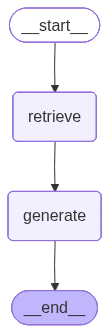

In [13]:
graph

In [14]:
test_query = "How will EVS impact oil demand in the next decade?"

result = graph.invoke({"query": test_query, "messages": []})

In [15]:
print("=== GENERATED RESPONSE ===")
print(result["generation"])

=== GENERATED RESPONSE ===
Short answer
EV adoption will reduce oil demand by the 2020s, but the effect through 2030 is likely to be moderate and highly uncertain — not a near-term collapse of oil demand or prices.

Key points from the report
- Scale of EV growth: industry projections put EV shares of new passenger + light‑commercial vehicle sales at roughly 40–60% by 2030. The EV fleet is projected to grow from ~40 million today to roughly 300–500 million by the early 2030s.
- Fleet inertia: there are ~1.4 billion passenger vehicles today, ~90 million new vehicle sales per year, and vehicle lifetimes of ~15–20 years (often longer in developing markets). This means the ICE fleet cannot be fully replaced within a decade — fleet turnover limits near‑term displacement.
- Quantified demand impact: under OPEC’s central scenario EVs displace only about 2–3 million barrels per day (mbpd) of oil by 2030 and oil demand may not peak until the late 2030s. Other agencies (e.g., IEA) are more bulli

In [16]:
print("\n=== RETRIEVED DOCUMENTS ===")
for i, doc in enumerate(result["retrieved_docs"], 1):
    source = doc.metadata.get("source", "unknown")
    page = doc.metadata.get("page", "?")
    snippet = doc.page_content[:500].replace("\n", " ")
    print(f"[{i}] Source: {source} | Page: {page}")
    print(f"    {snippet}...")


=== RETRIEVED DOCUMENTS ===
[1] Source: ../documents/evs_oil_price_shock.pdf | Page: 3
    Energy Agency, and McKinsey collectively project that EVs will account for between 40 and 60 percent of new vehicle sales globally by 2030. The stock of EVs on the road — which matters more than annual sales for oil displacement — is projected to grow from roughly 40 million vehicles today to between 300 and 500 million by the early 2030s. Whether this is sufficient to materially alter the oil price formation process is the central question this report addresses. 1.1 Scope and Methodology  This ...
[2] Source: ../documents/evs_oil_price_shock.pdf | Page: 7
    Will EVs Dampen the Oil Price Shock? Version 1.0 Research Report — For Educational and RAG Pipeline Use Page 8 4. EV Adoption Trajectories and Oil Demand Displacement  Projecting oil demand displacement from EV adoption requires integrating three distinct analytical layers: the annual sales trajectory for new EVs, the retirement rate of th

In [17]:
print(result["context"])

Energy Agency, and McKinsey collectively project that EVs will account for between 40 and
60 percent of new vehicle sales globally by 2030. The stock of EVs on the road — which
matters more than annual sales for oil displacement — is projected to grow from roughly 40
million vehicles today to between 300 and 500 million by the early 2030s. Whether this is
sufficient to materially alter the oil price formation process is the central question this report
addresses.
1.1 Scope and Methodology
 This report focuses on the relationship between passenger and light commercial vehicle
electrification and global oil demand dynamics. Heavy trucking, aviation, shipping, and
petrochemical feedstock demand — which collectively account for roughly 43 percent of oil
consumption — are not the primary subject of analysis, though their trajectories are

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pipeline Use
Page 8
4. EV Adoption Trajectories and Oil Demand 

## 5.2 01 Conditional Retrieval

*Source: `10_agentic_rag/notebooks/01_conditional_retrieval.ipynb`*

In [2]:
# Section 1 — Setup and Imports
from dotenv import load_dotenv
load_dotenv()

from typing import Literal
from pydantic import BaseModel
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langgraph.graph import StateGraph, START, END, MessagesState

In [3]:
# Section 2 — Document Loading
loader = PyPDFLoader("../documents/evs_oil_price_shock.pdf")
raw_docs = loader.load()

print(f"Loaded {len(raw_docs)} pages")

Loaded 15 pages


In [4]:
# Section 3 — Text Chunking
splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)
chunks = splitter.split_documents(raw_docs)

print(f"Split into {len(chunks)} chunks")

Split into 51 chunks


In [5]:
# Section 4 — Embedding Model
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

In [6]:
# in-memory only; re-running this cell re-embeds from scratch
vectorstore = Chroma(
    collection_name="rag_conditional",
    embedding_function=embeddings,
)

vectorstore.add_documents(documents=chunks)

retriever = vectorstore.as_retriever(search_kwargs={"k": 4})
print("Vector store ready")

Vector store ready


In [7]:
# Section 6 — LLM
llm = ChatOpenAI(model="gpt-5-mini")

In [8]:
# Section 7 — State Definition
class AgenticRAGState(MessagesState):
    
    query: str
    retrieved_docs: list[Document] | None
    context: str
    generation: str
    needs_retrieval: bool

In [9]:
# structured output schema for the routing decision
class RouteDecision(BaseModel):
    
    needs_retrieval: bool

In [10]:
# route_question node — classifies whether the query needs document retrieval
def route_question(state: AgenticRAGState) -> dict:
    
    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Classify whether the following question requires retrieving information from a specialized document, or can be answered from your own general knowledge."),
        ("human", "{query}"),
    ])
    
    chain = prompt_template | llm.with_structured_output(RouteDecision)
    decision = chain.invoke({"query": state["query"]})
    
    return {"needs_retrieval": decision.needs_retrieval}

In [11]:
# retrieve node — fetches relevant documents from the vector store
def retrieve(state: AgenticRAGState) -> dict:
    
    docs = retriever.invoke(state["query"])
    
    if docs:
        context = "\n\n".join(doc.page_content for doc in docs)

    return {"retrieved_docs": docs, "context": context}

In [12]:
# generate node — produces the final answer, with or without retrieved context
def generate(state: AgenticRAGState) -> dict:
    
    query = state["query"]
    context = state.get("context") or ""


    if context:    
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
            ("human", "{query}"),
        ])
        
        response = (prompt_template | llm).invoke({"context": context, "query": query})
    
    else:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        
        response = (prompt_template | llm).invoke({"query": query})

    return {"generation": response.content}

In [19]:
# routing function: maps needs_retrieval bool to the next node name
def route_after_classification(state: AgenticRAGState) -> Literal["retrieve", "generate"]:
    return "retrieve" if state["needs_retrieval"] else "generate"

In [20]:
# Graph Definition
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("needs_retrieval", route_question)
graph_builder.add_node("retrieve", retrieve)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "needs_retrieval")
graph_builder.add_conditional_edges("needs_retrieval", route_after_classification)
graph_builder.add_edge("retrieve", "generate")
graph_builder.add_edge("generate", END)

In [21]:
graph = graph_builder.compile()

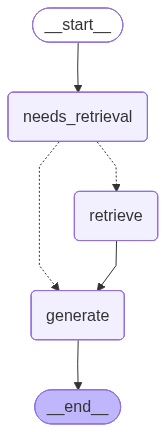

In [22]:
graph

In [23]:
# Query 1: domain-specific (should trigger retrieval)
domain_query = "What does the report say about EV adoption trajectories and oil demand displacement?"

result_domain = graph.invoke({"query": domain_query, "messages": []})

In [24]:
# Output: Query 1 (domain-specific)
print("=== QUERY 1 (domain-specific) ===")
print(f"Query          : {domain_query}")
print(f"needs_retrieval: {result_domain['needs_retrieval']}")
retrieved = result_domain.get("retrieved_docs") or []
print(f"Retrieved docs : {len(retrieved)} docs")
print(f"\nGeneration:\n{result_domain['generation']}")

=== QUERY 1 (domain-specific) ===
Query          : What does the report say about EV adoption trajectories and oil demand displacement?
needs_retrieval: True
Retrieved docs : 4 docs

Generation:
- The report says projecting oil demand displacement from EVs requires integrating three layers: annual new‑EV sales trajectories, retirement rates of the existing ICE fleet, and the mileage/fuel‑economy of the vehicles being displaced.

- The global passenger vehicle stock is about 1.4 billion (mostly ICE). With ~90 million new vehicle sales per year and 15–20 year vehicle lifetimes in developed markets (often longer in developing markets), full fleet electrification cannot happen quickly — it is constrained by turnover.

- Major forecasters (IEA, BloombergNEF, McKinsey) project EVs will make up roughly 40–60% of new vehicle sales by 2030. The EV stock is expected to grow from ~40 million today to about 300–500 million by the early 2030s.

- The report’s scope is passenger and light commercial

In [25]:
# Section 9 — Query 2: general knowledge (should skip retrieval)
general_query = "What is the capital of India?"

result_general = graph.invoke({"query": general_query, "messages": []})

In [26]:
# Output: Query 2 (general knowledge)
print("=== QUERY 2 (general knowledge) ===")
print(f"Query          : {general_query}")
print(f"needs_retrieval: {result_general['needs_retrieval']}")
print(f"Retrieved docs : {result_general.get('retrieved_docs')}")
print(f"\nGeneration:\n{result_general['generation']}")

=== QUERY 2 (general knowledge) ===
Query          : What is the capital of India?
needs_retrieval: False
Retrieved docs : None

Generation:
The capital of India is New Delhi.


## 5.3 02 Tool Use Retrieval 1

*Source: `10_agentic_rag/notebooks/02_tool_use_retrieval_1.ipynb`*

In [2]:
import os
import operator
from typing import Annotated, Literal
from pydantic import BaseModel
from tavily import TavilyClient
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
loader = PyPDFLoader("../documents/evs_oil_price_shock.pdf")
raw_docs = loader.load()

print(f"Loaded {len(raw_docs)} pages")

Loaded 15 pages


In [4]:
splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)
chunks = splitter.split_documents(raw_docs)

print(f"Split into {len(chunks)} chunks")

Split into 51 chunks


In [5]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

In [ ]:
# in-memory only; re-running this cell re-embeds from scratch
vectorstore = Chroma(
    collection_name="rag_tool_use",
    embedding_function=embeddings,
)

vectorstore.add_documents(documents=chunks)

print("Vector store ready")

Vector store ready


In [7]:
llm = ChatOpenAI(model="gpt-5-mini")        # route_question and generate

agent_llm = ChatOpenAI(model="gpt-5-mini")  # agent node; tools bound later

In [8]:
class AgenticRAGState(MessagesState):

    query: str
    retrieved_docs: Annotated[list[Document], operator.add]
    context: Annotated[str, operator.add]
    generation: str
    needs_retrieval: bool

In [9]:
class RouteDecision(BaseModel):

    needs_retrieval: bool

In [11]:
@tool(response_format="content_and_artifact")
def vector_store_search(query: str, k: int = 3):
    """Search the vector store for relevant document passages.
    Adjust k (default 3) to retrieve more or fewer passages."""
    
    retriever = vectorstore.as_retriever(search_kwargs={"k": k})
    docs = retriever.invoke(query)
    
    context = "\n\n## Vector Store Results\n\n" + "\n\n".join(d.page_content for d in docs)
    
    return context, docs

In [12]:
@tool(response_format="content_and_artifact")
def web_search(query: str, max_results: int = 3):
    """Search the web for current or real-time information.
    Adjust max_results (default 3) to control how many results are returned."""
    
    client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])
    response = client.search(query, max_results=max_results)
    
    docs = [
        Document(
            page_content=r["content"],
            metadata={"source": r["url"], "title": r.get("title", "")},
        )
        for r in response["results"]
    ]
    content = "\n\n## Web Search Results\n\n" + "\n\n".join(d.page_content for d in docs)
    return content, docs

In [13]:
tools = [vector_store_search, web_search]

agent_llm_with_tools = agent_llm.bind_tools(tools)

tool_node = ToolNode(tools)

In [14]:
# route_question node — classifies whether the query needs retrieval
def route_question(state: AgenticRAGState) -> dict:

    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Classify whether the following question requires retrieving information from a specialized document or the web, or can be answered from your own general knowledge."),
        ("human", "{query}"),
    ])

    chain = prompt_template | llm.with_structured_output(RouteDecision)
    decision = chain.invoke({"query": state["query"]})

    return {"needs_retrieval": decision.needs_retrieval}

In [15]:
AGENT_SYSTEM_PROMPT = (
    "You are a retrieval agent with access to two tools:\n\n"
    "1. vector_store_search — use this for questions that can be answered from the internal document: "
    "a technical report titled 'Will EVs Dampen the Oil Price Shock?' covering EV adoption trajectories, "
    "oil demand displacement scenarios, fleet turnover dynamics, battery cost trends, OPEC+ supply behavior, "
    "and energy price volatility projections through 2050. "
    "Use this tool whenever the query references the report, its findings, its projections, or any topic "
    "that would plausibly appear in a domain-specific EV/oil-market research document. "
    "You may increase k beyond the default if broader coverage of the document is needed.\n\n"
    "2. web_search — use this for current or real-time information not covered by the document, such as "
    "recent market data, news, or statistics from 2024 onward. "
    "Always rephrase the query into a concise, keyword-optimized web search string before calling this tool.\n\n"
    "You may call one tool, both tools, or no tool depending on what the query requires. "
    "When both document knowledge and current data are relevant, call both tools."
)

# agent node — decides which tool(s) to call based on the query
def agent(state: AgenticRAGState) -> dict:

    messages = state["messages"]
    if not messages:
        messages = [SystemMessage(content=AGENT_SYSTEM_PROMPT),
                    HumanMessage(content=state["query"])]

    response = agent_llm_with_tools.invoke(messages)

    return {"messages": [response]}

In [16]:
# collect_tool_output node — drains ToolMessages into state fields
def collect_tool_output(state: AgenticRAGState) -> dict:

    tool_messages = [m for m in state["messages"] if isinstance(m, ToolMessage)]
    all_docs, context_parts = [], []

    for msg in tool_messages:
        context_parts.append(msg.content)
        all_docs.extend(msg.artifact)

    return {
        "context": "\n\n".join(context_parts),
        "retrieved_docs": all_docs,
    }

In [17]:
# generate node — produces the final answer with or without retrieved context
def generate(state: AgenticRAGState) -> dict:

    query = state["query"]
    context = state.get("context") or ""

    if context:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"context": context, "query": query})

    else:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"query": query})

    return {"generation": response.content}

In [18]:
def route_after_classification(state: AgenticRAGState) -> Literal["agent", "generate"]:
    return "agent" if state["needs_retrieval"] else "generate"

def route_after_agent(state: AgenticRAGState) -> Literal["tools", "collect_tool_output"]:
    return "tools" if state["messages"][-1].tool_calls else "collect_tool_output"

In [19]:
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("route_question", route_question)
graph_builder.add_node("agent", agent)
graph_builder.add_node("tools", tool_node)
graph_builder.add_node("collect_tool_output", collect_tool_output)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "route_question")
graph_builder.add_conditional_edges("route_question", route_after_classification)
graph_builder.add_conditional_edges("agent", route_after_agent)
graph_builder.add_edge("tools", "agent")
graph_builder.add_edge("collect_tool_output", "generate")
graph_builder.add_edge("generate", END)

In [20]:
graph = graph_builder.compile()

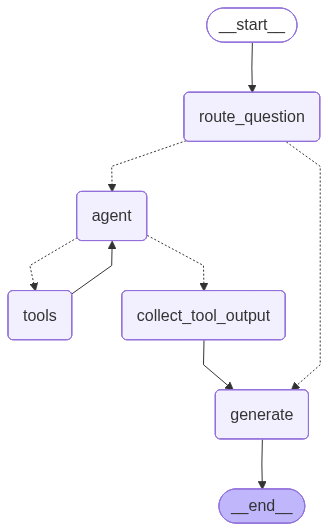

In [21]:
graph

In [22]:
# Case 1: vector store only — domain-specific question about the PDF
query_vs = "According to the report, how will the adoption of electric vehicles impact oil demand?"

result_vs = graph.invoke({"query": query_vs, "messages": [], "retrieved_docs": [], "context": ""})

In [21]:
print("=== CASE 1: Vector Store Only ===")
print(f"needs_retrieval : {result_vs['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_vs.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_vs.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_vs['generation']}")

=== CASE 1: Vector Store Only ===
needs_retrieval : True
retrieved_docs  : 8 docs
context preview : 

## Vector Store Results

Energy Agency, and McKinsey collectively project that EVs will account for between 40 and
60 ...

Generation:
In short: EV adoption will reduce oil demand but relatively gradually and only partially.

Key points from the report:
- EVs directly displace liquid fuel consumption (demand destruction): each EV replaces roughly 560 liters of gasoline per year (about 1 barrel of oil per month).
- Under a high-adoption pathway (≈300 million EVs by 2030), the report estimates roughly 4.6 million barrels per day of oil displaced by 2030 — meaningful but small against a ~100–105 mbpd global demand base.
- Passenger vehicle electrification targets a segment that represents about one-quarter of global oil demand (passenger cars ≈26 mbpd; light commercial ≈7–8 mbpd). Heavy trucking, aviation, shipping and petrochemicals (together ≈43% of consumption) are much harder to elect

In [23]:
print(result_vs["context"])



## Vector Store Results

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pipeline Use
Page 8
4. EV Adoption Trajectories and Oil Demand Displacement
 Projecting oil demand displacement from EV adoption requires integrating three distinct
analytical layers: the annual sales trajectory for new EVs, the retirement rate of the existing
ICE fleet, and the average annual mileage and fuel economy of the vehicles being displaced.
The total stock of passenger vehicles globally stands at approximately 1.4 billion, the vast
majority of which are ICE vehicles. With global new vehicle sales of roughly 90 million units
per year and average vehicle lifetimes of 15 to 20 years in developed markets — and often
longer in developing markets — complete fleet electrification cannot occur in less than two to

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pipeline Use
Page 3
Executive Summary
 The global transition towa

In [24]:
# Case 2: web search only — current information not in the PDF
query_web = "What is the current temperature in New Delhi?"

result_web = graph.invoke({"query": query_web, "messages": [], "retrieved_docs": [], "context": ""})

In [25]:
print("=== CASE 2: Web Search Only ===")
print(f"needs_retrieval : {result_web['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_web.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_web.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_web['generation']}")

=== CASE 2: Web Search Only ===
needs_retrieval : True
retrieved_docs  : 10 docs
context preview : 

## Web Search Results





## Web Search Results

New Delhi, DL, IN Current Weather. New Delhi, DL, IN. Updated 6 minu...

Generation:
The current temperature in New Delhi is 28°C.


In [32]:
# Case 3: both tools — requires document context AND current web data
query_both = "Compare what the EV report projects for 2030 oil demand and also tell me about the weather in mumbai"

result_both = graph.invoke({"query": query_both, "messages": [], "retrieved_docs": [], "context": ""})

In [33]:
print("=== CASE 3: Both Tools ===")
print(f"needs_retrieval : {result_both['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_both.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_both.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_both['generation']}")

=== CASE 3: Both Tools ===
needs_retrieval : True
retrieved_docs  : 10 docs
context preview : 

## Vector Store Results

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pi...

Generation:
Report: the provided EV report excerpts do not give a numeric 2030 global oil‑demand figure. Instead, its assessment for the early 2030s is qualitative: EV penetration becomes "economically material" in the early 2030s and will begin to reduce oil demand growth (first and most in advanced economies), but the report says the full oil‑price shock dampening dividend will be most pronounced after 2035. It also warns the 2024–2035 transition period may still be a time of elevated oil‑price risk (EVs reduce demand growth but do not yet provide a large buffer vs. supply shocks), and recommends pursuing EVs alongside other hedging measures (strategic reserves, efficiency, fuel switching).

Mumbai weather (from the provided data, local time 2026-04-23 16:31):
- Curren

In [34]:
print(result_both["context"])



## Vector Store Results

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pipeline Use
Page 8
4. EV Adoption Trajectories and Oil Demand Displacement
 Projecting oil demand displacement from EV adoption requires integrating three distinct
analytical layers: the annual sales trajectory for new EVs, the retirement rate of the existing
ICE fleet, and the average annual mileage and fuel economy of the vehicles being displaced.
The total stock of passenger vehicles globally stands at approximately 1.4 billion, the vast
majority of which are ICE vehicles. With global new vehicle sales of roughly 90 million units
per year and average vehicle lifetimes of 15 to 20 years in developed markets — and often
longer in developing markets — complete fleet electrification cannot occur in less than two to

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pipeline Use
Page 15
 The net assessment is that EV adoption is a

In [35]:
# Case 4: no retrieval — answerable from general knowledge
query_none = "Explain the difference between kinetic energy and potential energy."

result_none = graph.invoke({"query": query_none, "messages": [], "retrieved_docs": [], "context": ""})

In [36]:
print("=== CASE 4: No Retrieval ===")
print(f"needs_retrieval : {result_none['needs_retrieval']}")
print(f"retrieved_docs  : {len(result_none.get('retrieved_docs') or [])} docs")
print(f"context preview : {result_none.get('context', '') or '(none)'}")
print(f"\nGeneration:\n{result_none['generation']}")

=== CASE 4: No Retrieval ===
needs_retrieval : False
retrieved_docs  : 0 docs
context preview : (none)

Generation:
Kinetic energy and potential energy are two forms of mechanical energy; they differ in what they depend on and how they can change.

Kinetic energy (KE)
- Definition: energy of motion.
- Depends on: an object’s mass and speed.
- Common formula (translational): KE = 1/2 m v^2 (m = mass, v = speed).
- Other forms: rotational KE = 1/2 I ω^2 (I = moment of inertia, ω = angular speed).
- Example: a moving car or a thrown ball has kinetic energy.

Potential energy (PE)
- Definition: energy stored because of an object’s position, configuration, or state in a force field.
- Depends on: position/configuration relative to a reference point (and on the type of force field).
- Common formulas:
  - Near Earth’s surface: PE_grav = m g h (m = mass, g = gravitational acceleration, h = height above reference).
  - For springs: PE_elastic = 1/2 k x^2 (k = spring constant, x = displacement)

In [52]:
result_both["messages"][0].tool_calls

[{'name': 'vector_store_search',
  'args': {'query': "2030 oil demand projection EV adoption 2030 'Will EVs Dampen the Oil Price Shock?'",
   'k': 5},
  'id': 'call_JfRoDCehvTrzlurXPKbchTQR',
  'type': 'tool_call'},
 {'name': 'web_search',
  'args': {'query': 'Mumbai current weather', 'max_results': 5},
  'id': 'call_arueE31Rc5zWNrzXOSgdjCiz',
  'type': 'tool_call'}]

## 5.4 03 Tool Use Retrieval 2

*Source: `10_agentic_rag/notebooks/03_tool_use_retrieval_2.ipynb`*

In [1]:
import os
import operator
from typing import Annotated, Literal
from pydantic import BaseModel
from tavily import TavilyClient
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
loader = PyPDFLoader("../documents/evs_oil_price_shock.pdf")
raw_docs = loader.load()

print(f"Loaded {len(raw_docs)} pages")

Loaded 15 pages


In [3]:
splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)
chunks = splitter.split_documents(raw_docs)

print(f"Split into {len(chunks)} chunks")

Split into 51 chunks


In [4]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

In [ ]:
# in-memory only; re-running this cell re-embeds from scratch
vectorstore = Chroma(
    collection_name="rag_eval_retry",
    embedding_function=embeddings,
)

vectorstore.add_documents(documents=chunks)

print("Vector store ready")

In [6]:
llm = ChatOpenAI(model="gpt-5-mini")        # route_question and generate

agent_llm = ChatOpenAI(model="gpt-5-mini")  # agent node; tools bound later

In [7]:
class AgenticRAGState(MessagesState):

    query: str
    retrieved_docs: Annotated[list[Document], operator.add]
    context: Annotated[str, operator.add]
    generation: str
    needs_retrieval: bool
    retrieval_count: int       # incremented after each tool-call round
    max_retrieval_steps: int   # cap on tool-call rounds before forcing generate

In [8]:
class RouteDecision(BaseModel):

    needs_retrieval: bool

In [9]:
@tool(response_format="content_and_artifact")
def vector_store_search(query: str, k: int = 3):
    """Search the vector store for relevant document passages.
    Adjust k (default 3) to retrieve more or fewer passages."""
    
    docs = vectorstore.similarity_search(query, k=k)
    context = "\n\n## Vector Store Results\n\n" + "\n\n".join(d.page_content for d in docs)
    
    return context, docs

In [10]:
@tool(response_format="content_and_artifact")
def web_search(query: str, max_results: int = 3):
    """Search the web for current or real-time information.
    Adjust max_results (default 3) to control how many results are returned."""
    
    client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])
    response = client.search(query, max_results=max_results)
    
    docs = [
        Document(
            page_content=r["content"],
            metadata={"source": r["url"], "title": r.get("title", "")},
        )
        for r in response["results"]
    ]
    content = "\n\n## Web Search Results\n\n" + "\n\n".join(d.page_content for d in docs)
    return content, docs

In [11]:
tools = [vector_store_search, web_search]

agent_llm_with_tools = agent_llm.bind_tools(tools)

tool_node = ToolNode(tools)

In [12]:
# route_question node — classifies whether the query needs retrieval
def route_question(state: AgenticRAGState) -> dict:

    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Classify whether the following question requires retrieving information from a specialized document or the web, or can be answered from your own general knowledge."),
        ("human", "{query}"),
    ])

    chain = prompt_template | llm.with_structured_output(RouteDecision)
    decision = chain.invoke({"query": state["query"]})

    return {"needs_retrieval": decision.needs_retrieval}

In [13]:
AGENT_SYSTEM_PROMPT = (
    "You are a retrieval agent with access to two tools:\n\n"
    "1. vector_store_search — use this for questions that can be answered from the internal document: "
    "a technical report titled 'Will EVs Dampen the Oil Price Shock?' covering EV adoption trajectories, "
    "oil demand displacement scenarios, fleet turnover dynamics, battery cost trends, OPEC+ supply behavior, "
    "and energy price volatility projections through 2050. "
    "Use this tool whenever the query references the report, its findings, its projections, or any topic "
    "that would plausibly appear in a domain-specific EV/oil-market research document. "
    "You may increase k beyond the default if broader coverage of the document is needed.\n\n"
    "2. web_search — use this for current or real-time information not covered by the document, such as "
    "recent market data, news, or statistics from 2024 onward. "
    "Always rephrase the query into a concise, keyword-optimized web search string before calling this tool.\n\n"
    "You may call one tool, both tools, or no tool depending on what the query requires. "
    "When both document knowledge and current data are relevant, call both tools."
)

# agent node — decides which tool(s) to call based on the query
def agent(state: AgenticRAGState) -> dict:

    messages = state["messages"]
    if not messages:
        messages = [SystemMessage(content=AGENT_SYSTEM_PROMPT),
                    HumanMessage(content=state["query"])]

    response = agent_llm_with_tools.invoke(messages)

    return {"messages": [response]}

In [14]:
# collect_tool_output node — drains ToolMessages into state fields
def collect_tool_output(state: AgenticRAGState) -> dict:

    tool_messages = [m for m in state["messages"] if isinstance(m, ToolMessage)]
    all_docs, context_parts = [], []

    for msg in tool_messages:
        context_parts.append(msg.content)
        all_docs.extend(msg.artifact)

    return {
        "context": "\n\n".join(context_parts),
        "retrieved_docs": all_docs,
    }

In [15]:
# generate node — produces the final answer with or without retrieved context
def generate(state: AgenticRAGState) -> dict:

    query = state["query"]
    context = state.get("context") or ""

    if context:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"context": context, "query": query})

    else:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"query": query})

    return {"generation": response.content}

In [17]:
# check_retrieval_limit node — increments the retrieval counter after each tool round
def check_retrieval_limit(state: AgenticRAGState) -> dict:
    count = state.get("retrieval_count", 0)
    
    return {"retrieval_count": count + 1}

In [18]:
def route_after_classification(state: AgenticRAGState) -> Literal["agent", "generate"]:
    return "agent" if state["needs_retrieval"] else "generate"

def route_after_agent(state: AgenticRAGState) -> Literal["tools", "collect_tool_output"]:
    return "tools" if state["messages"][-1].tool_calls else "collect_tool_output"

def route_after_limit_check(state: AgenticRAGState) -> Literal["agent", "collect_tool_output"]:
    return "collect_tool_output" if state["retrieval_count"] >= state["max_retrieval_steps"] else "agent"

In [19]:
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("route_question", route_question)
graph_builder.add_node("agent", agent)
graph_builder.add_node("tools", tool_node)
graph_builder.add_node("check_retrieval_limit", check_retrieval_limit)
graph_builder.add_node("collect_tool_output", collect_tool_output)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "route_question")
graph_builder.add_conditional_edges("route_question", route_after_classification)
graph_builder.add_conditional_edges("agent", route_after_agent)
graph_builder.add_edge("tools", "check_retrieval_limit")
graph_builder.add_conditional_edges("check_retrieval_limit", route_after_limit_check)
graph_builder.add_edge("collect_tool_output", "generate")
graph_builder.add_edge("generate", END)

In [20]:
graph = graph_builder.compile()

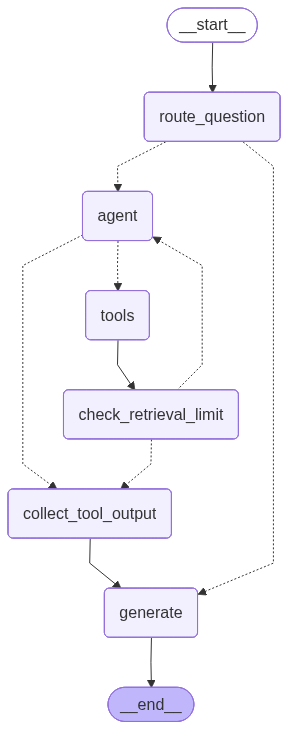

In [21]:
graph

In [22]:
# Case 1: vector store only — domain-specific question about the PDF
query_vs = "According to the report, how will the adoption of electric vehicles impact oil demand?"

result_vs = graph.invoke({"query": query_vs, "messages": [], "retrieved_docs": [], "context": "", "retrieval_count": 0, "max_retrieval_steps": 5})

In [23]:
print("=== CASE 1: Vector Store Only ===")
print(f"needs_retrieval  : {result_vs['needs_retrieval']}")
print(f"retrieval_count  : {result_vs['retrieval_count']}")
print(f"retrieved_docs   : {len(result_vs.get('retrieved_docs') or [])} docs")
print(f"context preview  : {result_vs.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_vs['generation']}")

=== CASE 1: Vector Store Only ===
needs_retrieval  : True
retrieval_count  : 1
retrieved_docs   : 6 docs
context preview  : 

## Vector Store Results

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pi...

Generation:
Briefly, the report says EV adoption will reduce oil demand but not quickly or uniformly:

- EVs primarily displace gasoline demand from passenger cars; diesel (trucks, buses, equipment) is much harder to electrify.  
- By flattening or reversing road-transport demand growth, EVs raise the chance that global spare capacity stays above the 2–3 million barrels/day buffer, so the marginal (near‑term) effect on price dynamics can be important even if aggregate displacement is modest.  
- Full fleet turnover is slow (global stock ~1.4 billion vehicles; ~90 million new cars/year; typical lifetimes 15–20+ years), so substantial demand reduction is gradual and will be most pronounced after ~2035 and first in advanced economies.  
- There

In [24]:
# Case 2: web search only — current information not in the PDF
query_web = "What is the current temperature in New Delhi?"

result_web = graph.invoke({"query": query_web, "messages": [], "retrieved_docs": [], "context": "", "retrieval_count": 0, "max_retrieval_steps": 5})

In [25]:
print("=== CASE 2: Web Search Only ===")
print(f"needs_retrieval  : {result_web['needs_retrieval']}")
print(f"retrieval_count  : {result_web['retrieval_count']}")
print(f"retrieved_docs   : {len(result_web.get('retrieved_docs') or [])} docs")
print(f"context preview  : {result_web.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_web['generation']}")

=== CASE 2: Web Search Only ===
needs_retrieval  : True
retrieval_count  : 1
retrieved_docs   : 3 docs
context preview  : 

## Web Search Results

{'location': {'name': 'New Delhi', 'region': 'Delhi', 'country': 'India', 'lat': 28.6, 'lon': 7...

Generation:
The current temperature in New Delhi is 38.0°C (100.4°F).


In [26]:
# Case 3: both tools — requires document context AND current web data
query_both = "Compare what the EV report projects for 2030 oil demand with current oil demand due to Iran-US War."

result_both = graph.invoke({"query": query_both, "messages": [], "retrieved_docs": [], "context": "", "retrieval_count": 0, "max_retrieval_steps": 5})

In [27]:
print("=== CASE 3: Both Tools ===")
print(f"needs_retrieval  : {result_both['needs_retrieval']}")
print(f"retrieval_count  : {result_both['retrieval_count']}")
print(f"retrieved_docs   : {len(result_both.get('retrieved_docs') or [])} docs")
print(f"context preview  : {result_both.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_both['generation']}")

=== CASE 3: Both Tools ===
needs_retrieval  : True
retrieval_count  : 1
retrieved_docs   : 10 docs
context preview  : 

## Vector Store Results

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pi...

Generation:
Short answer: the EV report excerpts provided do not give a specific numeric global oil‑demand projection for 2030. They describe a gradual, structural demand reduction from accelerating EV adoption that becomes economically material in the early 2030s and that can flatten or reverse demand growth (especially gasoline), increasing the chance that spare capacity stays above a 2–3 million barrels‑per‑day insurance threshold. By contrast, the Iran–US war effects described in the web snippets are an immediate near‑term shock: the IEA sees a small demand decline of about 80,000 bpd in 2026 and a much larger change versus pre‑war forecasts (the web result cites global demand being almost 1 million bpd less than forecast before the Iran war),

In [30]:
# Case 3b: multi-round retrieval — query designed to trigger iterative tool calls
# The agent is expected to: (1) search the vector store for report projections,
# then (2) search the web for current data, then (3) search again to fill any gaps.
query_multi = (
    "Step 1: Look up what the EV report projects for oil demand displacement by 2030 and 2050. "
    "Step 2: Search for the latest 2024-2025 EV sales data and battery cost trends. "
    "Step 3: Search for any recent analyst forecasts that revise those oil demand projections upward or downward. "
    "Synthesize all three into a coherent answer."
)

result_multi = graph.invoke({"query": query_multi, "messages": [], "retrieved_docs": [], "context": "", "retrieval_count": 0, "max_retrieval_steps": 5})

In [32]:
print("=== CASE 3b: Multi-Round Retrieval ===")
print(f"needs_retrieval  : {result_multi['needs_retrieval']}")
print(f"retrieval_count  : {result_multi['retrieval_count']}")
print(f"retrieved_docs   : {len(result_multi.get('retrieved_docs') or [])} docs")
print(f"context preview  : {result_multi.get('context', '')[:120]}...")
print(f"\nGeneration:\n{result_multi['generation']}")

=== CASE 3b: Multi-Round Retrieval ===
needs_retrieval  : True
retrieval_count  : 2
retrieved_docs   : 10 docs
context preview  : 

## Vector Store Results

Will EVs Dampen the Oil Price Shock?
Version 1.0
Research Report — For Educational and RAG Pi...

Generation:
Short answer up front
- The provided EV report excerpts do not give explicit numeric oil‑displacement projections for 2030 or 2050.  
- External material included in the context (IEA snippets in the web results) gives a mid‑single‑million barrels/day reduction by 2030 (roughly 5–6 mb/d) and larger reductions by the mid‑2030s (cited ~13 mb/d by 2035), but also an IEA framing that total oil demand may only be down ~8% by 2050 versus 2024.  
- The report emphasizes (qualitatively) that EVs will mainly displace gasoline (passenger cars), diesel is harder to electrify, fleet turnover takes decades, and outcomes depend heavily on emerging‑market vehicle growth and OPEC+ production policy.

Step 1 — What the EV report (Will EVs Da

In [28]:
# Case 4: no retrieval — answerable from general knowledge
query_none = "Explain the difference between kinetic energy and potential energy."

result_none = graph.invoke({"query": query_none, "messages": [], "retrieved_docs": [], "context": "", "retrieval_count": 0, "max_retrieval_steps": 5})

In [29]:
print("=== CASE 4: No Retrieval ===")
print(f"needs_retrieval  : {result_none['needs_retrieval']}")
print(f"retrieval_count  : {result_none['retrieval_count']}")
print(f"retrieved_docs   : {len(result_none.get('retrieved_docs') or [])} docs")
print(f"context preview  : {result_none.get('context', '') or '(none)'}")
print(f"\nGeneration:\n{result_none['generation']}")

=== CASE 4: No Retrieval ===
needs_retrieval  : False
retrieval_count  : 0
retrieved_docs   : 0 docs
context preview  : (none)

Generation:
Kinetic energy and potential energy are two basic forms of mechanical energy. The main difference is that kinetic energy is energy of motion, while potential energy is stored energy due to an object's position or configuration.

Key points

- Kinetic energy (KE)
  - Definition: energy an object has because of its motion.
  - Formula (linear): KE = 1/2 · m · v^2, where m is mass and v is speed.
  - Also exists for rotation: KE_rot = 1/2 · I · ω^2 (I = moment of inertia, ω = angular speed).
  - Depends only on mass and speed; always nonnegative.
  - Example: a moving car, a flying baseball, or a spinning wheel.

- Potential energy (PE)
  - Definition: energy stored in an object because of its position in a force field or its configuration.
  - Common forms and formulas:
    - Gravitational near Earth: PE = m · g · h (h = height above chosen reference

## 5.5 04 Retrieval Evaluation And Rewriting

*Source: `10_agentic_rag/notebooks/04_retrieval_evaluation_and_rewriting.ipynb`*

In [1]:
import os
from typing import Literal
from pydantic import BaseModel
from tavily import TavilyClient
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
loader = PyPDFLoader("../documents/evs_oil_price_shock.pdf")
raw_docs = loader.load()
print(f"Loaded {len(raw_docs)} pages")

Loaded 15 pages


In [3]:
splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)
chunks = splitter.split_documents(raw_docs)
print(f"Split into {len(chunks)} chunks")

Split into 51 chunks


In [4]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

In [5]:
vectorstore = Chroma(
    collection_name="rag_rewriting",
    embedding_function=embeddings,
)

vectorstore.add_documents(documents=chunks)

print("Vector store ready")

Vector store ready


In [6]:
llm = ChatOpenAI(model="gpt-5-mini")

agent_llm = ChatOpenAI(model="gpt-5-mini")

In [7]:
class AgenticRAGState(MessagesState):
    
    query: str
    retrieved_docs: list[Document]
    relevant_docs: list[Document]
    context: str
    generation: str
    needs_retrieval: bool
    retrieval_count: int
    max_retrieval_steps: int
    is_relevant: bool
    rewritten_query: str  
    rewrite_count: int    

In [8]:
class RouteDecision(BaseModel):
    
    needs_retrieval: bool

In [9]:
class RelevanceEvaluation(BaseModel):
    
    is_relevant: bool

In [10]:
@tool(response_format="content_and_artifact")
def vector_store_search(query: str, k: int = 3):
    """Search the vector store for relevant document passages.
    Adjust k (default 3) to retrieve more or fewer passages."""
    
    docs = vectorstore.similarity_search(query, k=k)
    context = "\n\n## Vector Store Results\n\n" + "\n\n".join(d.page_content for d in docs)

    return context, docs

In [11]:
@tool(response_format="content_and_artifact")
def web_search(query: str, max_results: int = 3):
    """Search the web for current or real-time information.
    Adjust max_results (default 3) to control how many results are returned."""
    
    client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])
    
    response = client.search(query, max_results=max_results)
    
    docs = [
        Document(
            page_content=r["content"],
            metadata={"source": r["url"], "title": r.get("title", "")},
        )
        for r in response["results"]
    ]
    
    content = "\n\n## Web Search Results\n\n" + "\n\n".join(d.page_content for d in docs)
    
    return content, docs

In [12]:
tools = [vector_store_search, web_search]

agent_llm_with_tools = agent_llm.bind_tools(tools)

tool_node = ToolNode(tools)

In [13]:
def route_question(state: AgenticRAGState) -> dict:
    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Classify whether the following question requires retrieving information from a specialized document or the web, or can be answered from your own general knowledge."),
        ("human", "{query}"),
    ])
    
    chain = prompt_template | llm.with_structured_output(RouteDecision)
    decision = chain.invoke({"query": state["query"]})
    
    return {"needs_retrieval": decision.needs_retrieval}

In [14]:
AGENT_SYSTEM_PROMPT = (
    "You are a retrieval agent with access to two tools:\n\n"
    "1. vector_store_search — use this for questions that can be answered from the internal document: "
    "a technical report titled 'Will EVs Dampen the Oil Price Shock?' covering EV adoption trajectories, "
    "oil demand displacement scenarios, fleet turnover dynamics, battery cost trends, OPEC+ supply behavior, "
    "and energy price volatility projections through 2050. "
    "Use this tool whenever the query references the report, its findings, its projections, or any topic "
    "that would plausibly appear in a domain-specific EV/oil-market research document. "
    "You may increase k beyond the default if broader coverage of the document is needed.\n\n"
    "2. web_search — use this for current or real-time information not covered by the document, such as "
    "recent market data, news, or statistics from 2024 onward. "
    "Always rephrase the query into a concise, keyword-optimized web search string before calling this tool.\n\n"
    "You may call one tool, both tools, or no tool depending on what the query requires. "
    "When both document knowledge and current data are relevant, call both tools."
)

def agent(state: AgenticRAGState) -> dict:
    # use rewritten_query if available to start a fresh retrieval cycle
    rewritten = state.get("rewritten_query")
    
    if rewritten:
        messages = [
            SystemMessage(content=AGENT_SYSTEM_PROMPT),
            HumanMessage(content=rewritten),
        ]
    
    else:
        messages = state["messages"]
        if not messages:
            messages = [
                SystemMessage(content=AGENT_SYSTEM_PROMPT),
                HumanMessage(content=state["query"]),
            ]
    
    response = agent_llm_with_tools.invoke(messages)
    return {"messages": [response]}

In [15]:
def collect_tool_output(state: AgenticRAGState) -> dict:
    all_docs = []
    for msg in reversed(state["messages"]):
        if isinstance(msg, HumanMessage):
            break
        if isinstance(msg, ToolMessage):
            all_docs.extend(msg.artifact)
    all_docs.reverse()
    return {"retrieved_docs": all_docs}

In [16]:
def evaluate_docs(state: AgenticRAGState) -> dict:
    docs = state.get("retrieved_docs") or []
    if not docs:
        return {"is_relevant": False, "relevant_docs": [], "context": ""}

    active_query = state.get("rewritten_query") or state["query"]

    prompt_template = ChatPromptTemplate.from_messages([
        (
            "system",
            "You are a relevance evaluator. Given a user query and a single document passage, "
            "determine whether the passage contains useful information to answer the query. "
            "Return is_relevant=True only if the passage directly addresses the query with specific facts or analysis. "
            "Return is_relevant=False if it is off-topic, too vague, or does not help answer the query."
        ),
        ("human", "Query: {query}\n\nDocument passage:\n{doc}"),
    ])
    chain = prompt_template | llm.with_structured_output(RelevanceEvaluation)

    relevant_docs = []
    for doc in docs:
        result = chain.invoke({"query": active_query, "doc": doc.page_content})
        if result.is_relevant:
            relevant_docs.append(doc)

    is_relevant = len(relevant_docs) > 0
    
    context = "\n\n".join(d.page_content for d in relevant_docs)

    return {"is_relevant": is_relevant, "relevant_docs": relevant_docs, "context": context}

In [17]:
def rewrite_query(state: AgenticRAGState) -> dict:
    count = state.get("rewrite_count", 0)

    prompt_template = ChatPromptTemplate.from_messages([
        (
            "system",
            "You are a query rewriting assistant. A retrieval system searched for information to answer the user's "
            "query but none of the retrieved documents were relevant. Your task is to rewrite the query to be more "
            "specific, use different terminology, or focus on a narrower aspect that is more likely to match "
            "content in the knowledge source. Return only the rewritten query string."
        ),
        ("human", "Original query: {query}\n\nRewritten query:"),
    ])
    
    chain = prompt_template | llm
    response = chain.invoke({"query": state["query"]})
    new_query = response.content.strip()

    return {"rewritten_query": new_query, "rewrite_count": count + 1}

In [18]:
def generate(state: AgenticRAGState) -> dict:
    # no-answer fallback when all rewrite attempts are exhausted with no relevant docs
    if state.get("rewrite_count", 0) >= 3 and not state.get("is_relevant"):
        return {
            "generation": (
                "I was unable to find relevant information to answer your query after multiple retrieval attempts. "
                "The knowledge source does not appear to contain content that addresses this question."
            )
        }

    query = state["query"]
    context = state.get("context") or ""

    if context:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"context": context, "query": query})
    else:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"query": query})

    return {"generation": response.content}

In [19]:
def check_retrieval_limit(state: AgenticRAGState) -> dict:
    count = state.get("retrieval_count", 0)
    return {"retrieval_count": count + 1}

In [20]:
def route_after_classification(state: AgenticRAGState) -> Literal["agent", "generate"]:
    return "agent" if state["needs_retrieval"] else "generate"

def route_after_agent(state: AgenticRAGState) -> Literal["tools", "collect_tool_output"]:
    return "tools" if state["messages"][-1].tool_calls else "collect_tool_output"

def route_after_limit_check(state: AgenticRAGState) -> Literal["agent", "collect_tool_output"]:
    return "collect_tool_output" if state["retrieval_count"] >= state["max_retrieval_steps"] else "agent"

def route_after_evaluation(state: AgenticRAGState) -> Literal["generate", "rewrite_query"]:
    return "generate" if state["is_relevant"] else "rewrite_query"

def route_after_rewrite(state: AgenticRAGState) -> Literal["agent", "generate"]:
    return "generate" if state.get("rewrite_count", 0) >= 3 else "agent"

In [21]:
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("route_question", route_question)
graph_builder.add_node("agent", agent)
graph_builder.add_node("tools", tool_node)
graph_builder.add_node("check_retrieval_limit", check_retrieval_limit)
graph_builder.add_node("collect_tool_output", collect_tool_output)
graph_builder.add_node("evaluate_docs", evaluate_docs)
graph_builder.add_node("rewrite_query", rewrite_query)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "route_question")
graph_builder.add_conditional_edges("route_question", route_after_classification)
graph_builder.add_conditional_edges("agent", route_after_agent)
graph_builder.add_edge("tools", "check_retrieval_limit")
graph_builder.add_conditional_edges("check_retrieval_limit", route_after_limit_check)
graph_builder.add_edge("collect_tool_output", "evaluate_docs")
graph_builder.add_conditional_edges("evaluate_docs", route_after_evaluation)
graph_builder.add_conditional_edges("rewrite_query", route_after_rewrite)
graph_builder.add_edge("generate", END)

In [22]:
graph = graph_builder.compile()

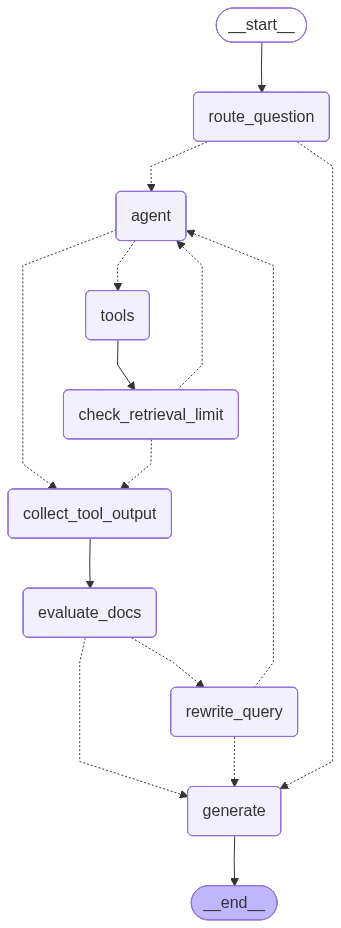

In [23]:
graph

In [ ]:
query_1 = (
    "According to the report, by how many million barrels per day could a 300-million EV fleet "
    "displace oil demand by 2030, and what does this mean relative to total global demand?"
)

result_1 = graph.invoke({
    "query": query_1,
    "messages": [],
    "retrieved_docs": [],
    "relevant_docs": [],
    "context": "",
    "retrieval_count": 0,
    "max_retrieval_steps": 3,
    "rewrite_count": 0,
    "rewritten_query": "",
})

print("=== Case 1: Specific domain query ===")
print("Is relevant:", result_1.get("is_relevant"))
print("Relevant docs count:", len(result_1.get("relevant_docs") or []))
print("Rewrite count:", result_1.get("rewrite_count"))
print("\nGeneration:\n", result_1.get("generation"))

=== Case 1: Specific domain query ===
Is relevant: True
Relevant docs count: 5
Rewrite count: 1

Generation:
 The report says a 300‑million EV fleet would displace about 4.6 million barrels per day by 2030 — a meaningful but not transformative cut, roughly 4–4.6% of global oil demand (against a 100–105 million b/d base).


In [34]:
print(result_1["query"])

According to the report, by how many million barrels per day could a 300-million EV fleet displace oil demand by 2030, and what does this mean relative to total global demand?


In [35]:
print(result_1["rewritten_query"])

How many million barrels per day (mb/d) of oil demand could a global fleet of 300 million electric vehicles displace by 2030, and what percentage or share of projected total global oil demand in 2030 would that represent?


In [33]:
query_2 = (
    "how long people take to get rid of their vehicles completely as per the report?"
)

result_2 = graph.invoke({
    "query": query_2,
    "messages": [],
    "retrieved_docs": [],
    "relevant_docs": [],
    "context": "",
    "retrieval_count": 0,
    "max_retrieval_steps": 3,
    "rewrite_count": 0,
    "rewritten_query": "",
})

print("=== Case 2: Informal query — rewrite then succeeds ===")
print("Is relevant:", result_2.get("is_relevant"))
print("Relevant docs count:", len(result_2.get("relevant_docs") or []))
print("Rewrite count:", result_2.get("rewrite_count"))
print("Rewritten query:", result_2.get("rewritten_query"))
print("\nGeneration:\n", result_2.get("generation"))

=== Case 2: Informal query — rewrite then succeeds ===
Is relevant: True
Relevant docs count: 1
Rewrite count: 0
Rewritten query: 

Generation:
 The report states average vehicle lifetimes are about 15 to 20 years in developed markets — and often longer in developing markets.


In [ ]:
query_3 = "What does the report/document say about nuclear power?"

result_3 = graph.invoke({
    "query": query_3,
    "messages": [],
    "retrieved_docs": [],
    "relevant_docs": [],
    "context": "",
    "retrieval_count": 0,
    "max_retrieval_steps": 3,
    "rewrite_count": 0,
    "rewritten_query": "",
})

print("=== Case 3: Off-topic query — max rewrites exhausted ===")
print("Is relevant:", result_3.get("is_relevant"))
print("Relevant docs count:", len(result_3.get("relevant_docs") or []))
print("Rewrite count:", result_3.get("rewrite_count"))
print("Rewritten query:", result_3.get("rewritten_query"))
print("\nGeneration:\n", result_3.get("generation"))

=== Case 3: Off-topic query — max rewrites exhausted ===
Is relevant: True
Relevant docs count: 1
Rewrite count: 2
Rewritten query: According to the report/document, what conclusions or recommendations are made about nuclear power—specifically regarding its role in decarbonization, safety and accident risk, costs (capital and levelized), radioactive waste management, and policy/timeline recommendations?

Generation:
 The IPCC AR6-WG3 report identifies nuclear energy as one of the three available energy sources—along with wind and solar—that can mitigate climate change by delivering net carbon reductions while also providing net cost savings (SPM.7). The full report did not model potential future cost reductions for advanced nuclear reactors (unlike for some other technologies), but despite that omission it nonetheless highlights nuclear as an important climate-change mitigation strategy. The report’s findings are used to argue that countries should include nuclear in the energy mix nee

In [36]:
print(result_3["relevant_docs"])

[Document(metadata={'source': 'https://nuclearinnovationalliance.org/global-climate-change-mitigation-and-critical-role-nuclear-energy-assessing-intergovernmental-panel', 'title': 'Global Climate Change Mitigation and the Critical Role of Nuclear ...'}, page_content='# Global Climate Change Mitigation and the Critical Role of Nuclear Energy: Assessing the Intergovernmental Panel on Climate Change, AR6-WG3 Report. If not, and current policies are maintained through 2030, it will become “impossible to limit warming to 1.5°C.” The report identified that wind, solar, and nuclear energy are the three available energy sources to mitigate climate change through net carbon reductions and also provide net cost savings (SPM.7). Despite the full Report not considering the potential future cost reductions for advanced reactor technology, as it did for other technologies like carbon capture and renewables, it is significant that nuclear energy was nonetheless identified as an important climate chan

In [37]:
print(len(result_3["retrieved_docs"]))

54


In [ ]:
query_4 = "What is the chemical symbol for lithium and what group of the periodic table does it belong to?"

result_4 = graph.invoke({
    "query": query_4,
    "messages": [],
    "retrieved_docs": [],
    "relevant_docs": [],
    "context": "",
    "retrieval_count": 0,
    "max_retrieval_steps": 3,
    "rewrite_count": 0,
    "rewritten_query": "",
})

print("=== Case 4: General knowledge — no retrieval ===")
print("Needs retrieval:", result_4.get("needs_retrieval"))
print("Is relevant:", result_4.get("is_relevant"))
print("Rewrite count:", result_4.get("rewrite_count"))
print("\nGeneration:\n", result_4.get("generation"))

=== Case 4: General knowledge — no retrieval ===
Needs retrieval: False
Is relevant: None
Rewrite count: 0

Generation:
 The chemical symbol for lithium is Li. It belongs to Group 1 of the periodic table — the alkali metals.


## 5.6 05 Query Decomposition

*Source: `10_agentic_rag/notebooks/05_query_decomposition.ipynb`*

In [1]:
import os
from typing import Literal
from pydantic import BaseModel
from tavily import TavilyClient
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
loader = PyPDFLoader("../documents/evs_oil_price_shock.pdf")
raw_docs = loader.load()
print(f"Loaded {len(raw_docs)} pages")

Loaded 15 pages


In [3]:
splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)
chunks = splitter.split_documents(raw_docs)
print(f"Split into {len(chunks)} chunks")

Split into 51 chunks


In [4]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

In [5]:
vectorstore = Chroma(
    collection_name="rag_decomposition",
    embedding_function=embeddings,
)
vectorstore.add_documents(documents=chunks)
print("Vector store ready")

Vector store ready


In [6]:
llm = ChatOpenAI(model="gpt-5-mini")
agent_llm = ChatOpenAI(model="gpt-5-mini")

In [7]:
class AgenticRAGState(MessagesState):
    
    query: str
    retrieved_docs: list[Document]
    relevant_docs: list[Document]
    context: str
    generation: str
    needs_retrieval: bool
    retrieval_count: int
    max_retrieval_steps: int
    is_relevant: bool
    rewritten_query: str  
    rewrite_count: int    
    needs_decomposition: bool

In [8]:
class RouteDecision(BaseModel):
    needs_retrieval: bool

In [9]:
class RelevanceEvaluation(BaseModel):
    is_relevant: bool

In [10]:
class DecompositionDecision(BaseModel):
    needs_decomposition: bool
    sub_queries: list[str]  # empty list when needs_decomposition=False

In [11]:
@tool(response_format="content_and_artifact")
def vector_store_search(query: str, k: int = 3):
    """Search the vector store for relevant document passages.
    Adjust k (default 3) to retrieve more or fewer passages."""
    
    docs = vectorstore.similarity_search(query, k=k)
    context = "\n\n## Vector Store Results\n\n" + "\n\n".join(d.page_content for d in docs)
    
    return context, docs

In [12]:
@tool(response_format="content_and_artifact")
def web_search(query: str, max_results: int = 3):
    """Search the web for current or real-time information.
    Adjust max_results (default 3) to control how many results are returned."""
    client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])
    
    response = client.search(query, max_results=max_results)
    
    docs = [
        Document(
            page_content=r["content"],
            metadata={"source": r["url"], "title": r.get("title", "")},
        )
        for r in response["results"]
    ]
    
    content = "\n\n## Web Search Results\n\n" + "\n\n".join(d.page_content for d in docs)
    return content, docs

In [13]:
tools = [vector_store_search, web_search]

agent_llm_with_tools = agent_llm.bind_tools(tools)

tool_node = ToolNode(tools)

In [14]:
def check_decomposition(state: AgenticRAGState) -> dict:
    prompt_template = ChatPromptTemplate.from_messages([
        (
            "system",
            "You are a query analysis assistant. Determine if the user's question asks for "
            "multiple distinct pieces of information that each require separate retrieval. "
            "If yes, needs_decomposition should be True. "
            "If the question is simple or self-contained, needs_decomposition should be False."
        ),
        ("human", "{query}"),
    ])
    
    chain = prompt_template | llm.with_structured_output(DecompositionDecision)
    result = chain.invoke({"query": state["query"]})
    
    return {"needs_decomposition": result.needs_decomposition}

In [15]:
def decompose_query(state: AgenticRAGState) -> dict:
    prompt_template = ChatPromptTemplate.from_messages([
        (
            "system",
            "You are a query decomposition assistant. Break the user's question into focused, "
            "self-contained sub-queries — one per retrieval step. Each sub-query should target "
            "a single distinct piece of information."
        ),
        ("human", "{query}"),
    ])
    
    chain = prompt_template | llm.with_structured_output(DecompositionDecision)
    result = chain.invoke({"query": state["query"]})
    
    formatted = "\n".join(f"Step {i+1}: {q}" for i, q in enumerate(result.sub_queries))
    
    return {"query": formatted}

In [16]:
def route_question(state: AgenticRAGState) -> dict:
    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Classify whether the following question requires retrieving information from a specialized document or the web, or can be answered from your own general knowledge."),
        ("human", "{query}"),
    ])
    
    chain = prompt_template | llm.with_structured_output(RouteDecision)
    decision = chain.invoke({"query": state["query"]})
    
    return {"needs_retrieval": decision.needs_retrieval}

In [17]:
AGENT_SYSTEM_PROMPT = (
    "You are a retrieval agent with access to two tools:\n\n"
    "1. vector_store_search — use this for questions that can be answered from the internal document: "
    "a technical report titled 'Will EVs Dampen the Oil Price Shock?' covering EV adoption trajectories, "
    "oil demand displacement scenarios, fleet turnover dynamics, battery cost trends, OPEC+ supply behavior, "
    "and energy price volatility projections through 2050. "
    "Use this tool whenever the query references the report, its findings, its projections, or any topic "
    "that would plausibly appear in a domain-specific EV/oil-market research document. "
    "You may increase k beyond the default if broader coverage of the document is needed.\n\n"
    "2. web_search — use this for current or real-time information not covered by the document, such as "
    "recent market data, news, or statistics from 2024 onward. "
    "Always rephrase the query into a concise, keyword-optimized web search string before calling this tool.\n\n"
    "You may call one tool, both tools, or no tool depending on what the query requires. "
    "When both document knowledge and current data are relevant, call both tools.\n\n"
    "When the query contains numbered steps (e.g. Step 1: ..., Step 2: ...), each step is a separate "
    "retrieval sub-task. Make sure every step receives at least one retrieval call — do not skip or "
    "overlook any step. For each step, choose whichever tool or combination of tools best fits the "
    "information need; the retrieval path for each step is yours to decide."
)

def agent(state: AgenticRAGState) -> dict:
    # use rewritten_query if available to start a fresh retrieval cycle
    rewritten = state.get("rewritten_query")

    if rewritten:
        messages = [
            SystemMessage(content=AGENT_SYSTEM_PROMPT),
            HumanMessage(content=rewritten),
        ]

    else:
        messages = state["messages"]
        if not messages:
            messages = [
                SystemMessage(content=AGENT_SYSTEM_PROMPT),
                HumanMessage(content=state["query"]),
            ]

    response = agent_llm_with_tools.invoke(messages)
    return {"messages": [response]}

In [18]:
def collect_tool_output(state: AgenticRAGState) -> dict:
    all_docs = []
    for msg in reversed(state["messages"]):
        if isinstance(msg, HumanMessage):
            break
        if isinstance(msg, ToolMessage):
            all_docs.extend(msg.artifact)
    all_docs.reverse()
    return {"retrieved_docs": all_docs}

In [19]:
def evaluate_docs(state: AgenticRAGState) -> dict:
    docs = state.get("retrieved_docs") or []
    if not docs:
        return {"is_relevant": False, "relevant_docs": [], "context": ""}

    active_query = state.get("rewritten_query") or state["query"]

    prompt_template = ChatPromptTemplate.from_messages([
        (
            "system",
            "You are a relevance evaluator. Given a user query and a single document passage, "
            "determine whether the passage contains useful information to answer the query. "
            "Return is_relevant=True only if the passage directly addresses the query with specific facts or analysis. "
            "Return is_relevant=False if it is off-topic, too vague, or does not help answer the query."
        ),
        ("human", "Query: {query}\n\nDocument passage:\n{doc}"),
    ])
    chain = prompt_template | llm.with_structured_output(RelevanceEvaluation)

    relevant_docs = []
    for doc in docs:
        result = chain.invoke({"query": active_query, "doc": doc.page_content})
        if result.is_relevant:
            relevant_docs.append(doc)

    is_relevant = len(relevant_docs) > 0
    context = "\n\n".join(d.page_content for d in relevant_docs)

    return {"is_relevant": is_relevant, "relevant_docs": relevant_docs, "context": context}

In [20]:
def rewrite_query(state: AgenticRAGState) -> dict:
    count = state.get("rewrite_count", 0)

    prompt_template = ChatPromptTemplate.from_messages([
        (
            "system",
            "You are a query rewriting assistant. A retrieval system searched for information to answer the user's "
            "query but none of the retrieved documents were relevant. Your task is to rewrite the query to be more "
            "specific, use different terminology, or focus on a narrower aspect that is more likely to match "
            "content in the knowledge source. Return only the rewritten query string."
        ),
        ("human", "Original query: {query}\n\nRewritten query:"),
    ])
    chain = prompt_template | llm
    response = chain.invoke({"query": state["query"]})
    new_query = response.content.strip()

    return {"rewritten_query": new_query, "rewrite_count": count + 1}

In [21]:
def generate(state: AgenticRAGState) -> dict:
    # no-answer fallback when all rewrite attempts are exhausted with no relevant docs
    if state.get("rewrite_count", 0) >= 3 and not state.get("is_relevant"):
        return {
            "generation": (
                "I was unable to find relevant information to answer your query after multiple retrieval attempts. "
                "The knowledge source does not appear to contain content that addresses this question."
            )
        }

    query = state["query"]
    context = state.get("context") or ""

    if context:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"context": context, "query": query})
    else:
        prompt_template = ChatPromptTemplate.from_messages([
            ("system", "Answer the following question from your general knowledge."),
            ("human", "{query}"),
        ])
        response = (prompt_template | llm).invoke({"query": query})

    return {"generation": response.content}

In [22]:
def check_retrieval_limit(state: AgenticRAGState) -> dict:
    count = state.get("retrieval_count", 0)
    return {"retrieval_count": count + 1}

In [23]:
def route_after_classification(state: AgenticRAGState) -> Literal["check_decomposition", "generate"]:
    return "check_decomposition" if state["needs_retrieval"] else "generate"

def route_after_decomposition_check(state: AgenticRAGState) -> Literal["decompose_query", "agent"]:
    return "decompose_query" if state["needs_decomposition"] else "agent"

def route_after_agent(state: AgenticRAGState) -> Literal["tools", "collect_tool_output"]:
    return "tools" if state["messages"][-1].tool_calls else "collect_tool_output"

def route_after_limit_check(state: AgenticRAGState) -> Literal["agent", "collect_tool_output"]:
    return "collect_tool_output" if state["retrieval_count"] >= state["max_retrieval_steps"] else "agent"

def route_after_evaluation(state: AgenticRAGState) -> Literal["generate", "rewrite_query"]:
    return "generate" if state["is_relevant"] else "rewrite_query"

def route_after_rewrite(state: AgenticRAGState) -> Literal["agent", "generate"]:
    return "generate" if state.get("rewrite_count", 0) >= 3 else "agent"

In [24]:
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("route_question", route_question)
graph_builder.add_node("check_decomposition", check_decomposition)
graph_builder.add_node("decompose_query", decompose_query)
graph_builder.add_node("agent", agent)
graph_builder.add_node("tools", tool_node)
graph_builder.add_node("check_retrieval_limit", check_retrieval_limit)
graph_builder.add_node("collect_tool_output", collect_tool_output)
graph_builder.add_node("evaluate_docs", evaluate_docs)
graph_builder.add_node("rewrite_query", rewrite_query)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "route_question")
graph_builder.add_conditional_edges("route_question", route_after_classification)
graph_builder.add_conditional_edges("check_decomposition", route_after_decomposition_check)
graph_builder.add_edge("decompose_query", "agent")
graph_builder.add_conditional_edges("agent", route_after_agent)
graph_builder.add_edge("tools", "check_retrieval_limit")
graph_builder.add_conditional_edges("check_retrieval_limit", route_after_limit_check)
graph_builder.add_edge("collect_tool_output", "evaluate_docs")
graph_builder.add_conditional_edges("evaluate_docs", route_after_evaluation)
graph_builder.add_conditional_edges("rewrite_query", route_after_rewrite)
graph_builder.add_edge("generate", END)

In [25]:
graph = graph_builder.compile()

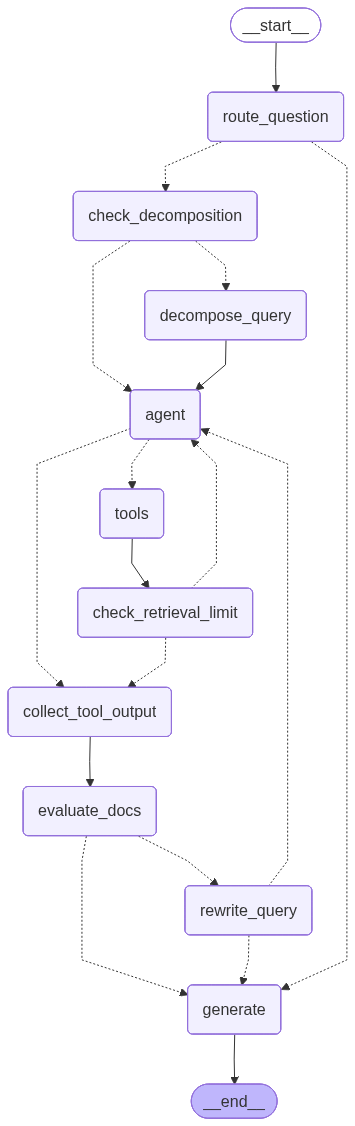

In [26]:
graph

In [27]:
# Case 1: simple query — expect no decomposition, query unchanged
query_1 = (
    "According to the report, by how many million barrels per day could a 300-million EV fleet "
    "displace oil demand by 2030?"
)

result_1 = graph.invoke({
    "query": query_1,
    "messages": [],
    "retrieved_docs": [],
    "relevant_docs": [],
    "context": "",
    "retrieval_count": 0,
    "max_retrieval_steps": 3,
    "rewrite_count": 0,
    "rewritten_query": "",
})

print("=== Case 1: Simple query — no decomposition ===")
print("Final query:", result_1.get("query"))
print("Is relevant:", result_1.get("is_relevant"))
print("Relevant docs count:", len(result_1.get("relevant_docs") or []))
print("\nGeneration:\n", result_1.get("generation"))

=== Case 1: Simple query — no decomposition ===
Final query: According to the report, by how many million barrels per day could a 300-million EV fleet displace oil demand by 2030?
Is relevant: True
Relevant docs count: 1

Generation:
 About 4.6 million barrels per day.


In [ ]:
# Case 2: complex multi-part query — expect decomposition into numbered steps

query_2 = (
    "Impact of EVs on the oil industry, "
    "and what is the current price of oil in US dollars for Brent Crude"
)

result_2 = graph.invoke({
    "query": query_2,
    "messages": [],
    "retrieved_docs": [],
    "relevant_docs": [],
    "context": "",
    "retrieval_count": 0,
    "max_retrieval_steps": 10,
    "rewrite_count": 0,
    "rewritten_query": "",
})

print("=== Case 2: Complex query — decomposition expected ===")
print("Final query (after decomposition):\n", result_2.get("query"))
print("\nIs relevant:", result_2.get("is_relevant"))
print("Relevant docs count:", len(result_2.get("relevant_docs") or []))
print("Retrieval count:", result_2.get("retrieval_count"))
print("\nGeneration:\n", result_2.get("generation"))

=== Case 2: Complex query — decomposition expected ===
Final query (after decomposition):
 Step 1: What has been the historical impact of electric vehicle (EV) adoption on global oil demand over the past 5–10 years (annual figures and percent change), citing authoritative sources (IEA, BP, etc.)?
Step 2: What do major energy outlooks and scenarios (IEA Net Zero, IEA Stated Policies, BP Energy Outlook, OPEC, etc.) project for future oil demand reductions specifically attributable to EV adoption through 2030 and 2040 (quantified in million barrels per day)?
Step 3: How has increasing EV adoption affected gasoline and diesel consumption trends (vehicle-km traveled, fuel-economy-adjusted consumption) in major markets (US, EU, China)?
Step 4: What measurable impacts are EVs having on oil industry finances and operations: revenues, upstream capital expenditures, and investment in new exploration and production (with recent examples or company statements)?
Step 5: How is EV growth affecting r

## 5.7 Agentic Rag

*Source: `10_agentic_rag/notebooks/agentic_rag.ipynb`*

In [2]:
import os
from typing import Literal
from pydantic import BaseModel
from tavily import TavilyClient
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_chroma import Chroma
from langchain_core.documents import Document
from langgraph.graph import StateGraph, START, END, MessagesState
from langgraph.prebuilt import ToolNode
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
loader = PyPDFLoader("../documents/evs_oil_price_shock.pdf")

raw_docs = loader.load()
print(f"Loaded {len(raw_docs)} pages")

Loaded 15 pages


In [4]:
splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150)

chunks = splitter.split_documents(raw_docs)
print(f"Split into {len(chunks)} chunks")

Split into 51 chunks


In [5]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

In [6]:
vectorstore = Chroma(
    collection_name="rag_dynamic_prompt",
    embedding_function=embeddings,
)

vectorstore.add_documents(documents=chunks)
print("Vector store ready")

Vector store ready


In [7]:
llm = ChatOpenAI(model="gpt-5-mini")

agent_llm = ChatOpenAI(model="gpt-5-mini")

In [8]:
class AgenticRAGState(MessagesState):

    query: str
    retrieved_docs: list[Document]
    relevant_docs: list[Document]
    context: str
    constructed_prompt: str
    generation: str
    needs_retrieval: bool
    retrieval_count: int
    max_retrieval_steps: int
    is_relevant: bool
    rewritten_query: str
    rewrite_count: int
    needs_decomposition: bool

In [9]:
class RouteDecision(BaseModel):
    needs_retrieval: bool

In [10]:
class RelevanceEvaluation(BaseModel):
    is_relevant: bool

In [11]:
class DecompositionDecision(BaseModel):
    needs_decomposition: bool
    sub_queries: list[str]  # empty list when needs_decomposition=False

In [12]:
@tool(response_format="content_and_artifact")
def vector_store_search(query: str, k: int = 3):
    """Search the vector store for relevant document passages.
    Adjust k (default 3) to retrieve more or fewer passages."""

    docs = vectorstore.similarity_search(query, k=k)
    context = "\n\n## Vector Store Results\n\n" + "\n\n".join(d.page_content for d in docs)

    return context, docs

In [13]:
@tool(response_format="content_and_artifact")
def web_search(query: str, max_results: int = 3):
    """Search the web for current or real-time information.
    Adjust max_results (default 3) to control how many results are returned."""
    client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

    response = client.search(query, max_results=max_results)

    docs = [
        Document(
            page_content=r["content"],
            metadata={"source": r["url"], "title": r.get("title", "")},
        )
        for r in response["results"]
    ]

    content = "\n\n## Web Search Results\n\n" + "\n\n".join(d.page_content for d in docs)
    return content, docs

In [14]:
tools = [vector_store_search, web_search]

agent_llm_with_tools = agent_llm.bind_tools(tools)

tool_node = ToolNode(tools)

In [15]:
def check_decomposition(state: AgenticRAGState) -> dict:
    prompt_template = ChatPromptTemplate.from_messages([
        (
            "system",
            "You are a query analysis assistant. Determine if the user's question asks for "
            "multiple distinct pieces of information that each require separate retrieval. "
            "If yes, needs_decomposition should be True. "
            "If the question is simple or self-contained, needs_decomposition should be False."
        ),
        ("human", "{query}"),
    ])

    chain = prompt_template | llm.with_structured_output(DecompositionDecision)
    result = chain.invoke({"query": state["query"]})

    return {"needs_decomposition": result.needs_decomposition}

In [17]:
def decompose_query(state: AgenticRAGState) -> dict:
    prompt_template = ChatPromptTemplate.from_messages([
        (
            "system",
            "You are a query decomposition assistant. Break the user's question into focused, "
            "self-contained sub-queries — one per retrieval step. Each sub-query should target "
            "a single distinct piece of information."
        ),
        ("human", "{query}"),
    ])

    chain = prompt_template | llm.with_structured_output(DecompositionDecision)
    result = chain.invoke({"query": state["query"]})

    steps = "\n".join(f"Step {i+1}: {q}" for i, q in enumerate(result.sub_queries))
    
    formatted = (
        f"You must call a retrieval tool for each of the following {len(result.sub_queries)} steps "
        f"before answering. Do not skip any step.\n\n{steps}"
    )

    return {"query": formatted}

In [18]:
def route_question(state: AgenticRAGState) -> dict:
    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Classify whether the following question requires retrieving information from a specialized document or the web, or can be answered from your own general knowledge."),
        ("human", "{query}"),
    ])

    chain = prompt_template | llm.with_structured_output(RouteDecision)
    decision = chain.invoke({"query": state["query"]})

    return {"needs_retrieval": decision.needs_retrieval}

In [19]:
AGENT_SYSTEM_PROMPT = (
    "You are a retrieval agent with access to two tools:\n\n"
    "1. vector_store_search — use this for questions that can be answered from the internal document: "
    "a technical report titled 'Will EVs Dampen the Oil Price Shock?' covering EV adoption trajectories, "
    "oil demand displacement scenarios, fleet turnover dynamics, battery cost trends, OPEC+ supply behavior, "
    "and energy price volatility projections through 2050. "
    "Use this tool whenever the query references the report, its findings, its projections, or any topic "
    "that would plausibly appear in a domain-specific EV/oil-market research document. "
    "You may increase k beyond the default if broader coverage of the document is needed.\n\n"
    "2. web_search — use this for current or real-time information not covered by the document, such as "
    "recent market data, news, or statistics from 2024 onward. "
    "Always rephrase the query into a concise, keyword-optimized web search string before calling this tool.\n\n"
    "You may call one tool, both tools, or no tool depending on what the query requires. "
    "When both document knowledge and current data are relevant, call both tools.\n\n"
    "When the query contains numbered steps (e.g. Step 1: ..., Step 2: ...), each step is a separate "
    "retrieval sub-task. Make sure every step receives at least one retrieval call — do not skip or "
    "overlook any step. For each step, choose whichever tool or combination of tools best fits the "
    "information need; the retrieval path for each step is yours to decide."
)

def agent(state: AgenticRAGState) -> dict:
    # use rewritten_query if available to start a fresh retrieval cycle
    rewritten = state.get("rewritten_query")

    if rewritten:
        messages = [
            SystemMessage(content=AGENT_SYSTEM_PROMPT),
            HumanMessage(content=rewritten),
        ]
    else:
        messages = state["messages"]
        if not messages:
            messages = [
                SystemMessage(content=AGENT_SYSTEM_PROMPT),
                HumanMessage(content=state["query"]),
            ]

    response = agent_llm_with_tools.invoke(messages)
    return {"messages": [response]}

In [20]:
def collect_tool_output(state: AgenticRAGState) -> dict:
    all_docs = []
    for msg in reversed(state["messages"]):
        if isinstance(msg, HumanMessage):
            break
        if isinstance(msg, ToolMessage):
            all_docs.extend(msg.artifact)
    all_docs.reverse()
    return {"retrieved_docs": all_docs}

In [21]:
def evaluate_docs(state: AgenticRAGState) -> dict:
    docs = state.get("retrieved_docs") or []
    if not docs:
        return {"is_relevant": False, "relevant_docs": [], "context": ""}

    active_query = state.get("rewritten_query") or state["query"]

    prompt_template = ChatPromptTemplate.from_messages([
        (
            "system",
            "You are a relevance evaluator. Given a user query and a single document passage, "
            "determine whether the passage contains useful information to answer the query. "
            "Return is_relevant=True only if the passage directly addresses the query with specific facts or analysis. "
            "Return is_relevant=False if it is off-topic, too vague, or does not help answer the query."
        ),
        ("human", "Query: {query}\n\nDocument passage:\n{doc}"),
    ])
    
    chain = prompt_template | llm.with_structured_output(RelevanceEvaluation)

    relevant_docs = []
    for doc in docs:
        result = chain.invoke({"query": active_query, "doc": doc.page_content})
        if result.is_relevant:
            relevant_docs.append(doc)

    is_relevant = len(relevant_docs) > 0
    context = "\n\n".join(d.page_content for d in relevant_docs)

    return {"is_relevant": is_relevant, "relevant_docs": relevant_docs, "context": context}

In [22]:
def rewrite_query(state: AgenticRAGState) -> dict:
    count = state.get("rewrite_count", 0)

    prompt_template = ChatPromptTemplate.from_messages([
        (
            "system",
            "You are a query rewriting assistant. A retrieval system searched for information to answer the user's "
            "query but none of the retrieved documents were relevant. Your task is to rewrite the query to be more "
            "specific, use different terminology, or focus on a narrower aspect that is more likely to match "
            "content in the knowledge source. Return only the rewritten query string."
        ),
        ("human", "Original query: {query}\n\nRewritten query:"),
    ])
    
    chain = prompt_template | llm
    response = chain.invoke({"query": state["query"]})
    
    new_query = response.content.strip()

    return {"rewritten_query": new_query, "rewrite_count": count + 1}

In [27]:
def build_prompt(state: AgenticRAGState) -> dict:
    rewrite_count = state.get("rewrite_count", 0)
    is_relevant = state.get("is_relevant", False)

    if rewrite_count >= 3 and not is_relevant:
        return {"constructed_prompt": "FALLBACK"}

    sections = ["You are a knowledgeable assistant."]

    if state.get("needs_decomposition"):
        sections.append(
            "The question was complex and split into sub-queries for retrieval. "
            "Synthesize a single coherent answer covering all parts."
        )

    if state.get("rewritten_query"):
        sections.append("The original query was reformulated during retrieval to improve result quality.")

    context = state.get("context") or ""
    relevant_docs = state.get("relevant_docs") or []

    if context:
        web_docs = [d for d in relevant_docs if d.metadata.get("source", "").startswith("http")]
        pdf_docs = [d for d in relevant_docs if not d.metadata.get("source", "").startswith("http")]

        if web_docs and pdf_docs:
            sections.append("Answer using the following context from the internal document and web search:")
        elif web_docs:
            sections.append("Answer using the following context from web search:")
        else:
            sections.append("Answer using the following context from the internal document:")

        sections.append(f"Context:\n{context}")

        if web_docs:
            urls = "\n".join(f"- {d.metadata['source']}" for d in web_docs)
            sections.append(f"Sources:\n{urls}")
    else:
        sections.append("No relevant documents were found. Answer from your general knowledge if possible.")

    return {"constructed_prompt": "\n\n".join(sections)}

In [28]:
def generate(state: AgenticRAGState) -> dict:
    if state.get("constructed_prompt") == "FALLBACK":
        return {
            "generation": (
                "I was unable to find relevant information to answer your query after multiple retrieval attempts. "
                "The knowledge source does not appear to contain content that addresses this question."
            )
        }

    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "{constructed_prompt}"),
        ("human", "{query}"),
    ])
    response = (prompt_template | llm).invoke({
        "constructed_prompt": state["constructed_prompt"],
        "query": state["query"],
    })
    return {"generation": response.content}

In [29]:
def check_retrieval_limit(state: AgenticRAGState) -> dict:
    count = state.get("retrieval_count", 0)
    return {"retrieval_count": count + 1}

In [30]:
def route_after_classification(state: AgenticRAGState) -> Literal["check_decomposition", "build_prompt"]:
    return "check_decomposition" if state["needs_retrieval"] else "build_prompt"

def route_after_decomposition_check(state: AgenticRAGState) -> Literal["decompose_query", "agent"]:
    return "decompose_query" if state["needs_decomposition"] else "agent"

def route_after_agent(state: AgenticRAGState) -> Literal["tools", "collect_tool_output"]:
    return "tools" if state["messages"][-1].tool_calls else "collect_tool_output"

def route_after_limit_check(state: AgenticRAGState) -> Literal["agent", "collect_tool_output"]:
    return "collect_tool_output" if state["retrieval_count"] >= state["max_retrieval_steps"] else "agent"

def route_after_evaluation(state: AgenticRAGState) -> Literal["build_prompt", "rewrite_query"]:
    return "build_prompt" if state["is_relevant"] else "rewrite_query"

def route_after_rewrite(state: AgenticRAGState) -> Literal["agent", "build_prompt"]:
    return "build_prompt" if state.get("rewrite_count", 0) >= 3 else "agent"

In [31]:
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("route_question", route_question)
graph_builder.add_node("check_decomposition", check_decomposition)
graph_builder.add_node("decompose_query", decompose_query)
graph_builder.add_node("agent", agent)
graph_builder.add_node("tools", tool_node)
graph_builder.add_node("check_retrieval_limit", check_retrieval_limit)
graph_builder.add_node("collect_tool_output", collect_tool_output)
graph_builder.add_node("evaluate_docs", evaluate_docs)
graph_builder.add_node("rewrite_query", rewrite_query)
graph_builder.add_node("build_prompt", build_prompt)
graph_builder.add_node("generate", generate)

graph_builder.add_edge(START, "route_question")
graph_builder.add_conditional_edges("route_question", route_after_classification)
graph_builder.add_conditional_edges("check_decomposition", route_after_decomposition_check)
graph_builder.add_edge("decompose_query", "agent")
graph_builder.add_conditional_edges("agent", route_after_agent)
graph_builder.add_edge("tools", "check_retrieval_limit")
graph_builder.add_conditional_edges("check_retrieval_limit", route_after_limit_check)
graph_builder.add_edge("collect_tool_output", "evaluate_docs")
graph_builder.add_conditional_edges("evaluate_docs", route_after_evaluation)
graph_builder.add_conditional_edges("rewrite_query", route_after_rewrite)
graph_builder.add_edge("build_prompt", "generate")
graph_builder.add_edge("generate", END)

In [32]:
graph = graph_builder.compile()

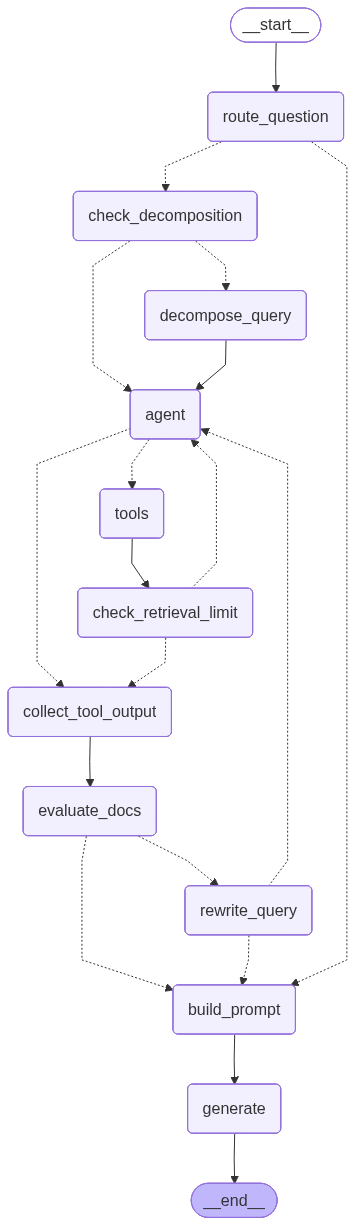

In [33]:
graph

In [27]:
# Case 1: simple query — PDF source, no decomposition
query_1 = (
    "According to the report, by how many million barrels per day could a 300-million EV fleet "
    "displace oil demand by 2030?"
)

result_1 = graph.invoke({
    "query": query_1,
    "messages": [],
    "retrieved_docs": [],
    "relevant_docs": [],
    "context": "",
    "constructed_prompt": "",
    "retrieval_count": 0,
    "max_retrieval_steps": 3,
    "rewrite_count": 0,
    "rewritten_query": "",
})

print("=== Case 1: Simple query — no decomposition ===")
print("Is relevant:", result_1.get("is_relevant"))
print("Relevant docs count:", len(result_1.get("relevant_docs") or []))
print("\nConstructed prompt:\n", result_1.get("constructed_prompt"))
print("\nGeneration:\n", result_1.get("generation"))

=== Case 1: Simple query — no decomposition ===
Is relevant: True
Relevant docs count: 1

Constructed prompt:
 You are a knowledgeable assistant.

Answer using the following context from the internal document:

Context:
longer in developing markets — complete fleet electrification cannot occur in less than two to
three decades even under the most aggressive adoption scenarios. This fleet inertia is the
primary reason why even optimistic EV projections show only modest oil demand
displacement through 2030, with the major effects occurring in the 2030–2050 window.
 Under a high-adoption scenario broadly consistent with the IEA's Net Zero by 2050
pathway, the global EV stock reaches approximately 300 million vehicles by 2030 and 900
million by 2035. Each EV on the road displaces roughly 560 liters of gasoline per year on
average, equivalent to approximately 1 barrel of oil per month per vehicle. A fleet of 300
million EVs would therefore displace approximately 4.6 million barrels of oil p

In [35]:
# Case 2: complex multi-part query — decomposition expected
query_2 = (
    "According to the report, how much have battery pack costs fallen over the past decade, "
    "and what is the current weather in Delhi"
)

result_2 = graph.invoke({
    "query": query_2,
    "messages": [],
    "retrieved_docs": [],
    "relevant_docs": [],
    "context": "",
    "constructed_prompt": "",
    "retrieval_count": 0,
    "max_retrieval_steps": 6,
    "rewrite_count": 0,
    "rewritten_query": "",
})

print("=== Case 2: Complex query — decomposition expected ===")
print("Final query (after decomposition):\n", result_2.get("query"))
print("\nIs relevant:", result_2.get("is_relevant"))
print("Relevant docs count:", len(result_2.get("relevant_docs") or []))
print("Retrieval count:", result_2.get("retrieval_count"))
print("\nConstructed prompt:\n", result_2.get("constructed_prompt"))
print("\nGeneration:\n", result_2.get("generation"))

=== Case 2: Complex query — decomposition expected ===
Final query (after decomposition):
 You must call a retrieval tool for each of the following 3 steps before answering. Do not skip any step.

Step 1: Ask the user to clarify which report they mean (give the report title, author, or a link) so the correct source can be used.
Step 2: From the specified report, extract the stated change in battery pack costs over the past decade (give the numeric decline and any units or percentage reported).
Step 3: Get the current weather in Delhi, India right now (include temperature, precipitation/conditions, and wind).

Is relevant: True
Relevant docs count: 10
Retrieval count: 6

Constructed prompt:
 You are a knowledgeable assistant.

The question was complex and split into sub-queries for retrieval. Synthesize a single coherent answer covering all parts.

The original query was reformulated during retrieval to improve result quality.

Answer using the following context from the internal docume